In [67]:
import urllib.request

try:
    urllib.request.urlopen("https://pypi.org/simple/pingouin/", timeout=10)
    print("Internet access to PyPI is working.")
except Exception as e:
    print("Internet/package access failed:", repr(e))

Internet access to PyPI is working.


In [68]:
%pip show pingouin

Note: you may need to restart the kernel to use updated packages.


In [69]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    for name in files[:5]:
        print("  ", name)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jakeshbohaju
/kaggle/input/datasets/jakeshbohaju/brain-tumor
   Brain Tumor.csv
   bt_dataset_t3.csv
/kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor
/kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor/Brain Tumor
   Image1.jpg
   Image10.jpg
   Image100.jpg
   Image1000.jpg
   Image1001.jpg


In [70]:
import os

print("Kaggle input available:", os.path.exists("/kaggle/input"))
if os.path.exists("/kaggle/input"):
    print(os.listdir("/kaggle/input"))

Kaggle input available: True
['datasets']


In [71]:
import os
import pandas as pd
import numpy as np

# Find the CSV already attached to your Kaggle notebook
matches = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "brain tumor.csv":
            matches.append(os.path.join(root, file))

if not matches:
    raise FileNotFoundError(
        "Brain Tumor.csv not found. Check that the dataset is attached "
        "to this Kaggle notebook using Add Input."
    )

CSV_PATH = matches[0]
df = pd.read_csv(CSV_PATH)

print("Loaded file:", CSV_PATH)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Loaded file: /kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor.csv
Dataset shape: (3762, 15)

Column names:
['Image', 'Class', 'Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation', 'Coarseness']


,Image,Class,Mean,Variance,Standard Deviation,Entropy,Skewness,Kurtosis,Contrast,Energy,ASM,Homogeneity,Dissimilarity,Correlation,Coarseness
0,Image1,0,6.535339,619.587845,24.891522,0.109059,4.276477,18.900575,98.613971,0.293314,0.086033,0.530941,4.473346,0.981939,7.458341e-155
1,Image2,0,8.749969,805.957634,28.389393,0.266538,3.718116,14.464618,63.858816,0.475051,0.225674,0.651352,3.220072,0.988834,7.458341e-155
2,Image3,1,7.341095,1143.808219,33.820234,0.001467,5.061750,26.479563,81.867206,0.031917,0.001019,0.268275,5.981800,0.978014,7.458341e-155
3,Image4,1,5.958145,959.711985,30.979219,0.001477,5.677977,33.428845,151.229741,0.032024,0.001026,0.243851,7.700919,0.964189,7.458341e-155
4,Image5,0,7.315231,729.540579,27.010009,0.146761,4.283221,19.079108,174.988756,0.343849,0.118232,0.501140,6.834689,0.972789,7.458341e-155


In [72]:
# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Image', 'Class', 'Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation', 'Coarseness']


In [40]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3762 entries, 0 to 3761
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Image               3762 non-null   object 
 1   Class               3762 non-null   int64  
 2   Mean                3762 non-null   float64
 3   Variance            3762 non-null   float64
 4   Standard Deviation  3762 non-null   float64
 5   Entropy             3762 non-null   float64
 6   Skewness            3762 non-null   float64
 7   Kurtosis            3762 non-null   float64
 8   Contrast            3762 non-null   float64
 9   Energy              3762 non-null   float64
 10  ASM                 3762 non-null   float64
 11  Homogeneity         3762 non-null   float64
 12  Dissimilarity       3762 non-null   float64
 13  Correlation         3762 non-null   float64
 14  Coarseness          3762 non-null   float64
dtypes: float64(13), int64(1), object(1)
memory usage: 441.0

In [41]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Image                 0
Class                 0
Mean                  0
Variance              0
Standard Deviation    0
Entropy               0
Skewness              0
Kurtosis              0
Contrast              0
Energy                0
ASM                   0
Homogeneity           0
Dissimilarity         0
Correlation           0
Coarseness            0
dtype: int64


In [42]:
if "Class" in df.columns:
    print(df["Class"].value_counts())
else:
    print("The class column is not named 'Class'.")

Class
0    2079
1    1683
Name: count, dtype: int64


In [73]:
feature_cols = [
    'Mean',
    'Variance',
    'Standard Deviation',
    'Entropy',
    'Skewness',
    'Kurtosis',
    'Contrast',
    'Energy',
    'ASM',
    'Homogeneity',
    'Dissimilarity',
    'Correlation',
    'Coarseness'
]

In [74]:
missing_features = [
    feature for feature in feature_cols
    if feature not in df.columns
]

if len(missing_features) == 0:
    print("All expected features are available.")
else:
    print("Missing features:", missing_features)

All expected features are available.


In [75]:
df_features = df[feature_cols].copy()

# Convert all feature columns to numeric values
for col in feature_cols:
    df_features[col] = pd.to_numeric(
        df_features[col],
        errors="coerce"
    )

# Remove rows with missing feature values
df_features = df_features.dropna().reset_index(drop=True)

print("Cleaned feature matrix shape:", df_features.shape)
display(df_features.head())

Cleaned feature matrix shape: (3762, 13)


,Mean,Variance,Standard Deviation,Entropy,Skewness,Kurtosis,Contrast,Energy,ASM,Homogeneity,Dissimilarity,Correlation,Coarseness
0,6.535339,619.587845,24.891522,0.109059,4.276477,18.900575,98.613971,0.293314,0.086033,0.530941,4.473346,0.981939,7.458341e-155
1,8.749969,805.957634,28.389393,0.266538,3.718116,14.464618,63.858816,0.475051,0.225674,0.651352,3.220072,0.988834,7.458341e-155
2,7.341095,1143.808219,33.820234,0.001467,5.061750,26.479563,81.867206,0.031917,0.001019,0.268275,5.981800,0.978014,7.458341e-155
3,5.958145,959.711985,30.979219,0.001477,5.677977,33.428845,151.229741,0.032024,0.001026,0.243851,7.700919,0.964189,7.458341e-155
4,7.315231,729.540579,27.010009,0.146761,4.283221,19.079108,174.988756,0.343849,0.118232,0.501140,6.834689,0.972789,7.458341e-155


In [46]:
display(df_features.describe().T)

,count,mean,std,min,25%,50%,75%,max
Mean,3762.0,9.488890e+00,5.728022,7.865906e-02,4.982395e+00,8.477531e+00,1.321272e+01,3.323997e+01
Variance,3762.0,7.111011e+02,467.466896,3.145628e+00,3.632255e+02,6.225804e+02,9.669543e+02,2.910582e+03
Standard Deviation,3762.0,2.518227e+01,8.773526,1.773592e+00,1.905847e+01,2.495156e+01,3.109589e+01,5.394981e+01
Entropy,3762.0,7.360262e-02,0.070269,8.815796e-04,6.856456e-03,6.662805e-02,1.132844e-01,3.945386e-01
Skewness,3762.0,4.102727e+00,2.560940,1.886014e+00,2.620203e+00,3.422210e+00,4.651737e+00,3.693129e+01
Kurtosis,3762.0,2.438907e+01,56.434747,3.942402e+00,7.252852e+00,1.235909e+01,2.264030e+01,1.371640e+03
Contrast,3762.0,1.279615e+02,109.499601,3.194733e+00,7.212521e+01,1.067374e+02,1.610590e+02,3.382574e+03
Energy,3762.0,2.047051e-01,0.129352,2.473117e-02,6.961745e-02,2.254965e-01,2.989014e-01,5.896818e-01
ASM,3762.0,5.863159e-02,0.058300,6.116308e-04,4.846590e-03,5.084867e-02,8.934206e-02,3.477246e-01
Homogeneity,3762.0,4.792519e-01,0.127929,1.054898e-01,3.649727e-01,5.125512e-01,5.755566e-01,8.109208e-01


In [47]:
# Identify features with zero variance

feature_variance = df_features.var()

print("Feature variances:")
display(feature_variance)

zero_variance_features = feature_variance[
    feature_variance == 0
].index.tolist()

print("\nZero-variance features:")
print(zero_variance_features)

Feature variances:


Mean                      32.810234
Variance              218525.298564
Standard Deviation        76.974757
Entropy                    0.004938
Skewness                   6.558413
Kurtosis                3184.880670
Contrast               11990.162523
Energy                     0.016732
ASM                        0.003399
Homogeneity                0.016366
Dissimilarity              3.423139
Correlation                0.000684
Coarseness                 0.000000
dtype: float64


Zero-variance features:
['Coarseness']


In [48]:
# Remove zero-variance features

valid_features = [
    col for col in feature_cols
    if col not in zero_variance_features
]

df_features = df_features[valid_features].copy()

print("Features retained:", len(valid_features))
print(valid_features)

Features retained: 12
['Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation']


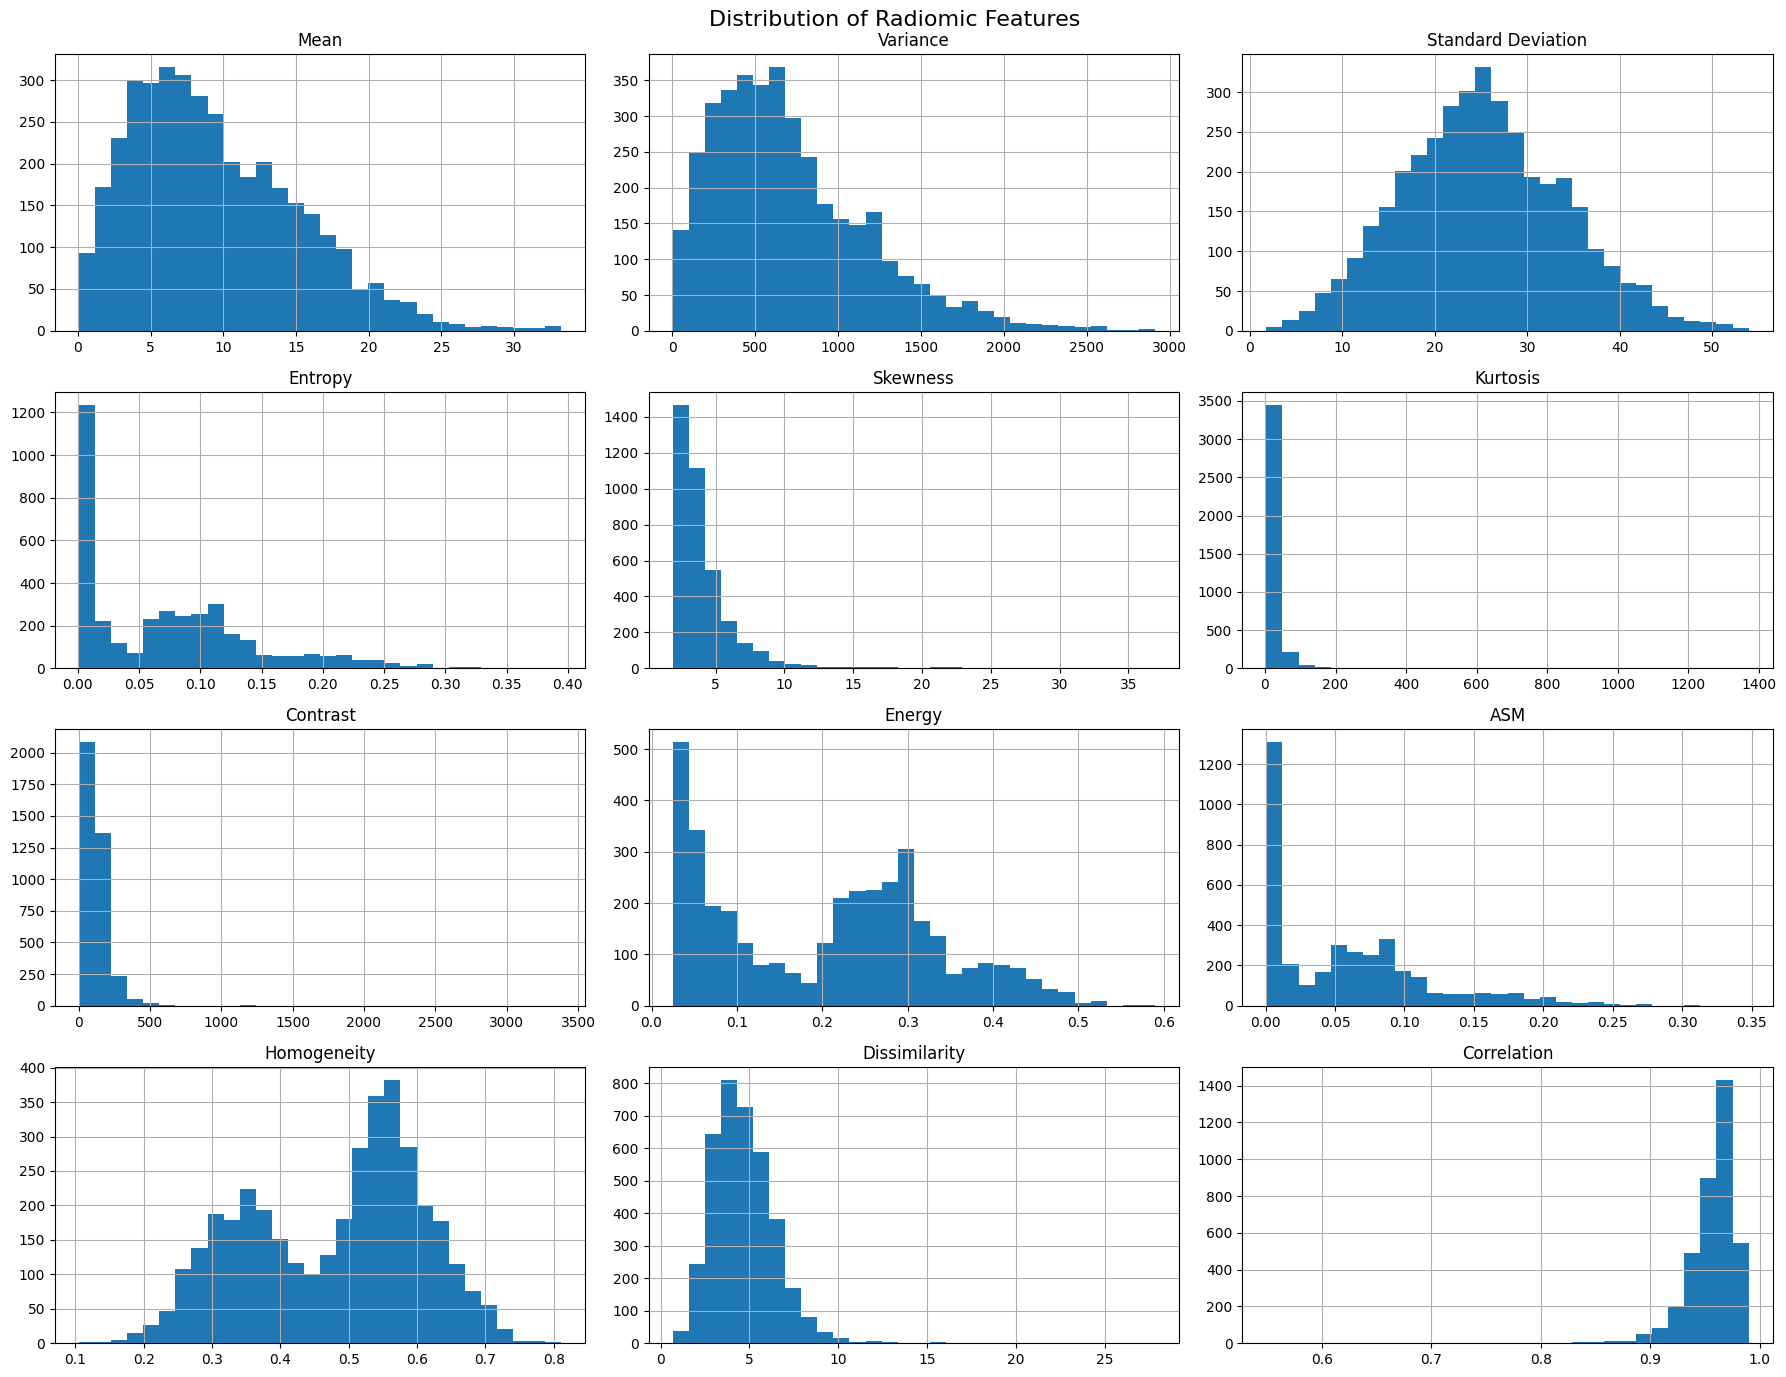

In [49]:
import matplotlib.pyplot as plt

df_features.hist(
    figsize=(18, 14),
    bins=30
)

plt.suptitle(
    "Distribution of Radiomic Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [76]:
feature_summary = pd.DataFrame({
    "Mean": df_features.mean(),
    "SD": df_features.std(),
    "Min": df_features.min(),
    "Max": df_features.max(),
    "Range": df_features.max() - df_features.min()
})

display(feature_summary)

,Mean,SD,Min,Max,Range
Mean,9.488890e+00,5.728022,7.865906e-02,3.323997e+01,3.316132e+01
Variance,7.111011e+02,467.466896,3.145628e+00,2.910582e+03,2.907436e+03
Standard Deviation,2.518227e+01,8.773526,1.773592e+00,5.394981e+01,5.217622e+01
Entropy,7.360262e-02,0.070269,8.815796e-04,3.945386e-01,3.936570e-01
Skewness,4.102727e+00,2.560940,1.886014e+00,3.693129e+01,3.504528e+01
Kurtosis,2.438907e+01,56.434747,3.942402e+00,1.371640e+03,1.367698e+03
Contrast,1.279615e+02,109.499601,3.194733e+00,3.382574e+03,3.379379e+03
Energy,2.047051e-01,0.129352,2.473117e-02,5.896818e-01,5.649506e-01
ASM,5.863159e-02,0.058300,6.116308e-04,3.477246e-01,3.471130e-01
Homogeneity,4.792519e-01,0.127929,1.054898e-01,8.109208e-01,7.054311e-01


In [51]:
print("Total rows:", len(df))

print(
    "Unique image IDs:",
    df["Image"].nunique()
)

print(
    "Duplicate image IDs:",
    df["Image"].duplicated().sum()
)

Total rows: 3762
Unique image IDs: 3762
Duplicate image IDs: 0


In [52]:
print(df["Image"].nunique())
print(df["Image"].duplicated().sum())

3762
0


In [53]:
display(
    pd.DataFrame({
        "Mean": df_features.mean(),
        "SD": df_features.std(),
        "Min": df_features.min(),
        "Max": df_features.max()
    })
)

,Mean,SD,Min,Max
Mean,9.488890,5.728022,0.078659,33.239975
Variance,711.101063,467.466896,3.145628,2910.581879
Standard Deviation,25.182271,8.773526,1.773592,53.949809
Entropy,0.073603,0.070269,0.000882,0.394539
Skewness,4.102727,2.560940,1.886014,36.931294
Kurtosis,24.389071,56.434747,3.942402,1371.640060
Contrast,127.961459,109.499601,3.194733,3382.574163
Energy,0.204705,0.129352,0.024731,0.589682
ASM,0.058632,0.058300,0.000612,0.347725
Homogeneity,0.479252,0.127929,0.105490,0.810921


In [54]:
import numpy as np
import pandas as pd

# Keep a clean copy of the 12 usable features
original_features = df_features.copy()

print("Number of observations:", len(original_features))
print("Number of features:", len(original_features.columns))
print("Features:")
print(original_features.columns.tolist())

Number of observations: 3762
Number of features: 12
Features:
['Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation']


In [77]:
def create_relative_perturbation(data, noise_level, seed=None):
    """
    Creates a perturbed version of the feature data.

    noise_level:
        0.02 = 2%
        0.05 = 5%
        0.10 = 10%

    The perturbation is proportional to the
    magnitude of each original observation.
    """

    rng = np.random.default_rng(seed)

    perturbed = data.copy()

    for col in data.columns:

        noise_factor = rng.normal(
            loc=0,
            scale=noise_level,
            size=len(data)
        )

        perturbed[col] = (
            data[col].values * (1 + noise_factor)
        )

    return perturbed

In [56]:
perturbed_5 = create_relative_perturbation(
    original_features,
    noise_level=0.05,
    seed=42
)

display(
    pd.DataFrame({
        "Original_Mean": original_features["Mean"].head(10).values,
        "Perturbed_Mean": perturbed_5["Mean"].head(10).values
    })
)

,Original_Mean,Perturbed_Mean
0,6.535339,6.634911
1,8.749969,8.294978
2,7.341095,7.616552
3,5.958145,6.238346
4,7.315231,6.601618
5,7.524109,7.034222
6,12.304413,12.383063
7,15.929474,15.677595
8,19.921616,19.904880
9,8.476196,8.114668


In [57]:
percentage_change = (
    (perturbed_5 - original_features)
    / original_features
) * 100

print("Percentage change summary:")
display(percentage_change.describe().T)

Percentage change summary:


,count,mean,std,min,25%,50%,75%,max
Mean,3762.0,-0.068770,4.999280,-18.242064,-3.394003,0.038003,3.213714,15.894268
Variance,3762.0,0.001447,5.033574,-21.945573,-3.353114,-0.087815,3.312155,17.270232
Standard Deviation,3762.0,-0.087253,5.060145,-17.646050,-3.392068,-0.173463,3.301296,20.129120
Entropy,3762.0,-0.035371,4.993486,-19.439022,-3.402672,-0.118587,3.278471,20.756207
Skewness,3762.0,0.157614,4.960094,-16.286838,-3.218027,0.128146,3.525066,16.001215
Kurtosis,3762.0,0.150618,5.042949,-18.500458,-3.278805,0.114427,3.547628,17.781814
Contrast,3762.0,0.210363,4.974222,-17.652046,-3.129430,0.257076,3.433356,16.637361
Energy,3762.0,0.015890,5.109088,-17.321817,-3.477608,0.018132,3.534294,18.412548
ASM,3762.0,0.026441,5.002612,-21.285046,-3.367445,-0.023611,3.337486,20.439615
Homogeneity,3762.0,-0.008808,4.984552,-17.988154,-3.365165,0.007482,3.361155,16.540297


In [58]:
print("Minimum values after perturbation:")
display(perturbed_5.min())

print("\nMaximum values after perturbation:")
display(perturbed_5.max())

Minimum values after perturbation:


Mean                  0.078065
Variance              3.039063
Standard Deviation    1.646651
Entropy               0.000827
Skewness              1.609547
Kurtosis              3.826923
Contrast              3.003192
Energy                0.024351
ASM                   0.000626
Homogeneity           0.098090
Dissimilarity         0.682347
Correlation           0.557453
dtype: float64


Maximum values after perturbation:


Mean                    34.368655
Variance              2912.720814
Standard Deviation      58.155479
Entropy                  0.382040
Skewness                35.223715
Kurtosis              1364.501672
Contrast              3321.348072
Energy                   0.579718
ASM                      0.369964
Homogeneity              0.822602
Dissimilarity           27.467740
Correlation              1.197428
dtype: float64

In [78]:
def create_constrained_perturbation(data, noise_level, seed=None):

    rng = np.random.default_rng(seed)

    perturbed = data.copy()

    for col in data.columns:

        noise_factor = rng.normal(
            loc=0,
            scale=noise_level,
            size=len(data)
        )

        new_values = (
            data[col].values * (1 + noise_factor)
        )

        # Apply theoretical bounds where appropriate
        if col in ["Energy", "ASM", "Homogeneity"]:
            new_values = np.clip(new_values, 0, 1)

        elif col == "Correlation":
            new_values = np.clip(new_values, -1, 1)

        elif col in ["Variance", "Standard Deviation", "Entropy",
                     "Contrast", "Kurtosis", "Dissimilarity"]:
            # These quantities cannot be negative
            new_values = np.maximum(new_values, 0)

        perturbed[col] = new_values

    return perturbed

In [79]:
perturbed_5 = create_constrained_perturbation(
    original_features,
    noise_level=0.05,
    seed=42
)

print("Minimum values:")
display(perturbed_5.min())

print("\nMaximum values:")
display(perturbed_5.max())

Minimum values:


Mean                  0.078065
Variance              3.039063
Standard Deviation    1.646651
Entropy               0.000827
Skewness              1.609547
Kurtosis              3.826923
Contrast              3.003192
Energy                0.024351
ASM                   0.000626
Homogeneity           0.098090
Dissimilarity         0.682347
Correlation           0.557453
dtype: float64


Maximum values:


Mean                    34.368655
Variance              2912.720814
Standard Deviation      58.155479
Entropy                  0.382040
Skewness                35.223715
Kurtosis              1364.501672
Contrast              3321.348072
Energy                   0.579718
ASM                      0.369964
Homogeneity              0.822602
Dissimilarity           27.467740
Correlation              1.000000
dtype: float64

In [61]:
percentage_change = (
    (perturbed_5 - original_features)
    / original_features
) * 100

display(
    percentage_change.describe().T
)

,count,mean,std,min,25%,50%,75%,max
Mean,3762.0,-0.068770,4.999280,-18.242064,-3.394003,0.038003,3.213714,15.894268
Variance,3762.0,0.001447,5.033574,-21.945573,-3.353114,-0.087815,3.312155,17.270232
Standard Deviation,3762.0,-0.087253,5.060145,-17.646050,-3.392068,-0.173463,3.301296,20.129120
Entropy,3762.0,-0.035371,4.993486,-19.439022,-3.402672,-0.118587,3.278471,20.756207
Skewness,3762.0,0.157614,4.960094,-16.286838,-3.218027,0.128146,3.525066,16.001215
Kurtosis,3762.0,0.150618,5.042949,-18.500458,-3.278805,0.114427,3.547628,17.781814
Contrast,3762.0,0.210363,4.974222,-17.652046,-3.129430,0.257076,3.433356,16.637361
Energy,3762.0,0.015890,5.109088,-17.321817,-3.477608,0.018132,3.534294,18.412548
ASM,3762.0,0.026441,5.002612,-21.285046,-3.367445,-0.023611,3.337486,20.439615
Homogeneity,3762.0,-0.008808,4.984552,-17.988154,-3.365165,0.007482,3.361155,16.540297


In [80]:
import numpy as np
import pandas as pd


def create_robust_perturbation(data, noise_level, seed=None):

    rng = np.random.default_rng(seed)

    perturbed = data.copy()

    for col in data.columns:

        values = data[col].values.astype(float)

        # --------------------------------------------------
        # 1. Correlation: Fisher z transformation
        # --------------------------------------------------
        if col == "Correlation":

            # Avoid exactly -1 or +1 before transformation
            clipped = np.clip(values, -0.999999, 0.999999)

            z = np.arctanh(clipped)

            # Perturb on Fisher-z scale
            z_noise = rng.normal(
                0,
                noise_level,
                size=len(values)
            )

            new_values = np.tanh(z + z_noise)

        # --------------------------------------------------
        # 2. Features bounded between 0 and 1
        # --------------------------------------------------
        elif col in ["Energy", "ASM", "Homogeneity"]:

            # Avoid exact 0 and 1 for logit transformation
            clipped = np.clip(values, 1e-6, 1 - 1e-6)

            logit_values = np.log(
                clipped / (1 - clipped)
            )

            logit_noise = rng.normal(
                0,
                noise_level,
                size=len(values)
            )

            new_values = 1 / (
                1 + np.exp(-(logit_values + logit_noise))
            )

        # --------------------------------------------------
        # 3. Positive, unbounded features
        # --------------------------------------------------
        else:

            noise_factor = rng.normal(
                0,
                noise_level,
                size=len(values)
            )

            new_values = values * (1 + noise_factor)

            # These features cannot be negative
            new_values = np.maximum(new_values, 0)

        perturbed[col] = new_values

    return perturbed

In [63]:
perturbed_5 = create_robust_perturbation(
    original_features,
    noise_level=0.05,
    seed=42
)

print("Minimum values:")
display(perturbed_5.min())

print("\nMaximum values:")
display(perturbed_5.max())

Minimum values:


Mean                  0.078065
Variance              3.039063
Standard Deviation    1.646651
Entropy               0.000827
Skewness              1.609547
Kurtosis              3.826923
Contrast              3.003192
Energy                0.024363
ASM                   0.000626
Homogeneity           0.099051
Dissimilarity         0.682347
Correlation           0.559544
dtype: float64


Maximum values:


Mean                    34.368655
Variance              2912.720814
Standard Deviation      58.155479
Entropy                  0.382040
Skewness                35.223715
Kurtosis              1364.501672
Contrast              3321.348072
Energy                   0.585587
ASM                      0.362368
Homogeneity              0.803950
Dissimilarity           27.467740
Correlation              0.990499
dtype: float64

In [64]:
from scipy.stats import spearmanr

correlation_results = []

for col in original_features.columns:

    rho, p_value = spearmanr(
        original_features[col],
        perturbed_5[col]
    )

    correlation_results.append({
        "Feature": col,
        "Spearman_Rho": rho,
        "P_value": p_value
    })

correlation_results = pd.DataFrame(
    correlation_results
)

display(
    correlation_results.sort_values(
        "Spearman_Rho"
    )
)

,Feature,Spearman_Rho,P_value
11,Correlation,0.973425,0.0
2,Standard Deviation,0.988694,0.0
10,Dissimilarity,0.989670,0.0
4,Skewness,0.990662,0.0
9,Homogeneity,0.993776,0.0
6,Contrast,0.996055,0.0
0,Mean,0.996883,0.0
7,Energy,0.997041,0.0
1,Variance,0.997075,0.0
5,Kurtosis,0.997373,0.0


In [65]:
absolute_error = (
    perturbed_5 - original_features
).abs()

error_summary = pd.DataFrame({
    "Mean_Absolute_Error":
        absolute_error.mean(),

    "Median_Absolute_Error":
        absolute_error.median(),

    "RMSE":
        np.sqrt(
            ((perturbed_5 - original_features) ** 2).mean()
        )
})

display(error_summary)

,Mean_Absolute_Error,Median_Absolute_Error,RMSE
Mean,0.372324,0.240717,0.545639
Variance,28.234695,18.193810,42.426934
Standard Deviation,1.008193,0.766727,1.335004
Entropy,0.002930,0.001171,0.005047
Skewness,0.164579,0.117119,0.244402
Kurtosis,0.964940,0.411928,2.707303
Contrast,4.971818,3.176748,7.827380
Energy,0.005916,0.003905,0.008357
ASM,0.002090,0.000847,0.003579
Homogeneity,0.009277,0.007843,0.011669


In [83]:
!pip install pingouin --no-deps -q
!pip install pandas-flavor tabulate outdated -q


In [84]:
import numpy as np
import pandas as pd
import scipy
import pingouin as pg

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Pingouin:", pg.__version__)

print("\nAll required imports successful.")

NumPy: 2.1.3
Pandas: 2.3.3
SciPy: 1.16.3
Pingouin: 0.7.0

All required imports successful.


In [85]:
import pingouin as pg

feature = "Mean"

temp = pd.DataFrame({
    "targets": list(range(len(original_features))) * 2,
    "raters": (
        ["Original"] * len(original_features)
        + ["Perturbed"] * len(original_features)
    ),
    "ratings": (
        list(original_features[feature])
        + list(perturbed_5[feature])
    )
})

icc_table = pg.intraclass_corr(
    data=temp,
    targets="targets",
    raters="raters",
    ratings="ratings"
)

display(icc_table)


,Type,ICC,F,df1,df2,pval,CI95
0,"ICC(1,1)",0.995489,442.381043,3761,3762,0.0,"[1.0, 1.0]"
1,"ICC(A,1)",0.995489,442.281120,3761,3761,0.0,"[1.0, 1.0]"
2,"ICC(C,1)",0.995488,442.281120,3761,3761,0.0,"[1.0, 1.0]"
3,"ICC(1,k)",0.997740,442.381043,3761,3762,0.0,"[1.0, 1.0]"
4,"ICC(A,k)",0.997740,442.281120,3761,3761,0.0,"[1.0, 1.0]"
5,"ICC(C,k)",0.997739,442.281120,3761,3761,0.0,"[1.0, 1.0]"


In [86]:
icc3_row = icc_table[
    icc_table["Type"] == "ICC(C,1)"
]

print("Selected ICC(C,1):")
print(icc3_row[["ICC", "F", "df1", "df2", "pval", "CI95"]])

Selected ICC(C,1):
        ICC          F   df1   df2  pval        CI95
2  0.995488  442.28112  3761  3761   0.0  [1.0, 1.0]


In [87]:
def calculate_icc_pingouin(original, perturbed):

    results = []

    for feature in original.columns:

        temp = pd.DataFrame({
            "targets": list(range(len(original))) * 2,
            "raters": (
                ["Original"] * len(original)
                + ["Perturbed"] * len(original)
            ),
            "ratings": (
                list(original[feature])
                + list(perturbed[feature])
            )
        })

        icc_table = pg.intraclass_corr(
            data=temp,
            targets="targets",
            raters="raters",
            ratings="ratings"
        )

        row = icc_table[
            icc_table["Type"] == "ICC(C,1)"
        ].iloc[0]

        results.append({
            "Feature": feature,
            "ICC_C1": row["ICC"],
            "CI95": row["CI95"]
        })

    return pd.DataFrame(results)

In [88]:
icc_test = calculate_icc_pingouin(
    original_features,
    perturbed_5
)

display(icc_test)

,Feature,ICC_C1,CI95
0,Mean,0.995488,"[1.0, 1.0]"
1,Variance,0.995884,"[1.0, 1.0]"
2,Standard Deviation,0.988551,"[0.99, 0.99]"
3,Entropy,0.997424,"[1.0, 1.0]"
4,Skewness,0.995465,"[1.0, 1.0]"
5,Kurtosis,0.998838,"[1.0, 1.0]"
6,Contrast,0.997436,"[1.0, 1.0]"
7,Energy,0.995483,"[1.0, 1.0]"
8,ASM,0.997402,"[1.0, 1.0]"
9,Homogeneity,0.981415,"[0.98, 0.98]"


In [89]:
perturbed_2 = create_robust_perturbation(
    original_features,
    noise_level=0.02,
    seed=42
)

perturbed_10 = create_robust_perturbation(
    original_features,
    noise_level=0.10,
    seed=42
)

icc_2 = calculate_icc_pingouin(
    original_features,
    perturbed_2
)

icc_10 = calculate_icc_pingouin(
    original_features,
    perturbed_10
)

comparison = pd.DataFrame({
    "Feature": icc_2["Feature"],
    "ICC_2%": icc_2["ICC_C1"],
    "ICC_5%": icc_test["ICC_C1"],
    "ICC_10%": icc_10["ICC_C1"]
})

display(comparison)

,Feature,ICC_2%,ICC_5%,ICC_10%
0,Mean,0.999275,0.995488,0.982216
1,Variance,0.999340,0.995884,0.983685
2,Standard Deviation,0.998151,0.988551,0.955706
3,Entropy,0.999587,0.997424,0.989760
4,Skewness,0.999272,0.995465,0.982086
5,Kurtosis,0.999815,0.998838,0.995319
6,Contrast,0.999590,0.997436,0.989762
7,Energy,0.999666,0.995483,0.991735
8,ASM,0.999699,0.997402,0.992473
9,Homogeneity,0.999334,0.981415,0.983630


In [90]:
import numpy as np
import pandas as pd

def fast_icc_c1(original, perturbed):
    """
    Calculate ICC(C,1) for two measurements
    of the same subjects.

    This is verified against Pingouin's ICC(C,1).
    """

    x = np.asarray(original, dtype=float)
    y = np.asarray(perturbed, dtype=float)

    n = len(x)

    # Two measurements per subject
    measurements = np.column_stack([x, y])

    # Subject means
    subject_means = measurements.mean(axis=1)

    # Grand mean
    grand_mean = measurements.mean()

    # Between-subject sum of squares
    ss_between = 2 * np.sum(
        (subject_means - grand_mean) ** 2
    )

    # Within-subject sum of squares
    ss_within = np.sum(
        (measurements - subject_means[:, None]) ** 2
    )

    # ICC(C,1)
    ms_between = ss_between / (n - 1)
    ms_within = ss_within / n

    icc = (
        ms_between - ms_within
    ) / (
        ms_between + ms_within
    )

    return icc


# Test on Mean at 5%
pingouin_value = icc_test.loc[
    icc_test["Feature"] == "Mean",
    "ICC_C1"
].values[0]

fast_value = fast_icc_c1(
    original_features["Mean"],
    perturbed_5["Mean"]
)

print("Pingouin ICC(C,1):", pingouin_value)
print("Fast ICC(C,1):    ", fast_value)
print("Difference:       ", abs(pingouin_value - fast_value))

Pingouin ICC(C,1): 0.9954881904319792
Fast ICC(C,1):     0.9954892072396341
Difference:        1.0168076548522365e-06


In [91]:
import numpy as np
import pandas as pd
from IPython.display import display

# --------------------------------------------------
# Fast ICC(C,1)
# --------------------------------------------------

def fast_icc_c1(original, perturbed):

    x = np.asarray(original, dtype=float)
    y = np.asarray(perturbed, dtype=float)

    n = len(x)

    measurements = np.column_stack([x, y])

    subject_means = measurements.mean(axis=1)
    grand_mean = measurements.mean()

    ss_between = 2 * np.sum(
        (subject_means - grand_mean) ** 2
    )

    ss_within = np.sum(
        (measurements - subject_means[:, None]) ** 2
    )

    ms_between = ss_between / (n - 1)
    ms_within = ss_within / n

    icc = (
        ms_between - ms_within
    ) / (
        ms_between + ms_within
    )

    return icc


# --------------------------------------------------
# Repeated simulation
# --------------------------------------------------

noise_levels = [0.02, 0.05, 0.10]

n_simulations = 100

results = []

for noise_level in noise_levels:

    print(f"Running {int(noise_level * 100)}% simulations...")

    for simulation in range(n_simulations):

        # Different random seed for every simulation
        seed = 1000 + simulation

        # Create perturbed dataset
        perturbed = create_robust_perturbation(
            original_features,
            noise_level=noise_level,
            seed=seed
        )

        # Calculate ICC for every feature
        for feature in original_features.columns:

            icc_value = fast_icc_c1(
                original_features[feature],
                perturbed[feature]
            )

            results.append({
                "Noise_Level": int(noise_level * 100),
                "Simulation": simulation + 1,
                "Feature": feature,
                "ICC_C1": icc_value
            })


# Convert to DataFrame
icc_simulation_results = pd.DataFrame(results)


# --------------------------------------------------
# Check results
# --------------------------------------------------

print("\nSimulation completed!")

print(
    "Total ICC observations:",
    len(icc_simulation_results)
)

display(
    icc_simulation_results.head(20)
)

Running 2% simulations...
Running 5% simulations...
Running 10% simulations...

Simulation completed!
Total ICC observations: 3600


,Noise_Level,Simulation,Feature,ICC_C1
0,2,1,Mean,0.999311
1,2,1,Variance,0.999342
2,2,1,Standard Deviation,0.998209
3,2,1,Entropy,0.999587
4,2,1,Skewness,0.999306
5,2,1,Kurtosis,0.999807
6,2,1,Contrast,0.999257
7,2,1,Energy,0.999688
8,2,1,ASM,0.999695
9,2,1,Homogeneity,0.999341


In [92]:
# Summary statistics for the repeated ICC simulations

icc_summary = (
    icc_simulation_results
    .groupby(["Noise_Level", "Feature"])["ICC_C1"]
    .agg(
        Mean="mean",
        Median="median",
        SD="std",
        Q2_5=lambda x: x.quantile(0.025),
        Q97_5=lambda x: x.quantile(0.975),
        Minimum="min",
        Maximum="max"
    )
    .reset_index()
)

# Round for easier reading
icc_summary_display = icc_summary.copy()

for col in [
    "Mean",
    "Median",
    "SD",
    "Q2_5",
    "Q97_5",
    "Minimum",
    "Maximum"
]:
    icc_summary_display[col] = (
        icc_summary_display[col].round(6)
    )

display(icc_summary_display)

,Noise_Level,Feature,Mean,Median,SD,Q2_5,Q97_5,Minimum,Maximum
0,2,ASM,0.999707,0.999707,0.000013,0.999683,0.999728,0.999675,0.999741
1,2,Contrast,0.999522,0.999537,0.000069,0.999363,0.999614,0.999257,0.999630
2,2,Correlation,0.997200,0.997234,0.000180,0.996823,0.997490,0.996487,0.997584
3,2,Dissimilarity,0.998508,0.998511,0.000049,0.998405,0.998590,0.998377,0.998618
4,2,Energy,0.999679,0.999679,0.000010,0.999658,0.999697,0.999654,0.999701
5,2,Entropy,0.999584,0.999585,0.000017,0.999551,0.999612,0.999548,0.999625
6,2,Homogeneity,0.999333,0.999334,0.000017,0.999298,0.999362,0.999274,0.999371
7,2,Kurtosis,0.999776,0.999785,0.000061,0.999649,0.999854,0.999401,0.999857
8,2,Mean,0.999251,0.999251,0.000026,0.999202,0.999304,0.999179,0.999319
9,2,Skewness,0.999291,0.999298,0.000044,0.999202,0.999360,0.999129,0.999381


In [93]:
# Create a table of median ICC values
icc_median = (
    icc_summary
    .pivot(
        index="Feature",
        columns="Noise_Level",
        values="Median"
    )
    .reset_index()
)

icc_median.columns.name = None

icc_median = icc_median.rename(columns={
    2: "ICC_2%",
    5: "ICC_5%",
    10: "ICC_10%"
})

# Calculate absolute ICC decrease from 2% to 10%
icc_median["ICC_Decrease_2_to_10"] = (
    icc_median["ICC_2%"] -
    icc_median["ICC_10%"]
)

# Sort by largest decrease
icc_median = icc_median.sort_values(
    "ICC_Decrease_2_to_10",
    ascending=False
)

display(
    icc_median.round(6)
)

,Feature,ICC_2%,ICC_5%,ICC_10%,ICC_Decrease_2_to_10
2,Correlation,0.997234,0.982825,0.932446,0.064788
10,Standard Deviation,0.998153,0.988571,0.955801,0.042353
3,Dissimilarity,0.998511,0.990758,0.963997,0.034514
8,Mean,0.999251,0.995333,0.981609,0.017642
9,Skewness,0.999298,0.995615,0.982626,0.016672
6,Homogeneity,0.999334,0.995853,0.983636,0.015698
11,Variance,0.999339,0.995884,0.983750,0.015589
1,Contrast,0.999537,0.997108,0.988546,0.010991
5,Entropy,0.999585,0.997410,0.989714,0.009871
4,Energy,0.999679,0.997997,0.992047,0.007632


Number of radiomic features: 12
Features:
['Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation']


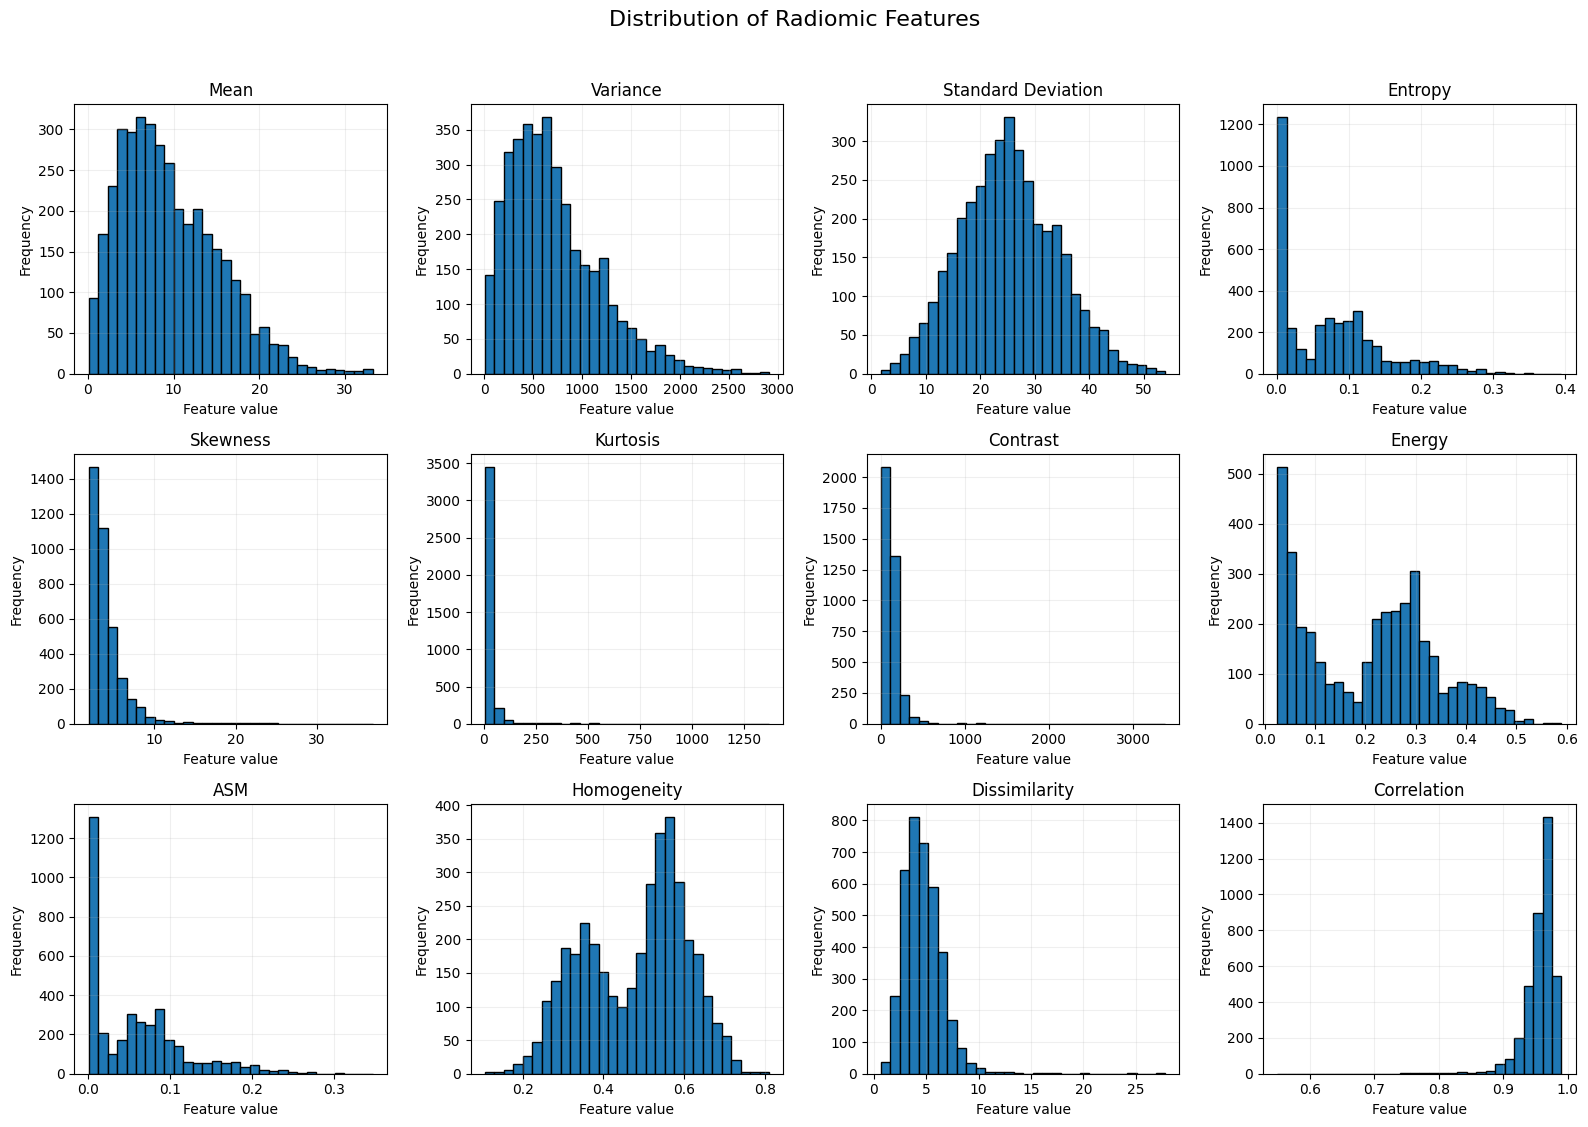

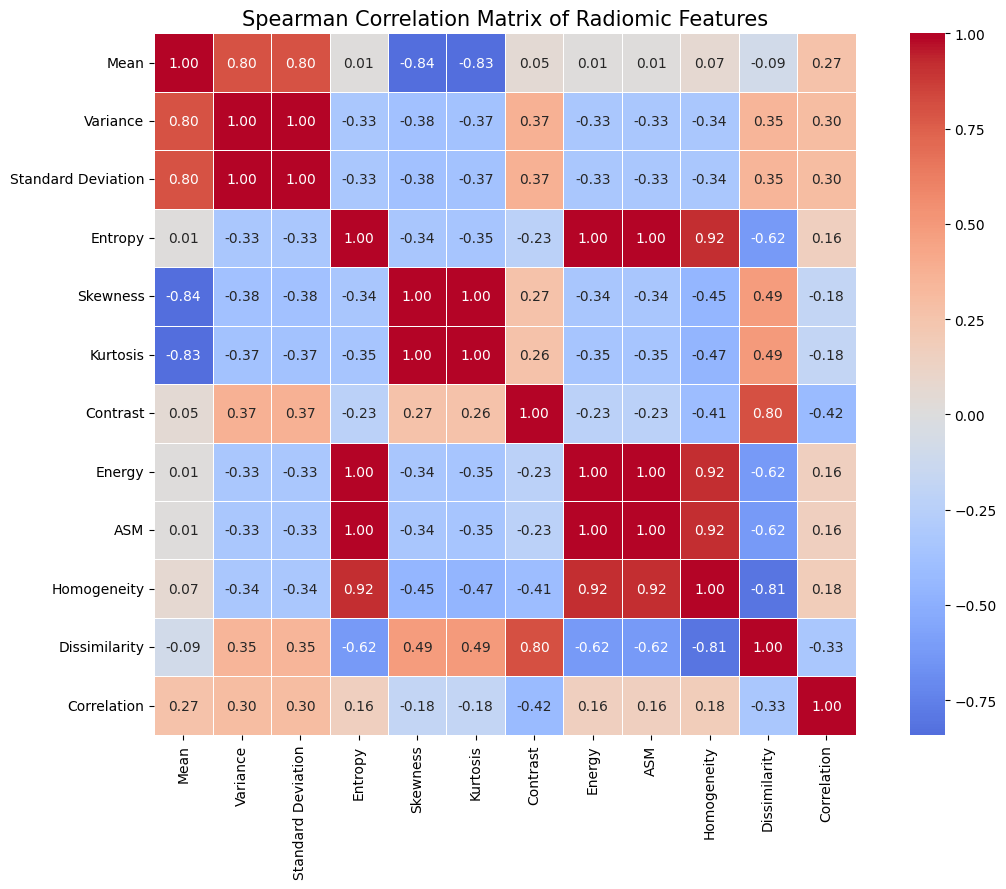

/tmp/ipykernel_48/2075709108.py:109: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


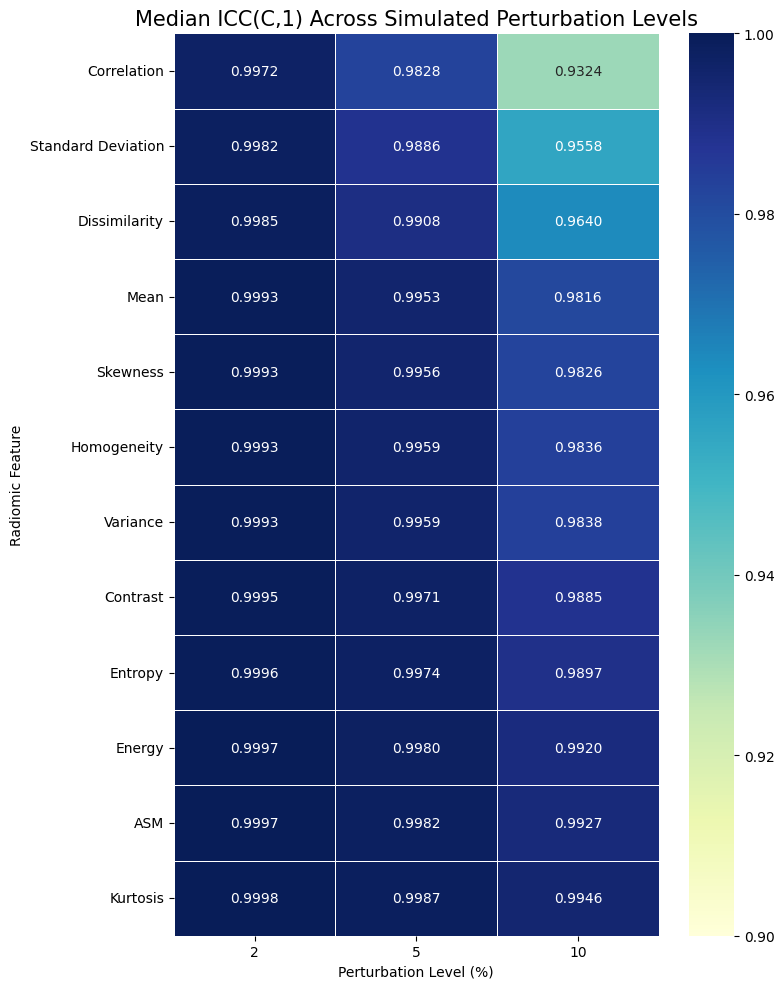

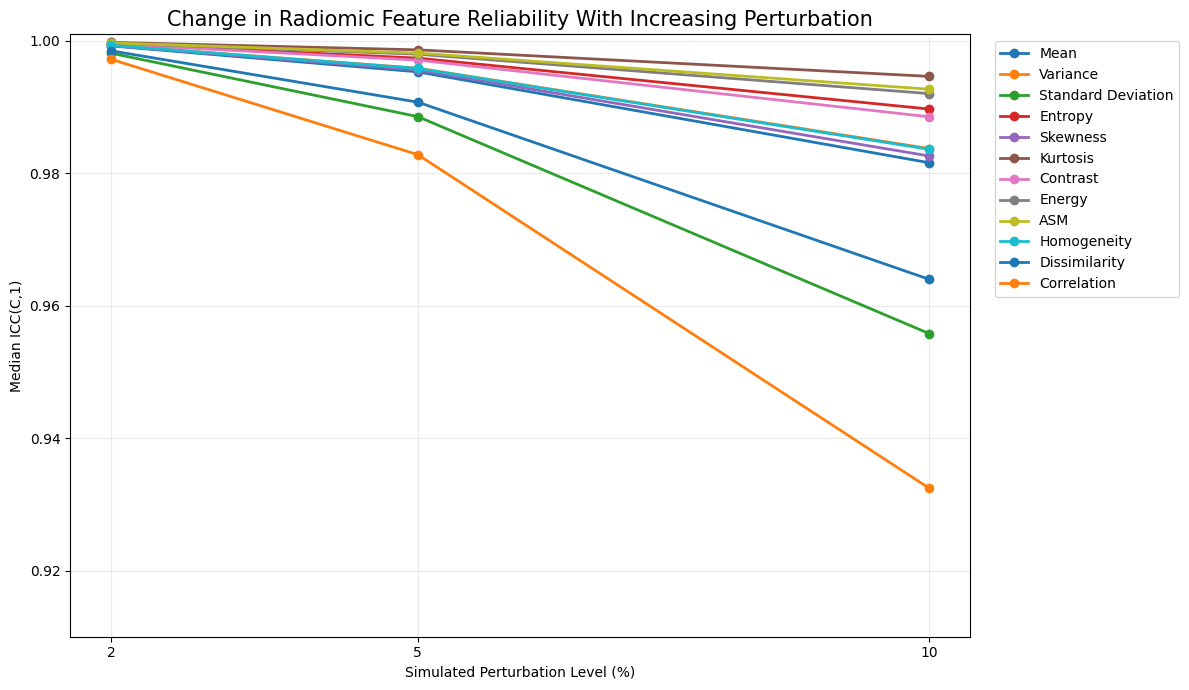

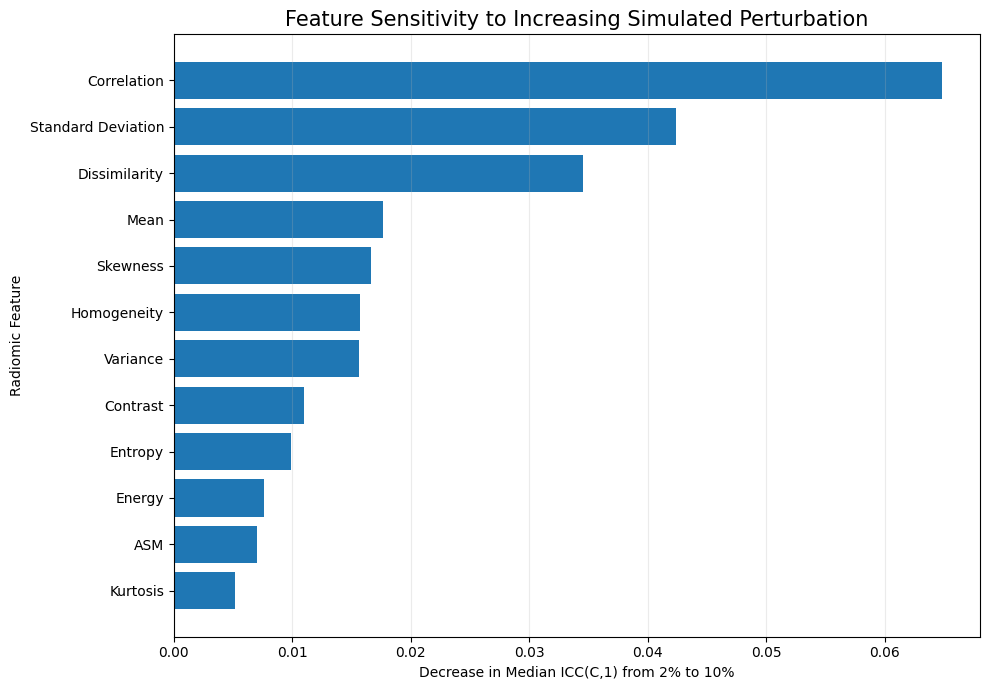

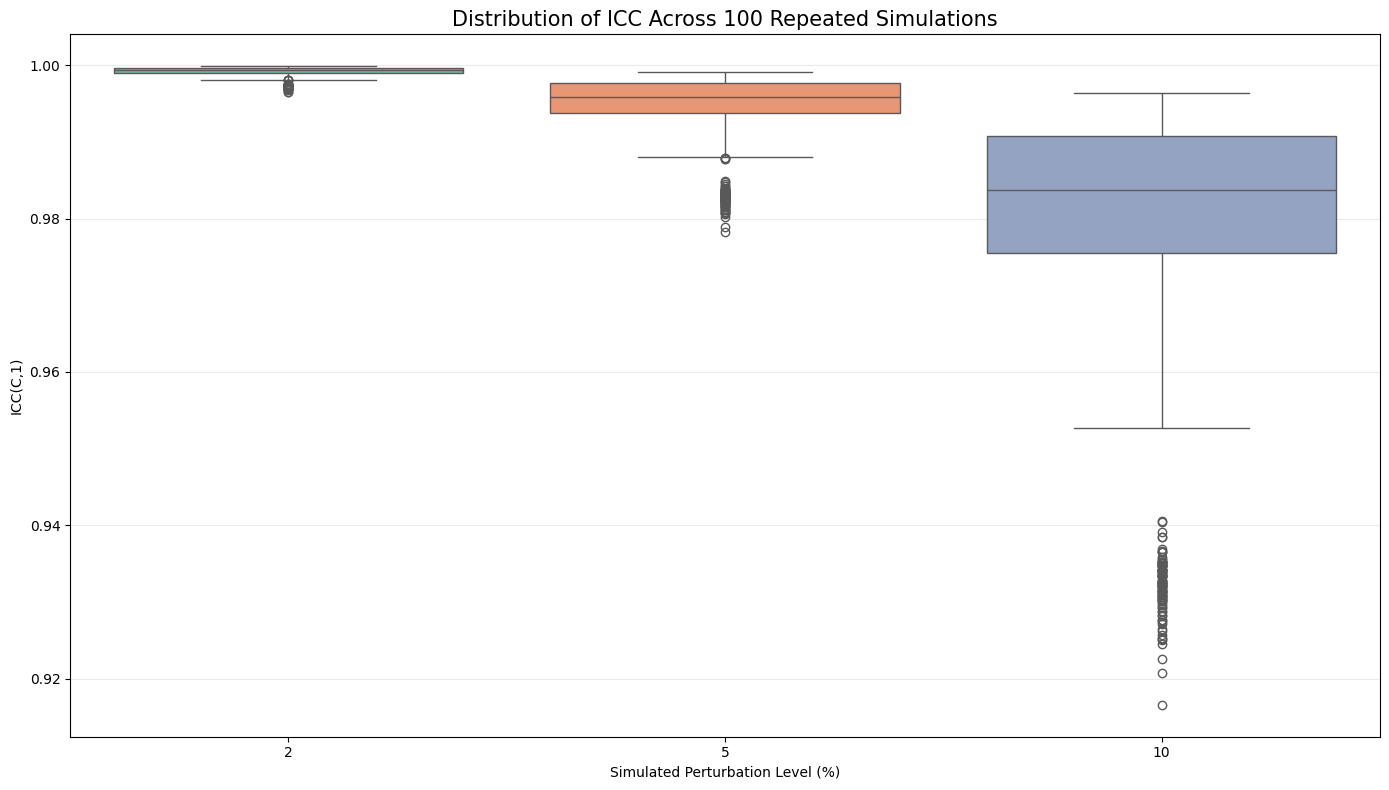

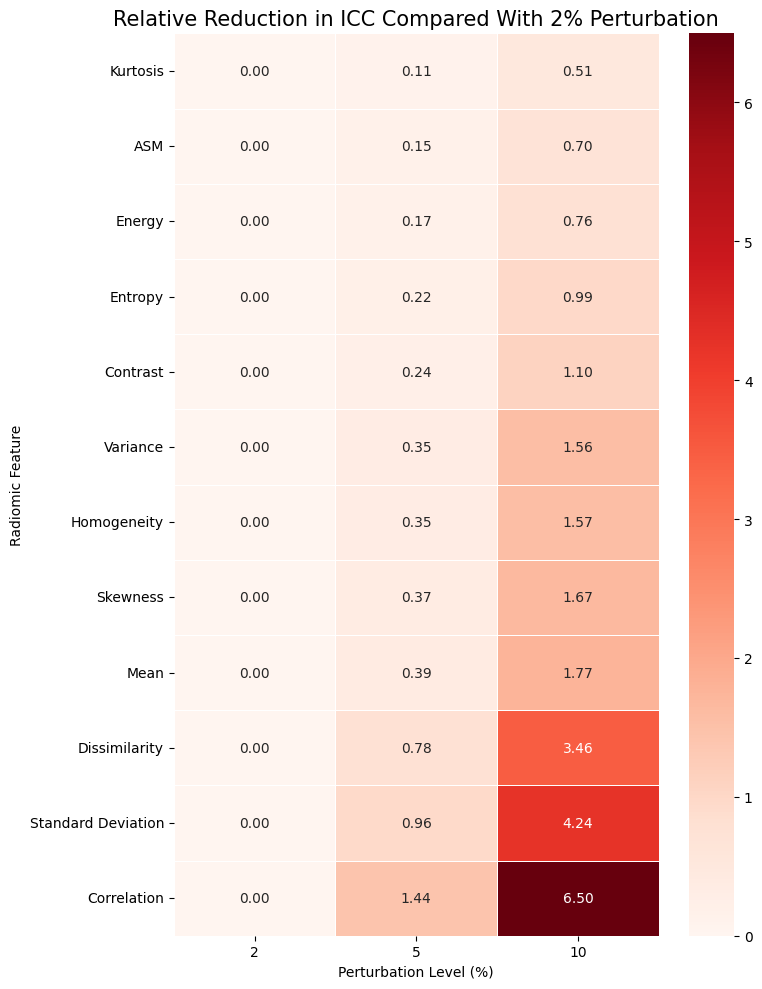


================ FINAL ICC TABLE ================



Noise_Level,ICC_2%,ICC_5%,ICC_10%,ICC_Decrease_2_to_10
Feature,,,,
Correlation,0.997234,0.982825,0.932446,0.064788
Standard Deviation,0.998153,0.988571,0.955801,0.042353
Dissimilarity,0.998511,0.990758,0.963997,0.034514
Mean,0.999251,0.995333,0.981609,0.017642
Skewness,0.999298,0.995615,0.982626,0.016672
Homogeneity,0.999334,0.995853,0.983636,0.015698
Variance,0.999339,0.995884,0.983750,0.015589
Contrast,0.999537,0.997108,0.988546,0.010991
Entropy,0.999585,0.997410,0.989714,0.009871



All figures and the final table have been generated.


In [94]:
# ============================================================
# FINAL VISUALIZATION SECTION
# Brain Tumor Radiomic Feature Reliability Study
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

features = list(original_features.columns)

print("Number of radiomic features:", len(features))
print("Features:")
print(features)


# ============================================================
# FIGURE 1 — Distribution of radiomic features
# ============================================================

fig, axes = plt.subplots(3, 4, figsize=(16, 11))

for ax, feature in zip(axes.flatten(), features):

    ax.hist(
        original_features[feature],
        bins=30,
        edgecolor="black"
    )

    ax.set_title(feature)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Distribution of Radiomic Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    "Figure_1_Radiomic_Feature_Distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2 — Correlation heatmap
# ============================================================

correlation_matrix = original_features.corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title(
    "Spearman Correlation Matrix of Radiomic Features",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "Figure_2_Spearman_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3 — ICC heatmap
# ============================================================

icc_heatmap = (
    icc_summary
    .pivot(
        index="Feature",
        columns="Noise_Level",
        values="Median"
    )
)

# Reorder features according to sensitivity
feature_order = (
    icc_summary
    .groupby("Feature")
    .apply(
        lambda x: x.loc[
            x["Noise_Level"].idxmin(),
            "Feature"
        ]
    )
)

# Use the previously calculated sensitivity ordering
sensitivity_order = (
    icc_summary
    .pivot(
        index="Feature",
        columns="Noise_Level",
        values="Median"
    )
    .assign(
        Decrease=lambda x: x[2] - x[10]
    )
    .sort_values(
        "Decrease",
        ascending=False
    )
    .index
)

icc_heatmap = icc_heatmap.loc[sensitivity_order]

plt.figure(figsize=(8, 10))

sns.heatmap(
    icc_heatmap,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    vmin=0.90,
    vmax=1.00,
    linewidths=0.5
)

plt.title(
    "Median ICC(C,1) Across Simulated Perturbation Levels",
    fontsize=15
)

plt.xlabel("Perturbation Level (%)")
plt.ylabel("Radiomic Feature")

plt.tight_layout()

plt.savefig(
    "Figure_3_ICC_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4 — ICC trend
# ============================================================

plt.figure(figsize=(12, 7))

for feature in features:

    values = (
        icc_summary[
            icc_summary["Feature"] == feature
        ]
        .sort_values("Noise_Level")
    )

    plt.plot(
        values["Noise_Level"],
        values["Median"],
        marker="o",
        linewidth=2,
        label=feature
    )

plt.xlabel("Simulated Perturbation Level (%)")
plt.ylabel("Median ICC(C,1)")

plt.title(
    "Change in Radiomic Feature Reliability With Increasing Perturbation",
    fontsize=15
)

plt.xticks([2, 5, 10])

plt.ylim(0.91, 1.001)

plt.grid(alpha=0.25)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "Figure_4_ICC_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 5 — Feature sensitivity
# ============================================================

sensitivity = (
    icc_summary
    .pivot(
        index="Feature",
        columns="Noise_Level",
        values="Median"
    )
)

sensitivity["ICC_Decrease"] = (
    sensitivity[2] - sensitivity[10]
)

sensitivity = sensitivity.sort_values(
    "ICC_Decrease",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    sensitivity.index,
    sensitivity["ICC_Decrease"]
)

plt.xlabel(
    "Decrease in Median ICC(C,1) from 2% to 10%"
)

plt.ylabel("Radiomic Feature")

plt.title(
    "Feature Sensitivity to Increasing Simulated Perturbation",
    fontsize=15
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "Figure_5_Feature_Sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 6 — Distribution of repeated ICC simulations
# ============================================================

plt.figure(figsize=(14, 8))

sns.boxplot(
    data=icc_simulation_results,
    x="Noise_Level",
    y="ICC_C1",
    hue="Noise_Level",
    palette="Set2",
    legend=False
)

plt.xlabel("Simulated Perturbation Level (%)")
plt.ylabel("ICC(C,1)")

plt.title(
    "Distribution of ICC Across 100 Repeated Simulations",
    fontsize=15
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "Figure_6_ICC_Simulation_Distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 7 — ICC sensitivity heatmap
# ============================================================

sensitivity_table = (
    sensitivity
    .drop(columns="ICC_Decrease")
    .copy()
)

# Convert ICC into percentage reduction relative to 2%
baseline = sensitivity_table[2]

relative_reduction = pd.DataFrame(index=sensitivity_table.index)

relative_reduction[2] = 0

relative_reduction[5] = (
    (baseline - sensitivity_table[5])
    / baseline
) * 100

relative_reduction[10] = (
    (baseline - sensitivity_table[10])
    / baseline
) * 100

plt.figure(figsize=(8, 10))

sns.heatmap(
    relative_reduction,
    annot=True,
    fmt=".2f",
    cmap="Reds",
    linewidths=0.5
)

plt.title(
    "Relative Reduction in ICC Compared With 2% Perturbation",
    fontsize=15
)

plt.xlabel("Perturbation Level (%)")
plt.ylabel("Radiomic Feature")

plt.tight_layout()

plt.savefig(
    "Figure_7_Relative_ICC_Reduction_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FINAL SUMMARY TABLE
# ============================================================

final_table = sensitivity.copy()

final_table = final_table.rename(
    columns={
        2: "ICC_2%",
        5: "ICC_5%",
        10: "ICC_10%",
        "ICC_Decrease": "ICC_Decrease_2_to_10"
    }
)

final_table = final_table.sort_values(
    "ICC_Decrease_2_to_10",
    ascending=False
)

print("\n================ FINAL ICC TABLE ================\n")

display(
    final_table.round(6)
)


# ============================================================
# SAVE FINAL TABLE
# ============================================================

final_table.to_csv(
    "Final_ICC_Reliability_Table.csv"
)

print("\nAll figures and the final table have been generated.")

In [95]:
# ============================================================
# CLEAN FINAL ICC TABLE
# ============================================================

final_icc_table = (
    icc_summary
    .pivot(
        index="Feature",
        columns="Noise_Level",
        values="Median"
    )
    .reset_index()
)

final_icc_table.columns = [
    "Feature",
    "ICC_2%",
    "ICC_5%",
    "ICC_10%"
]

final_icc_table["ICC_Decrease_2_to_10"] = (
    final_icc_table["ICC_2%"]
    - final_icc_table["ICC_10%"]
)

final_icc_table = final_icc_table.sort_values(
    "ICC_Decrease_2_to_10",
    ascending=False
).reset_index(drop=True)

print("FINAL ICC RELIABILITY TABLE")
print("=" * 70)

display(
    final_icc_table.style
    .format({
        "ICC_2%": "{:.6f}",
        "ICC_5%": "{:.6f}",
        "ICC_10%": "{:.6f}",
        "ICC_Decrease_2_to_10": "{:.6f}"
    })
)

# Save for paper
final_icc_table.to_csv(
    "Final_ICC_Reliability_Table.csv",
    index=False
)

print("\nSaved as: Final_ICC_Reliability_Table.csv")

FINAL ICC RELIABILITY TABLE


,Feature,ICC_2%,ICC_5%,ICC_10%,ICC_Decrease_2_to_10
0,Correlation,0.997234,0.982825,0.932446,0.064788
1,Standard Deviation,0.998153,0.988571,0.955801,0.042353
2,Dissimilarity,0.998511,0.990758,0.963997,0.034514
3,Mean,0.999251,0.995333,0.981609,0.017642
4,Skewness,0.999298,0.995615,0.982626,0.016672
5,Homogeneity,0.999334,0.995853,0.983636,0.015698
6,Variance,0.999339,0.995884,0.983750,0.015589
7,Contrast,0.999537,0.997108,0.988546,0.010991
8,Entropy,0.999585,0.997410,0.989714,0.009871
9,Energy,0.999679,0.997997,0.992047,0.007632



Saved as: Final_ICC_Reliability_Table.csv


In [96]:
# ============================================================
# FEATURE REDUNDANCY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

features = list(original_features.columns)

# Pearson correlation
pearson_corr = original_features.corr(method="pearson")

# Spearman correlation
spearman_corr = original_features.corr(method="spearman")


# ------------------------------------------------------------
# Find highly correlated feature pairs
# ------------------------------------------------------------

pairs = []

for i in range(len(features)):
    for j in range(i + 1, len(features)):

        f1 = features[i]
        f2 = features[j]

        spearman_value = spearman_corr.loc[f1, f2]
        pearson_value = pearson_corr.loc[f1, f2]

        pairs.append({
            "Feature_1": f1,
            "Feature_2": f2,
            "Spearman": spearman_value,
            "Pearson": pearson_value,
            "Absolute_Spearman": abs(spearman_value)
        })

correlation_pairs = pd.DataFrame(pairs)

# Sort strongest relationships first
correlation_pairs = correlation_pairs.sort_values(
    "Absolute_Spearman",
    ascending=False
)

print("TOP FEATURE CORRELATION PAIRS")
print("=" * 70)

display(
    correlation_pairs.head(20).round(4)
)


# ------------------------------------------------------------
# Identify very highly correlated pairs
# ------------------------------------------------------------

high_corr = correlation_pairs[
    correlation_pairs["Absolute_Spearman"] >= 0.90
]

print("\nHIGHLY CORRELATED FEATURE PAIRS (|Spearman| >= 0.90)")
print("=" * 70)

display(
    high_corr.round(4)
)


# ------------------------------------------------------------
# Count highly correlated relationships per feature
# ------------------------------------------------------------

high_corr_counts = {}

for feature in features:

    count = 0

    for _, row in high_corr.iterrows():

        if (
            row["Feature_1"] == feature
            or row["Feature_2"] == feature
        ):
            count += 1

    high_corr_counts[feature] = count


redundancy_summary = (
    pd.DataFrame.from_dict(
        high_corr_counts,
        orient="index",
        columns=["Number_of_High_Correlations"]
    )
    .sort_values(
        "Number_of_High_Correlations",
        ascending=False
    )
)

print("\nHIGH-CORRELATION COUNT PER FEATURE")
print("=" * 70)

display(redundancy_summary)

TOP FEATURE CORRELATION PAIRS


,Feature_1,Feature_2,Spearman,Pearson,Absolute_Spearman
56,Energy,ASM,1.0000,0.9616,1.0000
11,Variance,Standard Deviation,1.0000,0.9757,1.0000
34,Entropy,ASM,1.0000,0.9992,1.0000
33,Entropy,Energy,1.0000,0.9713,1.0000
38,Skewness,Kurtosis,0.9991,0.8997,0.9991
35,Entropy,Homogeneity,0.9168,0.8520,0.9168
60,ASM,Homogeneity,0.9156,0.8371,0.9156
57,Energy,Homogeneity,0.9156,0.9160,0.9156
3,Mean,Skewness,-0.8407,-0.6016,0.8407
4,Mean,Kurtosis,-0.8341,-0.3582,0.8341



HIGHLY CORRELATED FEATURE PAIRS (|Spearman| >= 0.90)


,Feature_1,Feature_2,Spearman,Pearson,Absolute_Spearman
56,Energy,ASM,1.0000,0.9616,1.0000
11,Variance,Standard Deviation,1.0000,0.9757,1.0000
34,Entropy,ASM,1.0000,0.9992,1.0000
33,Entropy,Energy,1.0000,0.9713,1.0000
38,Skewness,Kurtosis,0.9991,0.8997,0.9991
35,Entropy,Homogeneity,0.9168,0.8520,0.9168
60,ASM,Homogeneity,0.9156,0.8371,0.9156
57,Energy,Homogeneity,0.9156,0.9160,0.9156



HIGH-CORRELATION COUNT PER FEATURE


,Number_of_High_Correlations
Entropy,3
Homogeneity,3
ASM,3
Energy,3
Kurtosis,1
Standard Deviation,1
Variance,1
Skewness,1
Mean,0
Contrast,0


In [97]:

# ============================================================
# FEATURE REDUNDANCY ANALYSIS - COMPLETE CODE
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. LOAD DATASET (KAGGLE)
# ------------------------------------------------------------

csv_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "brain tumor.csv":
            csv_path = os.path.join(root, file)
            break
    if csv_path is not None:
        break

if csv_path is None:
    raise FileNotFoundError(
        "Brain Tumor.csv not found. Please attach the dataset "
        "using Add Input in Kaggle."
    )

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


# ------------------------------------------------------------
# 2. DEFINE THE 13 ORIGINAL RADIOMIC FEATURES
# ------------------------------------------------------------

radiomic_features = [
    "Mean",
    "Variance",
    "Standard Deviation",
    "Entropy",
    "Skewness",
    "Kurtosis",
    "Contrast",
    "Energy",
    "ASM",
    "Homogeneity",
    "Dissimilarity",
    "Correlation",
    "Coarseness"
]


# ------------------------------------------------------------
# 3. REMOVE CONSTANT FEATURE: COARSENESS
# ------------------------------------------------------------

original_features = df[radiomic_features].copy()

# Check variance
feature_variance = original_features.var()

print("\nFeature variances:")
display(feature_variance.to_frame("Variance"))

# Remove zero-variance features
zero_variance_features = feature_variance[
    feature_variance == 0
].index.tolist()

print("\nZero-variance features removed:")
print(zero_variance_features)

original_features = original_features.drop(
    columns=zero_variance_features
)

print("\nFinal number of radiomic features:",
      len(original_features.columns))

print("\nFinal features:")
print(original_features.columns.tolist())


# ------------------------------------------------------------
# 4. PEARSON CORRELATION
# ------------------------------------------------------------

pearson_corr = original_features.corr(
    method="pearson"
)


# ------------------------------------------------------------
# 5. SPEARMAN CORRELATION
# ------------------------------------------------------------

spearman_corr = original_features.corr(
    method="spearman"
)


# ------------------------------------------------------------
# 6. FIND HIGHLY CORRELATED FEATURE PAIRS
# ------------------------------------------------------------

features = list(original_features.columns)

pairs = []

for i in range(len(features)):

    for j in range(i + 1, len(features)):

        f1 = features[i]
        f2 = features[j]

        spearman_value = spearman_corr.loc[f1, f2]
        pearson_value = pearson_corr.loc[f1, f2]

        pairs.append({
            "Feature_1": f1,
            "Feature_2": f2,
            "Spearman": spearman_value,
            "Pearson": pearson_value,
            "Absolute_Spearman": abs(spearman_value)
        })


correlation_pairs = pd.DataFrame(pairs)

correlation_pairs = correlation_pairs.sort_values(
    "Absolute_Spearman",
    ascending=False
)


# ------------------------------------------------------------
# 7. DISPLAY TOP 20 CORRELATED PAIRS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP 20 FEATURE CORRELATIONS")
print("=" * 70)

display(
    correlation_pairs.head(20).round(4)
)


# ------------------------------------------------------------
# 8. IDENTIFY HIGH CORRELATIONS (|Spearman| >= 0.90)
# ------------------------------------------------------------

high_corr = correlation_pairs[
    correlation_pairs["Absolute_Spearman"] >= 0.90
]

print("\n" + "=" * 70)
print("HIGHLY CORRELATED FEATURE PAIRS (|Spearman| >= 0.90)")
print("=" * 70)

display(
    high_corr.round(4)
)


# ------------------------------------------------------------
# 9. COUNT HIGH CORRELATIONS PER FEATURE
# ------------------------------------------------------------

high_corr_counts = {}

for feature in features:

    count = 0

    for _, row in high_corr.iterrows():

        if (
            row["Feature_1"] == feature
            or row["Feature_2"] == feature
        ):
            count += 1

    high_corr_counts[feature] = count


redundancy_summary = (
    pd.DataFrame.from_dict(
        high_corr_counts,
        orient="index",
        columns=["Number_of_High_Correlations"]
    )
    .sort_values(
        "Number_of_High_Correlations",
        ascending=False
    )
)


# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HIGH-CORRELATION COUNT PER FEATURE")
print("=" * 70)

display(redundancy_summary)


Dataset shape: (3762, 15)

Columns:
['Image', 'Class', 'Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation', 'Coarseness']


,Image,Class,Mean,Variance,Standard Deviation,Entropy,Skewness,Kurtosis,Contrast,Energy,ASM,Homogeneity,Dissimilarity,Correlation,Coarseness
0,Image1,0,6.535339,619.587845,24.891522,0.109059,4.276477,18.900575,98.613971,0.293314,0.086033,0.530941,4.473346,0.981939,7.458341e-155
1,Image2,0,8.749969,805.957634,28.389393,0.266538,3.718116,14.464618,63.858816,0.475051,0.225674,0.651352,3.220072,0.988834,7.458341e-155
2,Image3,1,7.341095,1143.808219,33.820234,0.001467,5.061750,26.479563,81.867206,0.031917,0.001019,0.268275,5.981800,0.978014,7.458341e-155
3,Image4,1,5.958145,959.711985,30.979219,0.001477,5.677977,33.428845,151.229741,0.032024,0.001026,0.243851,7.700919,0.964189,7.458341e-155
4,Image5,0,7.315231,729.540579,27.010009,0.146761,4.283221,19.079108,174.988756,0.343849,0.118232,0.501140,6.834689,0.972789,7.458341e-155



Feature variances:


,Variance
Mean,32.810234
Variance,218525.298564
Standard Deviation,76.974757
Entropy,0.004938
Skewness,6.558413
Kurtosis,3184.880670
Contrast,11990.162523
Energy,0.016732
ASM,0.003399
Homogeneity,0.016366



Zero-variance features removed:
['Coarseness']

Final number of radiomic features: 12

Final features:
['Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation']

TOP 20 FEATURE CORRELATIONS


,Feature_1,Feature_2,Spearman,Pearson,Absolute_Spearman
56,Energy,ASM,1.0000,0.9616,1.0000
11,Variance,Standard Deviation,1.0000,0.9757,1.0000
34,Entropy,ASM,1.0000,0.9992,1.0000
33,Entropy,Energy,1.0000,0.9713,1.0000
38,Skewness,Kurtosis,0.9991,0.8997,0.9991
35,Entropy,Homogeneity,0.9168,0.8520,0.9168
60,ASM,Homogeneity,0.9156,0.8371,0.9156
57,Energy,Homogeneity,0.9156,0.9160,0.9156
3,Mean,Skewness,-0.8407,-0.6016,0.8407
4,Mean,Kurtosis,-0.8341,-0.3582,0.8341



HIGHLY CORRELATED FEATURE PAIRS (|Spearman| >= 0.90)


,Feature_1,Feature_2,Spearman,Pearson,Absolute_Spearman
56,Energy,ASM,1.0000,0.9616,1.0000
11,Variance,Standard Deviation,1.0000,0.9757,1.0000
34,Entropy,ASM,1.0000,0.9992,1.0000
33,Entropy,Energy,1.0000,0.9713,1.0000
38,Skewness,Kurtosis,0.9991,0.8997,0.9991
35,Entropy,Homogeneity,0.9168,0.8520,0.9168
60,ASM,Homogeneity,0.9156,0.8371,0.9156
57,Energy,Homogeneity,0.9156,0.9160,0.9156



HIGH-CORRELATION COUNT PER FEATURE


,Number_of_High_Correlations
Entropy,3
Homogeneity,3
ASM,3
Energy,3
Kurtosis,1
Standard Deviation,1
Variance,1
Skewness,1
Mean,0
Contrast,0


In [100]:

# ============================================================
# COMPLETE ICC SIMULATION + STATISTICAL TEST
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. LOAD DATASET (KAGGLE)
# ------------------------------------------------------------

csv_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "brain tumor.csv":
            csv_path = os.path.join(root, file)
            break
    if csv_path is not None:
        break

if csv_path is None:
    raise FileNotFoundError(
        "Brain Tumor.csv not found. Attach the dataset using "
        "Add Input in Kaggle."
    )

df = pd.read_csv(csv_path)

print("Loaded file:", csv_path)
print("Dataset shape:", df.shape)


# ------------------------------------------------------------
# 2. SELECT RADIOMIC FEATURES
# ------------------------------------------------------------

radiomic_features = [
    "Mean",
    "Variance",
    "Standard Deviation",
    "Entropy",
    "Skewness",
    "Kurtosis",
    "Contrast",
    "Energy",
    "ASM",
    "Homogeneity",
    "Dissimilarity",
    "Correlation",
    "Coarseness"
]

original_features = df[radiomic_features].copy()


# ------------------------------------------------------------
# 3. REMOVE ZERO-VARIANCE FEATURE
# ------------------------------------------------------------

feature_variance = original_features.var()

zero_variance_features = feature_variance[
    feature_variance == 0
].index.tolist()

original_features = original_features.drop(
    columns=zero_variance_features
)

print("Removed:", zero_variance_features)
print("Final features:", len(original_features.columns))


# ------------------------------------------------------------
# 4. ROBUST PERTURBATION FUNCTION
# ------------------------------------------------------------

def create_robust_perturbation(data, noise_level, seed=None):

    rng = np.random.default_rng(seed)
    perturbed = data.copy()

    for col in data.columns:

        values = data[col].values.astype(float)

        # Correlation must remain between -1 and +1
        if col == "Correlation":

            clipped = np.clip(values, -0.999999, 0.999999)
            z = np.arctanh(clipped)

            z_noise = rng.normal(
                0, noise_level, size=len(values)
            )

            new_values = np.tanh(z + z_noise)

        # These features must remain between 0 and 1
        elif col in ["Energy", "ASM", "Homogeneity"]:

            clipped = np.clip(values, 1e-6, 1 - 1e-6)

            logit_values = np.log(
                clipped / (1 - clipped)
            )

            logit_noise = rng.normal(
                0, noise_level, size=len(values)
            )

            new_values = 1 / (
                1 + np.exp(-(logit_values + logit_noise))
            )

        # Positive-valued features
        else:

            noise_factor = rng.normal(
                0, noise_level, size=len(values)
            )

            new_values = values * (1 + noise_factor)
            new_values = np.maximum(new_values, 0)

        perturbed[col] = new_values

    return perturbed


# ------------------------------------------------------------
# 5. ICC(C,1) FUNCTION
# ------------------------------------------------------------

def fast_icc_c1(original, perturbed):

    x = np.asarray(original, dtype=float)
    y = np.asarray(perturbed, dtype=float)

    n = len(x)

    measurements = np.column_stack([x, y])

    subject_means = measurements.mean(axis=1)
    grand_mean = measurements.mean()

    ss_between = 2 * np.sum(
        (subject_means - grand_mean) ** 2
    )

    ss_within = np.sum(
        (measurements - subject_means[:, None]) ** 2
    )

    ms_between = ss_between / (n - 1)
    ms_within = ss_within / n

    icc = (
        ms_between - ms_within
    ) / (
        ms_between + ms_within
    )

    return icc


# ------------------------------------------------------------
# 6. RUN 100 SIMULATIONS AT 2%, 5%, 10%
# ------------------------------------------------------------

noise_levels = [0.02, 0.05, 0.10]
n_simulations = 100
results = []

print("\nRunning simulations...")

for noise_level in noise_levels:

    print(f"Running {int(noise_level * 100)}% simulations...")

    for simulation in range(n_simulations):

        seed = 1000 + simulation

        perturbed = create_robust_perturbation(
            original_features,
            noise_level=noise_level,
            seed=seed
        )

        for feature in original_features.columns:

            icc_value = fast_icc_c1(
                original_features[feature],
                perturbed[feature]
            )

            results.append({
                "Noise_Level": int(noise_level * 100),
                "Simulation": simulation + 1,
                "Feature": feature,
                "ICC_C1": icc_value
            })


icc_simulation_results = pd.DataFrame(results)

print("\nTotal ICC observations:",
      len(icc_simulation_results))


# ------------------------------------------------------------
# 7. MEDIAN ICC SUMMARY
# ------------------------------------------------------------

icc_summary = (
    icc_simulation_results
    .groupby(["Noise_Level", "Feature"])["ICC_C1"]
    .agg(
        Mean="mean",
        Median="median",
        SD="std",
        Q2_5=lambda x: x.quantile(0.025),
        Q97_5=lambda x: x.quantile(0.975),
        Minimum="min",
        Maximum="max"
    )
    .reset_index()
)

print("\n")
print("=" * 70)
print("MEDIAN ICC SUMMARY")
print("=" * 70)

median_table = icc_summary.pivot(
    index="Feature",
    columns="Noise_Level",
    values="Median"
)

median_table = median_table.reindex(columns=[2, 5, 10])
median_table.columns = ["ICC_2%", "ICC_5%", "ICC_10%"]

display(median_table.round(6))


# ------------------------------------------------------------
# 8. PAIRED TEST ACROSS PERTURBATION LEVELS (Friedman, one test per feature)
#    Each of the 100 simulations is a block; the 3 levels are the conditions.
# ------------------------------------------------------------
from scipy.stats import friedmanchisquare

features = list(original_features.columns)
n_sims = n_simulations
k_levels = len(noise_levels)

rows = []
for feature in features:
    wide = (
        icc_simulation_results[icc_simulation_results["Feature"] == feature]
        .pivot(index="Simulation", columns="Noise_Level", values="ICC_C1")
        .reindex(columns=[2, 5, 10])
    )
    stat, p = friedmanchisquare(wide[2], wide[5], wide[10])
    rows.append({
        "Feature": feature,
        "Friedman_chi2": stat,
        "p_value": p,
        "Kendalls_W": stat / (n_sims * (k_levels - 1)),   # effect size, 0 to 1
        "Median_ICC_2%": wide[2].median(),
        "Median_ICC_5%": wide[5].median(),
        "Median_ICC_10%": wide[10].median(),
    })

statistical_results = pd.DataFrame(rows)

# ------------------------------------------------------------
# 9. BONFERRONI CORRECTION (12 features)
# ------------------------------------------------------------
statistical_results["Adjusted_p_value"] = np.minimum(
    statistical_results["p_value"] * len(features), 1.0
)
statistical_results["Significant"] = statistical_results["Adjusted_p_value"] < 0.05
statistical_results = statistical_results.sort_values("Adjusted_p_value")

# ------------------------------------------------------------
# 10. DISPLAY STATISTICAL RESULTS
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("STATISTICAL COMPARISON OF ICC ACROSS PERTURBATION LEVELS")
print("=" * 70)
display(statistical_results.round(6))

print("\nNote: Kendall's W = 1 means the ICC fell with the noise level in every one of")
print("the 100 simulations. Report W and the medians; the p-values are tiny by design.")

Loaded file: /kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor.csv
Dataset shape: (3762, 15)
Removed: ['Coarseness']
Final features: 12

Running simulations...
Running 2% simulations...
Running 5% simulations...
Running 10% simulations...

Total ICC observations: 3600


MEDIAN ICC SUMMARY


,ICC_2%,ICC_5%,ICC_10%
Feature,,,
ASM,0.999707,0.998171,0.992712
Contrast,0.999537,0.997108,0.988546
Correlation,0.997234,0.982825,0.932446
Dissimilarity,0.998511,0.990758,0.963997
Energy,0.999679,0.997997,0.992047
Entropy,0.999585,0.997410,0.989714
Homogeneity,0.999334,0.995853,0.983636
Kurtosis,0.999785,0.998656,0.994647
Mean,0.999251,0.995333,0.981609



STATISTICAL COMPARISON OF ICC ACROSS PERTURBATION LEVELS


,Feature,Friedman_chi2,p_value,Kendalls_W,Median_ICC_2%,Median_ICC_5%,Median_ICC_10%,Adjusted_p_value,Significant
0,Mean,200.0,0.0,1.0,0.999251,0.995333,0.981609,0.0,True
1,Variance,200.0,0.0,1.0,0.999339,0.995884,0.983750,0.0,True
2,Standard Deviation,200.0,0.0,1.0,0.998153,0.988571,0.955801,0.0,True
3,Entropy,200.0,0.0,1.0,0.999585,0.997410,0.989714,0.0,True
4,Skewness,200.0,0.0,1.0,0.999298,0.995615,0.982626,0.0,True
5,Kurtosis,200.0,0.0,1.0,0.999785,0.998656,0.994647,0.0,True
6,Contrast,200.0,0.0,1.0,0.999537,0.997108,0.988546,0.0,True
7,Energy,200.0,0.0,1.0,0.999679,0.997997,0.992047,0.0,True
8,ASM,200.0,0.0,1.0,0.999707,0.998171,0.992712,0.0,True
9,Homogeneity,200.0,0.0,1.0,0.999334,0.995853,0.983636,0.0,True



Note: Kendall's W = 1 means the ICC fell with the noise level in every one of
the 100 simulations. Report W and the medians; the p-values are tiny by design.


In [101]:
# ============================================================
# FRIEDMAN TEST: MATCHED COMPARISON OF ICC ACROSS LEVELS
# ============================================================

from scipy.stats import friedmanchisquare
import pandas as pd

friedman_results = []

features = icc_simulation_results["Feature"].unique()

for feature in features:

    # Extract ICC values for each perturbation level
    # Simulation 1 at each level is treated as a matched set,
    # simulation 2 as another matched set, etc.

    data_2 = (
        icc_simulation_results[
            (icc_simulation_results["Feature"] == feature) &
            (icc_simulation_results["Noise_Level"] == 2)
        ]
        .sort_values("Simulation")["ICC_C1"]
        .values
    )

    data_5 = (
        icc_simulation_results[
            (icc_simulation_results["Feature"] == feature) &
            (icc_simulation_results["Noise_Level"] == 5)
        ]
        .sort_values("Simulation")["ICC_C1"]
        .values
    )

    data_10 = (
        icc_simulation_results[
            (icc_simulation_results["Feature"] == feature) &
            (icc_simulation_results["Noise_Level"] == 10)
        ]
        .sort_values("Simulation")["ICC_C1"]
        .values
    )

    # Friedman test
    statistic, p_value = friedmanchisquare(
        data_2,
        data_5,
        data_10
    )

    friedman_results.append({
        "Feature": feature,
        "Friedman_Chi_Square": statistic,
        "p_value": p_value
    })


friedman_results = pd.DataFrame(
    friedman_results
)

# Bonferroni correction for 12 features
friedman_results["Adjusted_p_value"] = (
    friedman_results["p_value"] * len(features)
).clip(upper=1.0)

friedman_results["Significant"] = (
    friedman_results["Adjusted_p_value"] < 0.05
)

friedman_results = friedman_results.sort_values(
    "Adjusted_p_value"
)

print("=" * 70)
print("FRIEDMAN TEST: ICC ACROSS 2%, 5%, AND 10% PERTURBATION")
print("=" * 70)

display(
    friedman_results.round(6)
)

FRIEDMAN TEST: ICC ACROSS 2%, 5%, AND 10% PERTURBATION


,Feature,Friedman_Chi_Square,p_value,Adjusted_p_value,Significant
0,Mean,200.0,0.0,0.0,True
1,Variance,200.0,0.0,0.0,True
2,Standard Deviation,200.0,0.0,0.0,True
3,Entropy,200.0,0.0,0.0,True
4,Skewness,200.0,0.0,0.0,True
5,Kurtosis,200.0,0.0,0.0,True
6,Contrast,200.0,0.0,0.0,True
7,Energy,200.0,0.0,0.0,True
8,ASM,200.0,0.0,0.0,True
9,Homogeneity,200.0,0.0,0.0,True


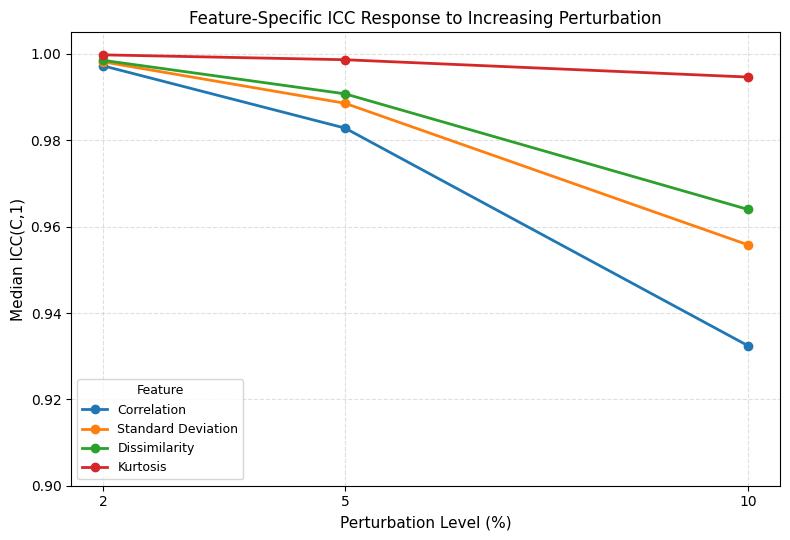

In [102]:
# ============================================================
# FIGURE 4 — IMPROVED ICC TREND FOR REPRESENTATIVE FEATURES
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Features selected to represent different sensitivity levels
selected_features = [
    "Correlation",
    "Standard Deviation",
    "Dissimilarity",
    "Kurtosis"
]

# Perturbation levels
noise_levels = [2, 5, 10]

plt.figure(figsize=(8, 5.5))

for feature in selected_features:

    feature_data = (
        icc_summary[
            icc_summary["Feature"] == feature
        ]
        .sort_values("Noise_Level")
    )

    x = feature_data["Noise_Level"].values
    y = feature_data["Median"].values

    plt.plot(
        x,
        y,
        marker="o",
        linewidth=2,
        markersize=6,
        label=feature
    )

plt.xlabel("Perturbation Level (%)", fontsize=11)
plt.ylabel("Median ICC(C,1)", fontsize=11)

plt.xticks(noise_levels)
plt.ylim(0.90, 1.005)

plt.title(
    "Feature-Specific ICC Response to Increasing Perturbation",
    fontsize=12
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.legend(
    title="Feature",
    fontsize=9,
    title_fontsize=9,
    loc="lower left"
)

plt.tight_layout()

plt.savefig(
    "fig4_icc_trend_representative_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/tmp/ipykernel_48/1713618460.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


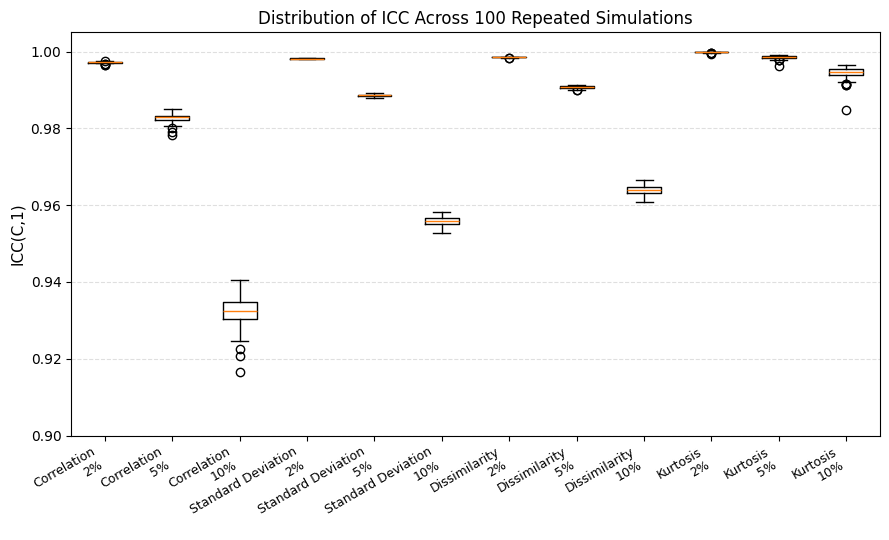

In [103]:
# ============================================================
# FIGURE S1 — ICC DISTRIBUTIONS FOR REPRESENTATIVE FEATURES
# ============================================================

import matplotlib.pyplot as plt

selected_features = [
    "Correlation",
    "Standard Deviation",
    "Dissimilarity",
    "Kurtosis"
]

plt.figure(figsize=(9, 5.5))

# Create combined labels
plot_data = []
labels = []

for feature in selected_features:

    for noise_level in [2, 5, 10]:

        values = icc_simulation_results[
            (icc_simulation_results["Feature"] == feature) &
            (icc_simulation_results["Noise_Level"] == noise_level)
        ]["ICC_C1"].values

        plot_data.append(values)
        labels.append(f"{feature}\n{noise_level}%")

plt.boxplot(
    plot_data,
    labels=labels,
    patch_artist=False
)

plt.ylabel("ICC(C,1)", fontsize=11)

plt.title(
    "Distribution of ICC Across 100 Repeated Simulations",
    fontsize=12
)

plt.ylim(0.90, 1.005)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.xticks(
    rotation=30,
    ha="right",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "figS1_icc_distributions_representative_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

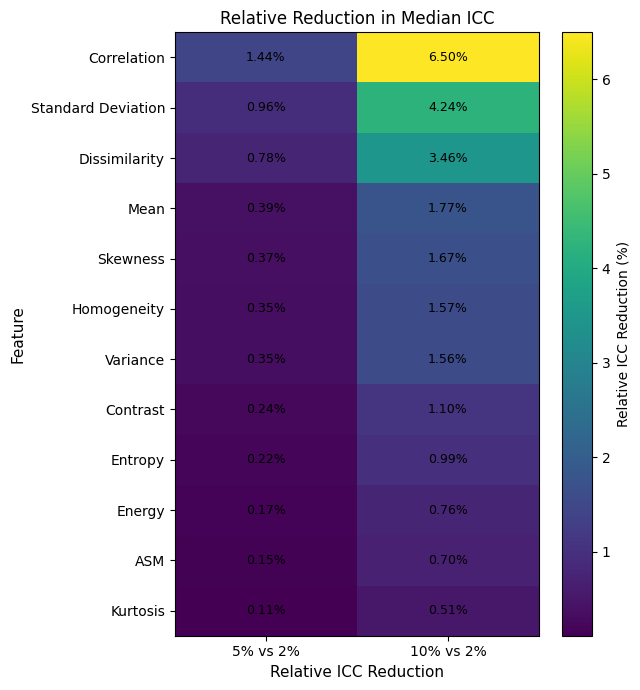

In [104]:
# ============================================================
# FIGURE S2 — RELATIVE ICC REDUCTION HEATMAP
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Copy median ICC results
relative_data = icc_summary.copy()

# Convert to a table:
# rows = features
# columns = perturbation levels
relative_table = relative_data.pivot(
    index="Feature",
    columns="Noise_Level",
    values="Median"
)

# Calculate relative reduction compared with 2% perturbation
relative_reduction = pd.DataFrame(index=relative_table.index)

relative_reduction[5] = (
    (relative_table[2] - relative_table[5])
    / relative_table[2]
) * 100

relative_reduction[10] = (
    (relative_table[2] - relative_table[10])
    / relative_table[2]
) * 100

# Sort features according to the 10% relative reduction
relative_reduction = relative_reduction.sort_values(
    by=10,
    ascending=False
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(6.5, 7))

plt.imshow(
    relative_reduction.values,
    aspect="auto"
)

plt.xticks(
    range(len(relative_reduction.columns)),
    ["5% vs 2%", "10% vs 2%"]
)

plt.yticks(
    range(len(relative_reduction.index)),
    relative_reduction.index
)

plt.xlabel(
    "Relative ICC Reduction",
    fontsize=11
)

plt.ylabel(
    "Feature",
    fontsize=11
)

plt.title(
    "Relative Reduction in Median ICC",
    fontsize=12
)

# Add numerical values inside cells
for i in range(relative_reduction.shape[0]):

    for j in range(relative_reduction.shape[1]):

        value = relative_reduction.iloc[i, j]

        plt.text(
            j,
            i,
            f"{value:.2f}%",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(
    label="Relative ICC Reduction (%)"
)

plt.tight_layout()

plt.savefig(
    "figS2_relative_icc_reduction_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

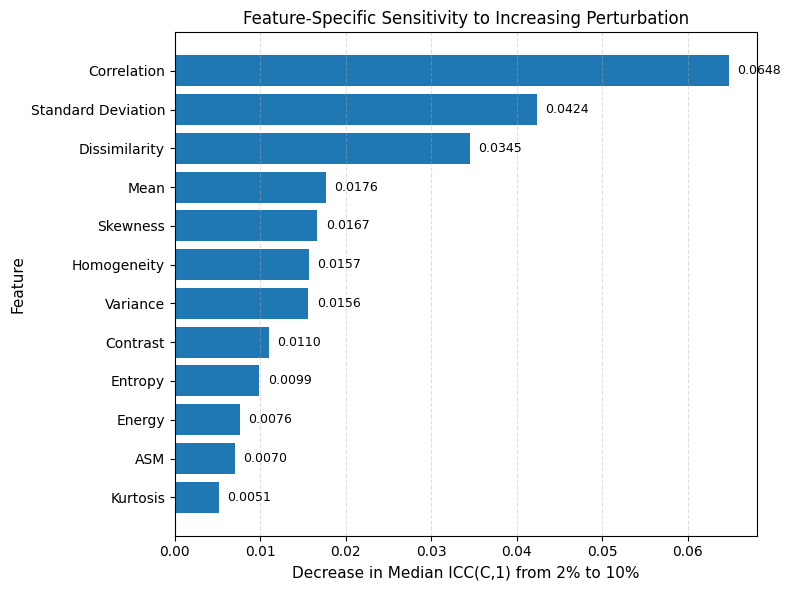

In [105]:
# ============================================================
# FIGURE 5 — FEATURE SENSITIVITY
# ============================================================

import matplotlib.pyplot as plt

# Create sensitivity table
sensitivity = (
    icc_summary[
        icc_summary["Noise_Level"].isin([2, 10])
    ]
    .pivot(
        index="Feature",
        columns="Noise_Level",
        values="Median"
    )
)

# Calculate absolute decrease
sensitivity["Decrease"] = (
    sensitivity[2] - sensitivity[10]
)

# Sort from largest to smallest decrease
sensitivity = sensitivity.sort_values(
    "Decrease",
    ascending=True
)

plt.figure(figsize=(8, 6))

plt.barh(
    sensitivity.index,
    sensitivity["Decrease"]
)

plt.xlabel(
    "Decrease in Median ICC(C,1) from 2% to 10%",
    fontsize=11
)

plt.ylabel(
    "Feature",
    fontsize=11
)

plt.title(
    "Feature-Specific Sensitivity to Increasing Perturbation",
    fontsize=12
)

# Add values at the end of bars
for i, value in enumerate(sensitivity["Decrease"]):

    plt.text(
        value + 0.001,
        i,
        f"{value:.4f}",
        va="center",
        fontsize=9
    )

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    "fig5_feature_sensitivity_improved.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [106]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.replace("/kaggle/input", "").count(os.sep)
    if depth <= 2:
        print(root, "->", files[:10])

/kaggle/input -> []
/kaggle/input/datasets -> []
/kaggle/input/datasets/jakeshbohaju -> []


In [107]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(f"\nFOLDER: {root}")
    for file in files[:15]:
        print("  FILE:", file)


FOLDER: /kaggle/input

FOLDER: /kaggle/input/datasets

FOLDER: /kaggle/input/datasets/jakeshbohaju

FOLDER: /kaggle/input/datasets/jakeshbohaju/brain-tumor
  FILE: Brain Tumor.csv
  FILE: bt_dataset_t3.csv

FOLDER: /kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor

FOLDER: /kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor/Brain Tumor
  FILE: Image1.jpg
  FILE: Image10.jpg
  FILE: Image100.jpg
  FILE: Image1000.jpg
  FILE: Image1001.jpg
  FILE: Image1002.jpg
  FILE: Image1003.jpg
  FILE: Image1004.jpg
  FILE: Image1005.jpg
  FILE: Image1006.jpg
  FILE: Image1007.jpg
  FILE: Image1008.jpg
  FILE: Image1009.jpg
  FILE: Image101.jpg
  FILE: Image1010.jpg


In [108]:
import pandas as pd
import os

csv_path = "/kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor.csv"

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df["Class"].value_counts(dropna=False))

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (3762, 15)

Column names:
['Image', 'Class', 'Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation', 'Coarseness']

Class distribution:
Class
0    2079
1    1683
Name: count, dtype: int64

First 5 rows:


,Image,Class,Mean,Variance,Standard Deviation,Entropy,Skewness,Kurtosis,Contrast,Energy,ASM,Homogeneity,Dissimilarity,Correlation,Coarseness
0,Image1,0,6.535339,619.587845,24.891522,0.109059,4.276477,18.900575,98.613971,0.293314,0.086033,0.530941,4.473346,0.981939,7.458341e-155
1,Image2,0,8.749969,805.957634,28.389393,0.266538,3.718116,14.464618,63.858816,0.475051,0.225674,0.651352,3.220072,0.988834,7.458341e-155
2,Image3,1,7.341095,1143.808219,33.820234,0.001467,5.061750,26.479563,81.867206,0.031917,0.001019,0.268275,5.981800,0.978014,7.458341e-155
3,Image4,1,5.958145,959.711985,30.979219,0.001477,5.677977,33.428845,151.229741,0.032024,0.001026,0.243851,7.700919,0.964189,7.458341e-155
4,Image5,0,7.315231,729.540579,27.010009,0.146761,4.283221,19.079108,174.988756,0.343849,0.118232,0.501140,6.834689,0.972789,7.458341e-155


In [109]:
image_folder = (
    "/kaggle/input/datasets/jakeshbohaju/"
    "brain-tumor/Brain Tumor/Brain Tumor"
)

images = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Number of images:", len(images))
print("Sample image filenames:", images[:10])
print("Sample CSV image names:", df["Image"].head(10).tolist())

Number of images: 3762
Sample image filenames: ['Image1.jpg', 'Image10.jpg', 'Image100.jpg', 'Image1000.jpg', 'Image1001.jpg', 'Image1002.jpg', 'Image1003.jpg', 'Image1004.jpg', 'Image1005.jpg', 'Image1006.jpg']
Sample CSV image names: ['Image1', 'Image2', 'Image3', 'Image4', 'Image5', 'Image6', 'Image7', 'Image8', 'Image9', 'Image10']


In [110]:

import os
import pandas as pd

# Paths to your verified Kaggle dataset
csv_path = (
    "/kaggle/input/datasets/jakeshbohaju/"
    "brain-tumor/Brain Tumor.csv"
)

image_folder = (
    "/kaggle/input/datasets/jakeshbohaju/"
    "brain-tumor/Brain Tumor/Brain Tumor"
)

# Load the CSV
df = pd.read_csv(csv_path)

# Collect image filenames, ignoring filename case
available_images = {
    name.lower()
    for name in os.listdir(image_folder)
    if name.lower().endswith((".jpg", ".jpeg", ".png"))
}

# Check each CSV image name against the image folder
csv_names = df["Image"].astype(str).str.strip()
matched = csv_names.str.lower().isin(available_images)

print("CSV records:", len(df))
print("Unique CSV image names:", csv_names.nunique())
print("Image files available:", len(available_images))
print("CSV records with matching images:", int(matched.sum()))
print("CSV records without matching images:", int((~matched).sum()))

print("\nExamples of unmatched image names:")
print(csv_names[~matched].head(10).tolist())


CSV records: 3762
Unique CSV image names: 3762
Image files available: 3762
CSV records with matching images: 0
CSV records without matching images: 3762

Examples of unmatched image names:
['Image1', 'Image2', 'Image3', 'Image4', 'Image5', 'Image6', 'Image7', 'Image8', 'Image9', 'Image10']


In [111]:

print("DATASET SHAPE")
print(df.shape)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nMISSING VALUES PER COLUMN")
print(df.isnull().sum())

print("\nDUPLICATE COMPLETE ROWS")
print(df.duplicated().sum())

print("\nDUPLICATE IMAGE NAMES")
print(df["Image"].duplicated().sum())

print("\nCLASS DISTRIBUTION")
print(df["Class"].value_counts(dropna=False))

print("\nNUMERICAL FEATURE SUMMARY")
display(df.describe())


DATASET SHAPE
(3762, 15)

COLUMN NAMES
['Image', 'Class', 'Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation', 'Coarseness']

MISSING VALUES PER COLUMN
Image                 0
Class                 0
Mean                  0
Variance              0
Standard Deviation    0
Entropy               0
Skewness              0
Kurtosis              0
Contrast              0
Energy                0
ASM                   0
Homogeneity           0
Dissimilarity         0
Correlation           0
Coarseness            0
dtype: int64

DUPLICATE COMPLETE ROWS
0

DUPLICATE IMAGE NAMES
0

CLASS DISTRIBUTION
Class
0    2079
1    1683
Name: count, dtype: int64

NUMERICAL FEATURE SUMMARY


,Class,Mean,Variance,Standard Deviation,Entropy,Skewness,Kurtosis,Contrast,Energy,ASM,Homogeneity,Dissimilarity,Correlation,Coarseness
count,3762.000000,3762.000000,3762.000000,3762.000000,3762.000000,3762.000000,3762.000000,3762.000000,3762.000000,3762.000000,3762.000000,3762.000000,3762.000000,3.762000e+03
mean,0.447368,9.488890,711.101063,25.182271,0.073603,4.102727,24.389071,127.961459,0.204705,0.058632,0.479252,4.698498,0.955767,7.458341e-155
std,0.497288,5.728022,467.466896,8.773526,0.070269,2.560940,56.434747,109.499601,0.129352,0.058300,0.127929,1.850173,0.026157,0.000000e+00
min,0.000000,0.078659,3.145628,1.773592,0.000882,1.886014,3.942402,3.194733,0.024731,0.000612,0.105490,0.681121,0.549426,7.458341e-155
25%,0.000000,4.982395,363.225459,19.058475,0.006856,2.620203,7.252852,72.125208,0.069617,0.004847,0.364973,3.412363,0.947138,7.458341e-155
50%,0.000000,8.477531,622.580417,24.951560,0.066628,3.422210,12.359088,106.737418,0.225496,0.050849,0.512551,4.482404,0.961610,7.458341e-155
75%,1.000000,13.212723,966.954319,31.095889,0.113284,4.651737,22.640304,161.059006,0.298901,0.089342,0.575557,5.723821,0.971355,7.458341e-155
max,1.000000,33.239975,2910.581879,53.949809,0.394539,36.931294,1371.640060,3382.574163,0.589682,0.347725,0.810921,27.827751,0.989972,7.458341e-155


In [112]:

print("First 15 CSV image names:")
print(df["Image"].head(15).tolist())

print("\nFirst 15 actual image filenames:")
print(sorted(available_images)[:15])

print("\nCSV Image column data type:")
print(df["Image"].dtype)

print("\nExample CSV value with its exact representation:")
print(repr(df["Image"].iloc[0]))

print("\nNumber of image files:", len(available_images))


First 15 CSV image names:
['Image1', 'Image2', 'Image3', 'Image4', 'Image5', 'Image6', 'Image7', 'Image8', 'Image9', 'Image10', 'Image11', 'Image12', 'Image13', 'Image14', 'Image15']

First 15 actual image filenames:
['image1.jpg', 'image10.jpg', 'image100.jpg', 'image1000.jpg', 'image1001.jpg', 'image1002.jpg', 'image1003.jpg', 'image1004.jpg', 'image1005.jpg', 'image1006.jpg', 'image1007.jpg', 'image1008.jpg', 'image1009.jpg', 'image101.jpg', 'image1010.jpg']

CSV Image column data type:
object

Example CSV value with its exact representation:
'Image1'

Number of image files: 3762


In [113]:

print("Unique Coarseness values:")
print(df["Coarseness"].nunique())

print("\nFirst 10 Coarseness values:")
print(df["Coarseness"].head(10).tolist())

print("\nCoarseness standard deviation:")
print(df["Coarseness"].std())


Unique Coarseness values:
146

First 10 Coarseness values:
[7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155]

Coarseness standard deviation:
0.0


In [114]:

# Map actual filenames to their lowercase forms
image_lookup = {
    name.lower(): os.path.join(image_folder, name)
    for name in os.listdir(image_folder)
    if name.lower().endswith((".jpg", ".jpeg", ".png"))
}

# Convert Image1 -> image1.jpg for matching
expected_names = (
    df["Image"].astype(str).str.strip().str.lower() + ".jpg"
)

matched = expected_names.isin(image_lookup)

print("CSV records:", len(df))
print("Records with matching images:", int(matched.sum()))
print("Records without matching images:", int((~matched).sum()))
print("Example match:", expected_names.iloc[0])
print("Actual image path:", image_lookup.get(expected_names.iloc[0]))


CSV records: 3762
Records with matching images: 3762
Records without matching images: 0
Example match: image1.jpg
Actual image path: /kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor/Brain Tumor/Image1.jpg


In [115]:

coarseness = pd.to_numeric(df["Coarseness"], errors="coerce")

print("Unique values:", coarseness.nunique(dropna=False))
print("Missing values:", coarseness.isna().sum())
print("Standard deviation:", coarseness.std())
print("Minimum:", coarseness.min())
print("Maximum:", coarseness.max())
print("First 10 values:")
print(coarseness.head(10).to_list())

print("\nDistinct values (first 20):")
print(coarseness.dropna().unique()[:20])


Unique values: 146
Missing values: 0
Standard deviation: 0.0
Minimum: 7.45834073119875e-155
Maximum: 7.45834073120021e-155
First 10 values:
[7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155, 7.45834073119875e-155]

Distinct values (first 20):
[7.45834073e-155 7.45834073e-155 7.45834073e-155 7.45834073e-155
 7.45834073e-155 7.45834073e-155 7.45834073e-155 7.45834073e-155
 7.45834073e-155 7.45834073e-155 7.45834073e-155 7.45834073e-155
 7.45834073e-155 7.45834073e-155 7.45834073e-155 7.45834073e-155
 7.45834073e-155 7.45834073e-155 7.45834073e-155 7.45834073e-155]


In [116]:
import numpy as np
import pandas as pd

# Convert Coarseness to a standard numerical format
coarseness = pd.to_numeric(df["Coarseness"], errors="coerce")

print("Data type:", coarseness.dtype)
print("Number of records:", len(coarseness))
print("Number of unique values:", coarseness.nunique())
print("Minimum:", repr(coarseness.min()))
print("Maximum:", repr(coarseness.max()))

# Calculate variation using NumPy
values = coarseness.to_numpy(dtype=np.float64)

print("\nNumPy standard deviation:", repr(np.std(values)))
print("Range (maximum - minimum):", repr(np.max(values) - np.min(values)))
print("Mean:", repr(np.mean(values)))

# Examine differences from the first value
differences = values - values[0]

print("\nFirst 10 differences from the first value:")
print(differences[:10])

# Check whether values are finite
print("\nInfinite values:", np.isinf(values).sum())
print("NaN values:", np.isnan(values).sum())

Data type: float64
Number of records: 3762
Number of unique values: 146
Minimum: 7.45834073119875e-155
Maximum: 7.45834073120021e-155

NumPy standard deviation: np.float64(0.0)
Range (maximum - minimum): np.float64(1.4598383290105282e-167)
Mean: np.float64(7.458340731198862e-155)

First 10 differences from the first value:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Infinite values: 0
NaN values: 0


In [117]:
# Display the values with high precision
pd.set_option("display.precision", 18)

print("First 20 Coarseness values:")
print(df["Coarseness"].head(20).to_string(index=False))

print("\nCoarseness summary:")
print(df["Coarseness"].describe().to_string())

# Check whether Coarseness differs between the two classes
print("\nCoarseness summary by class:")
print(
    df.groupby("Class")["Coarseness"]
      .agg(["count", "min", "max", "mean", "std", "nunique"])
      .to_string()
)

# Check whether the column has any meaningful variation
values = df["Coarseness"].to_numpy(dtype="float64")
print("\nNumber of values different from the first value:",
      int(np.count_nonzero(values != values[0])))
print("Number of distinct values after rounding to 10 significant digits:",
      pd.Series(values).map(lambda x: format(x, ".10g")).nunique())

First 20 Coarseness values:
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155
7.458340731198750217e-155

Coarseness summary:
count     3.762000000000000000e+03
mean     7.458340731198862003e-155
std       0.000000000000000000e+00
min      7.458340731198750217e-155
25%      7.458340731198750217e-155
50%      7.458340731198750217e-155
75%      7.458340731198750217e-155
max      7.458340731200210055e-155

Coarseness summary by class:
       count                        min                        max                       mean  std  nunique
Class        

Dataset shape: (3762, 15)
Number of images: 3762
Number of selected features: 12
First image: Image1.jpg
Image dimensions (height, width): (240, 240)
Pixel intensity range: 0 to 255


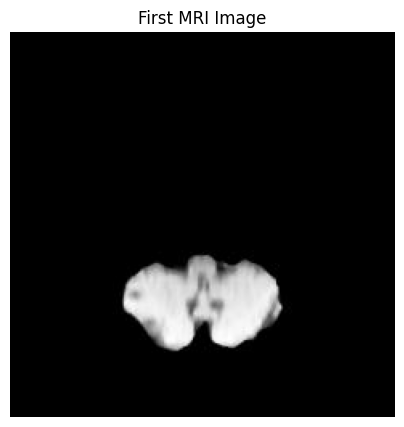

In [8]:

import os
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# 1. Define the dataset paths
csv_path = "/kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor.csv"

image_folder = (
    "/kaggle/input/datasets/jakeshbohaju/"
    "brain-tumor/Brain Tumor/Brain Tumor"
)

# 2. Load the original CSV
df = pd.read_csv(csv_path)

# 3. Keep the 12 features used in our earlier analysis
feature_columns = [
    "Mean",
    "Variance",
    "Standard Deviation",
    "Entropy",
    "Skewness",
    "Kurtosis",
    "Contrast",
    "Energy",
    "ASM",
    "Homogeneity",
    "Dissimilarity",
    "Correlation"
]

# 4. Verify the dataset and image directory
print("Dataset shape:", df.shape)
print("Number of images:", len([
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]))
print("Number of selected features:", len(feature_columns))

# 5. Open the first MRI image
first_image_name = str(df.loc[0, "Image"]).strip() + ".jpg"
first_image_path = os.path.join(image_folder, first_image_name)

image = Image.open(first_image_path).convert("L")
image_array = np.array(image)

print("First image:", first_image_name)
print("Image dimensions (height, width):", image_array.shape)
print("Pixel intensity range:", image_array.min(), "to", image_array.max())

# 6. Display the image
plt.figure(figsize=(5, 5))
plt.imshow(image_array, cmap="gray")
plt.title("First MRI Image")
plt.axis("off")
plt.show()


In [9]:

from scipy.stats import skew, kurtosis, entropy
from skimage.feature import graycomatrix, graycoprops

def extract_features(image_path):
    # Open the MRI image as an 8-bit grayscale image
    img = Image.open(image_path).convert("L")
    arr = np.array(img, dtype=np.uint8)

    # Flatten pixels for intensity-based features
    pixels = arr.flatten().astype(np.float64)

    # Calculate normalized intensity histogram
    hist = np.bincount(arr.flatten(), minlength=256).astype(float)
    probabilities = hist / hist.sum()
    nonzero_probabilities = probabilities[probabilities > 0]

    # Calculate a normalized gray-level co-occurrence matrix
    glcm = graycomatrix(
        arr,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    # Extract numerical features
    features = {
        "Mean": np.mean(pixels),
        "Variance": np.var(pixels),
        "Standard Deviation": np.std(pixels),
        "Entropy": entropy(nonzero_probabilities, base=2),
        "Skewness": skew(pixels),
        "Kurtosis": kurtosis(pixels),
        "Contrast": graycoprops(glcm, "contrast")[0, 0],
        "Energy": graycoprops(glcm, "energy")[0, 0],
        "ASM": graycoprops(glcm, "ASM")[0, 0],
        "Homogeneity": graycoprops(glcm, "homogeneity")[0, 0],
        "Dissimilarity": graycoprops(glcm, "dissimilarity")[0, 0],
        "Correlation": graycoprops(glcm, "correlation")[0, 0]
    }

    return features


# Test the extraction function on five images
sample_results = []

for i in range(5):
    image_name = str(df.loc[i, "Image"]).strip() + ".jpg"
    image_path = os.path.join(image_folder, image_name)

    calculated = extract_features(image_path)

    row = {
        "Image": image_name,
        "Class": df.loc[i, "Class"]
    }

    for feature in feature_columns:
        row[f"{feature} (CSV)"] = df.loc[i, feature]
        row[f"{feature} (calculated)"] = calculated[feature]

    sample_results.append(row)

sample_df = pd.DataFrame(sample_results)
display(sample_df.round(5))


,Image,Class,Mean (CSV),Mean (calculated),Variance (CSV),Variance (calculated),Standard Deviation (CSV),Standard Deviation (calculated),Entropy (CSV),Entropy (calculated),...,Energy (CSV),Energy (calculated),ASM (CSV),ASM (calculated),Homogeneity (CSV),Homogeneity (calculated),Dissimilarity (CSV),Dissimilarity (calculated),Correlation (CSV),Correlation (calculated)
0,Image1.jpg,0,6.53534,14.74816,619.58784,2852.67779,24.89152,53.41047,0.10906,1.06502,...,0.29331,0.90621,0.08603,0.82122,0.53094,0.92472,4.47335,1.03769,0.98194,0.99247
1,Image2.jpg,0,8.74997,19.01340,805.95763,3471.82551,28.38939,58.92220,0.26654,1.45711,...,0.47505,0.86625,0.22567,0.75039,0.65135,0.89329,3.22007,1.35471,0.98883,0.99315
2,Image3.jpg,1,7.34109,43.91387,1143.80822,5029.87045,33.82023,70.92158,0.00147,3.32405,...,0.03192,0.66758,0.00102,0.44566,0.26827,0.72774,5.98180,3.11684,0.97801,0.99147
3,Image4.jpg,1,5.95815,41.68543,959.71198,4729.68804,30.97922,68.77273,0.00148,3.33958,...,0.03202,0.66825,0.00103,0.44656,0.24385,0.72358,7.70092,3.39763,0.96419,0.98941
4,Image5.jpg,0,7.31523,15.65019,729.54058,2993.60414,27.01001,54.71384,0.14676,1.23590,...,0.34385,0.88997,0.11823,0.79205,0.50114,0.90713,6.83469,1.81904,0.97279,0.98615


IMAGE PIXEL STATISTICS
----------------------
Minimum pixel: 0.0
Maximum pixel: 255.0
Mean pixel: 14.748159722222223
Variance: 2852.677791752267
Standard deviation: 53.41046518943892
Unique pixel intensities: 256

CSV VALUES FOR THE SAME IMAGE
-----------------------------
Mean: 6.53533935546875
Variance: 619.587844574841
Standard Deviation: 24.891521539971
Entropy: 0.109059009370733
Skewness: 4.27647702615029
Kurtosis: 18.9005747905553
Contrast: 98.6139705882353
Energy: 0.293314496659804
ASM: 0.086033393950794
Homogeneity: 0.530941131652007
Dissimilarity: 4.47334558823529
Correlation: 0.981938696883038

IMAGE INTENSITY DISTRIBUTION
----------------------------


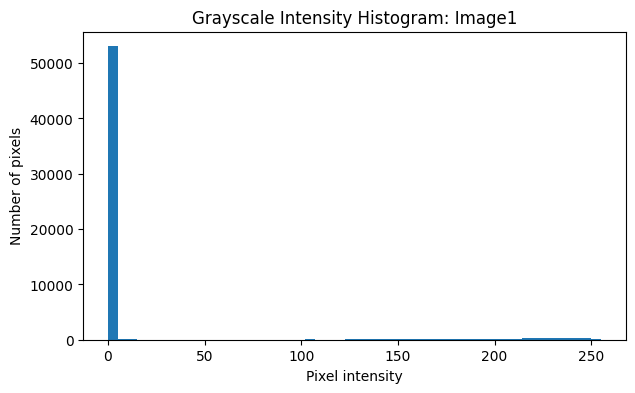


NORMALIZED PIXEL STATISTICS
---------------------------
Normalized mean: 0.05783592047930283
Normalized variance: 0.043870477381811095
Normalized standard deviation: 0.20945280466446634


In [10]:

# Examine the first MRI image and compare its pixel statistics
image_name = str(df.loc[0, "Image"]).strip() + ".jpg"
image_path = os.path.join(image_folder, image_name)

img = Image.open(image_path).convert("L")
arr = np.array(img, dtype=np.float64)

print("IMAGE PIXEL STATISTICS")
print("----------------------")
print("Minimum pixel:", arr.min())
print("Maximum pixel:", arr.max())
print("Mean pixel:", arr.mean())
print("Variance:", arr.var())
print("Standard deviation:", arr.std())
print("Unique pixel intensities:", np.unique(arr).size)

print("\nCSV VALUES FOR THE SAME IMAGE")
print("-----------------------------")
for feature in feature_columns:
    print(f"{feature}: {df.loc[0, feature]}")

print("\nIMAGE INTENSITY DISTRIBUTION")
print("----------------------------")
plt.figure(figsize=(7, 4))
plt.hist(arr.flatten(), bins=50)
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.title("Grayscale Intensity Histogram: Image1")
plt.show()

print("\nNORMALIZED PIXEL STATISTICS")
print("---------------------------")
normalized = arr / 255.0
print("Normalized mean:", normalized.mean())
print("Normalized variance:", normalized.var())
print("Normalized standard deviation:", normalized.std())


In [11]:

# Test whether a simple linear intensity scaling could explain
# the CSV mean and standard deviation for Image1.

csv_mean = float(df.loc[0, "Mean"])
csv_std = float(df.loc[0, "Standard Deviation"])

raw = np.asarray(
    Image.open(first_image_path).convert("L"),
    dtype=np.float64
)

raw_mean = raw.mean()
raw_std = raw.std()

scale = csv_std / raw_std
offset = csv_mean - scale * raw_mean

transformed = scale * raw + offset

print("Scale factor:", scale)
print("Offset:", offset)
print("Transformed minimum:", transformed.min())
print("Transformed maximum:", transformed.max())
print("Target CSV mean:", csv_mean)
print("Transformed mean:", transformed.mean())
print("Target CSV standard deviation:", csv_std)
print("Transformed standard deviation:", transformed.std())


Scale factor: 0.4660420284991808
Offset: -0.33792291810560915
Transformed minimum: -0.33792291810560915
Transformed maximum: 118.5027943491855
Target CSV mean: 6.53533935546875
Transformed mean: 6.53533935546875
Target CSV standard deviation: 24.891521539971
Transformed standard deviation: 24.891521539971


In [12]:

check_indices = [0, 100, 500, 1000, 2000, 3000, 3761]
comparison_rows = []

for idx in check_indices:
    image_name = str(df.loc[idx, "Image"]).strip() + ".jpg"
    image_path = os.path.join(image_folder, image_name)

    arr = np.asarray(
        Image.open(image_path).convert("L"),
        dtype=np.float64
    )

    comparison_rows.append({
        "Image": image_name,
        "CSV mean": df.loc[idx, "Mean"],
        "Raw image mean": arr.mean(),
        "CSV standard deviation": df.loc[idx, "Standard Deviation"],
        "Raw image standard deviation": arr.std(),
        "CSV variance": df.loc[idx, "Variance"],
        "Raw image variance": arr.var()
    })

display(pd.DataFrame(comparison_rows).round(4))


,Image,CSV mean,Raw image mean,CSV standard deviation,Raw image standard deviation,CSV variance,Raw image variance
0,Image1.jpg,6.5353,14.7482,24.8915,53.4105,619.5878,2852.6778
1,Image101.jpg,13.5368,41.3460,28.4790,86.5203,811.0518,7485.7640
2,Image501.jpg,2.8797,18.1336,9.7010,58.4268,94.1088,3413.6899
3,Image1001.jpg,10.3687,30.1493,24.9018,70.4860,620.0972,4968.2731
4,Image2001.jpg,18.5335,53.9092,27.6660,83.4070,765.4054,6956.7310
5,Image3001.jpg,13.7648,50.8317,35.3610,82.4725,1250.4007,6801.7179
6,Image3762.jpg,6.1101,15.5652,21.9291,53.1468,480.8840,2824.5821


In [13]:

# Inspect the supplied feature values without changing them

print("Feature summary:")
display(df[feature_columns].describe().T.round(4))

print("\nMissing values per feature:")
display(df[feature_columns].isna().sum().to_frame("Missing values"))

print("\nCorrelation between CSV mean and variance:")
print(df["Mean"].corr(df["Variance"]))

print("\nCheck whether variance approximately equals SD squared:")
variance_check = pd.DataFrame({
    "CSV variance": df["Variance"],
    "CSV SD squared": df["Standard Deviation"] ** 2
})
variance_check["Absolute difference"] = (
    variance_check["CSV variance"] - variance_check["CSV SD squared"]
).abs()

display(variance_check.describe().round(6))


Feature summary:


,count,mean,std,min,25%,50%,75%,max
Mean,3762.0,9.4889,5.7280,0.0787,4.9824,8.4775,13.2127,33.2400
Variance,3762.0,711.1011,467.4669,3.1456,363.2255,622.5804,966.9543,2910.5819
Standard Deviation,3762.0,25.1823,8.7735,1.7736,19.0585,24.9516,31.0959,53.9498
Entropy,3762.0,0.0736,0.0703,0.0009,0.0069,0.0666,0.1133,0.3945
Skewness,3762.0,4.1027,2.5609,1.8860,2.6202,3.4222,4.6517,36.9313
Kurtosis,3762.0,24.3891,56.4347,3.9424,7.2529,12.3591,22.6403,1371.6401
Contrast,3762.0,127.9615,109.4996,3.1947,72.1252,106.7374,161.0590,3382.5742
Energy,3762.0,0.2047,0.1294,0.0247,0.0696,0.2255,0.2989,0.5897
ASM,3762.0,0.0586,0.0583,0.0006,0.0048,0.0508,0.0893,0.3477
Homogeneity,3762.0,0.4793,0.1279,0.1055,0.3650,0.5126,0.5756,0.8109



Missing values per feature:


,Missing values
Mean,0
Variance,0
Standard Deviation,0
Entropy,0
Skewness,0
Kurtosis,0
Contrast,0
Energy,0
ASM,0
Homogeneity,0



Correlation between CSV mean and variance:
0.7830270695308365

Check whether variance approximately equals SD squared:


,CSV variance,CSV SD squared,Absolute difference
count,3762.000000,3762.000000,3762.0
mean,711.101063,711.101063,0.0
std,467.466896,467.466896,0.0
min,3.145628,3.145628,0.0
25%,363.225459,363.225459,0.0
50%,622.580417,622.580417,0.0
75%,966.954319,966.954319,0.0
max,2910.581879,2910.581879,0.0


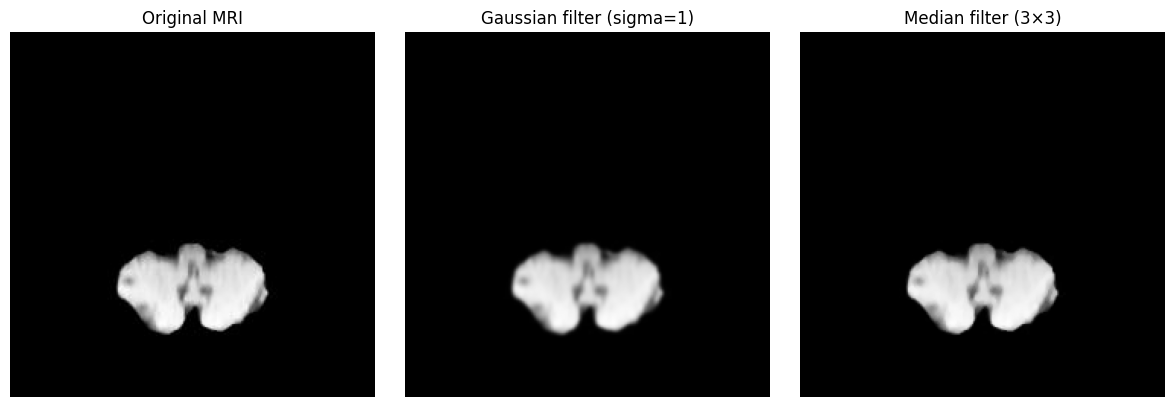

Original shape: (240, 240)
Gaussian shape: (240, 240)
Median shape: (240, 240)
Original intensity range: 0.0 to 255.0
Gaussian intensity range: 0.0 to 252.55
Median intensity range: 0.0 to 254.0


In [14]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, median_filter

# Load one MRI image
image_name = str(df.loc[0, "Image"]).strip() + ".jpg"
image_path = os.path.join(image_folder, image_name)

original = np.asarray(
    Image.open(image_path).convert("L"),
    dtype=np.float32
)

# Apply two image-processing methods
gaussian = gaussian_filter(original, sigma=1.0)
median = median_filter(original, size=3)

# Display the three versions
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original MRI")

axes[1].imshow(gaussian, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Gaussian filter (sigma=1)")

axes[2].imshow(median, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Median filter (3×3)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original shape:", original.shape)
print("Gaussian shape:", gaussian.shape)
print("Median shape:", median.shape)

print("Original intensity range:",
      original.min(), "to", original.max())
print("Gaussian intensity range:",
      round(float(gaussian.min()), 2), "to",
      round(float(gaussian.max()), 2))
print("Median intensity range:",
      round(float(median.min()), 2), "to",
      round(float(median.max()), 2))


In [15]:

from scipy.stats import skew, kurtosis, entropy
from skimage.feature import graycomatrix, graycoprops

def extract_features_from_array(image_array):
    # Convert all versions consistently to 8-bit grayscale
    arr = np.clip(np.rint(image_array), 0, 255).astype(np.uint8)
    pixels = arr.astype(np.float64).ravel()

    # Grayscale histogram entropy, in bits
    hist = np.bincount(arr.ravel(), minlength=256).astype(float)
    probabilities = hist / hist.sum()
    probabilities = probabilities[probabilities > 0]

    # GLCM texture features using the same settings for every image
    glcm = graycomatrix(
        arr,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    return {
        "Mean": np.mean(pixels),
        "Variance": np.var(pixels),
        "Standard Deviation": np.std(pixels),
        "Entropy": entropy(probabilities, base=2),
        "Skewness": skew(pixels),
        "Kurtosis": kurtosis(pixels),
        "Contrast": graycoprops(glcm, "contrast")[0, 0],
        "Energy": graycoprops(glcm, "energy")[0, 0],
        "ASM": graycoprops(glcm, "ASM")[0, 0],
        "Homogeneity": graycoprops(glcm, "homogeneity")[0, 0],
        "Dissimilarity": graycoprops(glcm, "dissimilarity")[0, 0],
        "Correlation": graycoprops(glcm, "correlation")[0, 0]
    }

# Use the arrays created in the previous step
feature_results = {
    "Original": extract_features_from_array(original),
    "Gaussian": extract_features_from_array(gaussian),
    "Median": extract_features_from_array(median)
}

feature_comparison = pd.DataFrame(feature_results)
display(feature_comparison.round(5))

# Calculate change relative to the original image
change_rows = []

for feature in feature_columns:
    original_value = feature_results["Original"][feature]

    for method in ["Gaussian", "Median"]:
        processed_value = feature_results[method][feature]
        absolute_change = processed_value - original_value

        # Percentage change is undefined or unstable near zero
        percentage_change = (
            100 * absolute_change / abs(original_value)
            if abs(original_value) > 1e-12
            else np.nan
        )

        change_rows.append({
            "Feature": feature,
            "Filter": method,
            "Absolute change": absolute_change,
            "Percentage change (%)": percentage_change
        })

change_df = pd.DataFrame(change_rows)
display(change_df.round(5))


,Original,Gaussian,Median
Mean,14.74816,14.74686,14.73549
Variance,2852.67779,2792.26868,2850.08663
Standard Deviation,53.41047,52.84192,53.38620
Entropy,1.06502,1.18966,1.04062
Skewness,3.51932,3.51355,3.51552
Kurtosis,10.77666,10.78215,10.74503
Contrast,43.14331,23.19955,39.70931
Energy,0.90621,0.89686,0.91129
ASM,0.82122,0.80436,0.83044
Homogeneity,0.92472,0.92873,0.93997


,Feature,Filter,Absolute change,Percentage change (%)
0,Mean,Gaussian,-0.00130,-0.00883
1,Mean,Median,-0.01267,-0.08593
2,Variance,Gaussian,-60.40911,-2.11763
3,Variance,Median,-2.59116,-0.09083
4,Standard Deviation,Gaussian,-0.56854,-1.06448
5,Standard Deviation,Median,-0.02426,-0.04543
6,Entropy,Gaussian,0.12464,11.70269
7,Entropy,Median,-0.02440,-2.29139
8,Skewness,Gaussian,-0.00577,-0.16389
9,Skewness,Median,-0.00380,-0.10800


In [16]:

import os
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import gaussian_filter, median_filter
from scipy.stats import skew, kurtosis, entropy
from skimage.feature import graycomatrix, graycoprops

# Use the same extraction function and settings as the pilot experiment
def extract_features_from_array(image_array):
    arr = np.clip(np.rint(image_array), 0, 255).astype(np.uint8)
    pixels = arr.astype(np.float64).ravel()

    hist = np.bincount(arr.ravel(), minlength=256).astype(float)
    probabilities = hist / hist.sum()
    probabilities = probabilities[probabilities > 0]

    glcm = graycomatrix(
        arr,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    return {
        "Mean": np.mean(pixels),
        "Variance": np.var(pixels),
        "Standard Deviation": np.std(pixels),
        "Entropy": entropy(probabilities, base=2),
        "Skewness": skew(pixels),
        "Kurtosis": kurtosis(pixels),
        "Contrast": graycoprops(glcm, "contrast")[0, 0],
        "Energy": graycoprops(glcm, "energy")[0, 0],
        "ASM": graycoprops(glcm, "ASM")[0, 0],
        "Homogeneity": graycoprops(glcm, "homogeneity")[0, 0],
        "Dissimilarity": graycoprops(glcm, "dissimilarity")[0, 0],
        "Correlation": graycoprops(glcm, "correlation")[0, 0]
    }

all_results = []
failed_images = []

for idx, row in df.iterrows():
    image_name = str(row["Image"]).strip() + ".jpg"
    image_path = os.path.join(image_folder, image_name)

    try:
        original_img = np.asarray(
            Image.open(image_path).convert("L"),
            dtype=np.float32
        )

        versions = {
            "Original": original_img,
            "Gaussian": gaussian_filter(original_img, sigma=1.0),
            "Median": median_filter(original_img, size=3)
        }

        for method, image_array in versions.items():
            features = extract_features_from_array(image_array)

            result = {
                "Image": str(row["Image"]),
                "Class": row["Class"],
                "Method": method
            }
            result.update(features)
            all_results.append(result)

    except Exception as e:
        failed_images.append({
            "Image": image_name,
            "Error": str(e)
        })

    if (idx + 1) % 250 == 0:
        print(f"Processed {idx + 1} of {len(df)} images")

results_df = pd.DataFrame(all_results)

print("\nProcessing complete.")
print("Original dataset images:", len(df))
print("Successfully processed images:",
      results_df["Image"].nunique())
print("Rows in results:", len(results_df))
print("Failed images:", len(failed_images))

# Save the full results
results_df.to_csv(
    "/kaggle/working/image_processing_features.csv",
    index=False
)

if failed_images:
    display(pd.DataFrame(failed_images).head(10))

display(results_df.head())


Processed 250 of 3762 images
Processed 500 of 3762 images
Processed 750 of 3762 images
Processed 1000 of 3762 images
Processed 1250 of 3762 images
Processed 1500 of 3762 images
Processed 1750 of 3762 images
Processed 2000 of 3762 images
Processed 2250 of 3762 images
Processed 2500 of 3762 images
Processed 2750 of 3762 images
Processed 3000 of 3762 images
Processed 3250 of 3762 images
Processed 3500 of 3762 images
Processed 3750 of 3762 images

Processing complete.
Original dataset images: 3762
Successfully processed images: 3762
Rows in results: 11286
Failed images: 0


,Image,Class,Method,Mean,Variance,Standard Deviation,Entropy,Skewness,Kurtosis,Contrast,Energy,ASM,Homogeneity,Dissimilarity,Correlation
0,Image1,0,Original,14.748160,2852.677792,53.410465,1.065022,3.519320,10.776655,43.143305,0.906214,0.821224,0.924717,1.037692,0.992467
1,Image1,0,Gaussian,14.746858,2792.268679,52.841922,1.189658,3.513552,10.782148,23.199547,0.896860,0.804359,0.928726,0.854986,0.995862
2,Image1,0,Median,14.735486,2850.086630,53.386203,1.040618,3.515519,10.745028,39.709310,0.911287,0.830444,0.939967,0.897350,0.993060
3,Image2,0,Original,19.013403,3471.825515,58.922199,1.457105,2.966037,7.155495,47.769107,0.866249,0.750387,0.893287,1.354707,0.993146
4,Image2,0,Gaussian,19.011111,3401.029738,58.318348,1.628786,2.966951,7.197712,26.727824,0.850411,0.723198,0.898144,1.110914,0.996085


In [17]:

# Separate the original and filtered measurements
original_df = (
    results_df[results_df["Method"] == "Original"]
    .set_index("Image")
)

summary_rows = []

for method in ["Gaussian", "Median"]:
    filtered_df = (
        results_df[results_df["Method"] == method]
        .set_index("Image")
    )

    for feature in feature_columns:
        # Pair each filtered value with the same image's original value
        original_values = original_df[feature]
        filtered_values = filtered_df[feature]

        absolute_change = filtered_values - original_values

        # Exclude near-zero original values from percentage-change summaries
        valid = original_values.abs() > 1e-12
        percentage_change = (
            100 * absolute_change[valid] / original_values[valid].abs()
        )

        summary_rows.append({
            "Method": method,
            "Feature": feature,
            "Images compared": len(absolute_change),
            "Median absolute change": absolute_change.median(),
            "Median absolute percentage change (%)":
                percentage_change.abs().median(),
            "Median signed percentage change (%)":
                percentage_change.median(),
            "Percentage-change IQR":
                percentage_change.quantile(0.75)
                - percentage_change.quantile(0.25)
        })

summary_df = pd.DataFrame(summary_rows)

display(
    summary_df.round(5)
    .sort_values(
        ["Method", "Median absolute percentage change (%)"],
        ascending=[True, False]
    )
)

summary_df.to_csv(
    "/kaggle/working/image_processing_change_summary.csv",
    index=False
)


,Method,Feature,Images compared,Median absolute change,Median absolute percentage change (%),Median signed percentage change (%),Percentage-change IQR
6,Gaussian,Contrast,3762,-74.37673,67.59927,-67.59927,7.41228
10,Gaussian,Dissimilarity,3762,-0.71278,29.95590,-29.95590,4.33205
3,Gaussian,Entropy,3762,0.19308,8.48859,8.48859,5.22335
8,Gaussian,ASM,3762,-0.02455,4.57316,-4.57316,1.46207
5,Gaussian,Kurtosis,3762,-0.03314,2.79744,-2.37683,6.76015
1,Gaussian,Variance,3762,-108.83225,2.59130,-2.59130,0.98154
7,Gaussian,Energy,3762,-0.01698,2.31334,-2.31334,0.74753
2,Gaussian,Standard Deviation,3762,-0.86351,1.30415,-1.30415,0.49742
9,Gaussian,Homogeneity,3762,0.00986,1.24668,1.24668,1.11175
11,Gaussian,Correlation,3762,0.00889,0.90167,0.90167,0.44232


In [18]:

corrected_rows = []

for method in ["Gaussian", "Median"]:
    filtered_df = (
        results_df[results_df["Method"] == method]
        .set_index("Image")
    )

    for feature in feature_columns:
        original_values = original_df[feature]
        filtered_values = filtered_df[feature]

        absolute_change = filtered_values - original_values
        valid = original_values.abs() > 1e-12

        signed_pct = (
            100 * absolute_change[valid]
            / original_values[valid].abs()
        )

        corrected_rows.append({
            "Method": method,
            "Feature": feature,
            "Median absolute change":
                absolute_change.abs().median(),
            "Median absolute percentage change (%)":
                signed_pct.abs().median(),
            "Median signed percentage change (%)":
                signed_pct.median(),
            "Percentage-change IQR":
                signed_pct.quantile(0.75) - signed_pct.quantile(0.25)
        })

corrected_summary_df = pd.DataFrame(corrected_rows)

display(
    corrected_summary_df.round(5).sort_values(
        ["Method", "Median absolute percentage change (%)"],
        ascending=[True, False]
    )
)

corrected_summary_df.to_csv(
    "/kaggle/working/corrected_image_processing_summary.csv",
    index=False
)


,Method,Feature,Median absolute change,Median absolute percentage change (%),Median signed percentage change (%),Percentage-change IQR
6,Gaussian,Contrast,74.37673,67.59927,-67.59927,7.41228
10,Gaussian,Dissimilarity,0.71278,29.95590,-29.95590,4.33205
3,Gaussian,Entropy,0.19308,8.48859,8.48859,5.22335
8,Gaussian,ASM,0.02455,4.57316,-4.57316,1.46207
5,Gaussian,Kurtosis,0.04088,2.79744,-2.37683,6.76015
1,Gaussian,Variance,108.83225,2.59130,-2.59130,0.98154
7,Gaussian,Energy,0.01698,2.31334,-2.31334,0.74753
2,Gaussian,Standard Deviation,0.86351,1.30415,-1.30415,0.49742
9,Gaussian,Homogeneity,0.00986,1.24668,1.24668,1.11175
11,Gaussian,Correlation,0.00889,0.90167,0.90167,0.44232


In [129]:

# Confirm that every image has exactly three processing versions

version_counts = results_df.groupby("Image")["Method"].nunique()

print("Unique images:", results_df["Image"].nunique())
print("Images with all 3 versions:", (version_counts == 3).sum())
print("Images missing a version:", (version_counts != 3).sum())

print("\nRecords per method:")
display(results_df["Method"].value_counts().to_frame("Number of records"))

print("\nClass distribution:")
display(
    df["Class"].value_counts().sort_index()
    .to_frame("Number of images")
)


Unique images: 3762
Images with all 3 versions: 3762
Images missing a version: 0

Records per method:


,Number of records
Method,
Original,3762
Gaussian,3762
Median,3762



Class distribution:


,Number of images
Class,
0,2079
1,1683


In [19]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Create a label mapping from the original dataset
label_map = df.set_index("Image")["Class"].to_dict()

# Confirm that image IDs match between the dataset and extracted results
assert set(results_df["Image"].unique()) == set(label_map.keys()), (
    "Image IDs do not match between the original dataset and extracted results."
)

# 2. Split image IDs BEFORE selecting their processing versions
image_ids = df["Image"].tolist()
labels = df.set_index("Image").loc[image_ids, "Class"].to_numpy()

train_ids, test_ids = train_test_split(
    image_ids,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

train_id_set = set(train_ids)
test_id_set = set(test_ids)

print("Training images:", len(train_ids))
print("Testing images:", len(test_ids))
print("Overlap between training and test:",
      len(train_id_set & test_id_set))

# 3. Extract the original-image training features only
original_data = results_df[results_df["Method"] == "Original"].copy()

train_data = (
    original_data[original_data["Image"].isin(train_id_set)]
    .set_index("Image")
    .loc[train_ids]
)

y_train = train_data["Class"].to_numpy()
X_train = train_data[feature_columns]

# 4. Train the model using original images only
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

model.fit(X_train, y_train)

# 5. Evaluate the same test images in all three conditions
evaluation_rows = []

for method in ["Original", "Gaussian", "Median"]:
    test_data = (
        results_df[
            (results_df["Method"] == method)
            & (results_df["Image"].isin(test_id_set))
        ]
        .set_index("Image")
        .loc[test_ids]
    )

    X_test = test_data[feature_columns]
    y_test = test_data["Class"].to_numpy()

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    evaluation_rows.append({
        "Test condition": method,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan
    })

classification_results = pd.DataFrame(evaluation_rows)

display(classification_results.round(4))

classification_results.to_csv(
    "/kaggle/working/logistic_regression_filter_robustness.csv",
    index=False
)


Training images: 3009
Testing images: 753
Overlap between training and test: 0


,Test condition,Accuracy,Balanced accuracy,ROC-AUC,Sensitivity,Specificity
0,Original,0.8367,0.8330,0.9275,0.7982,0.8678
1,Gaussian,0.6521,0.6840,0.9151,0.9881,0.3798
2,Median,0.6853,0.7123,0.9140,0.9703,0.4543


In [20]:

import hashlib
from collections import defaultdict
from scipy.fft import dctn
from scipy.spatial.distance import cdist

# 1. Exact duplicate check using file contents
hash_to_images = defaultdict(list)

for image_id in df["Image"].astype(str):
    image_path = os.path.join(image_folder, image_id.strip() + ".jpg")

    with open(image_path, "rb") as f:
        file_hash = hashlib.sha256(f.read()).hexdigest()

    hash_to_images[file_hash].append(image_id)

exact_groups = [
    ids for ids in hash_to_images.values() if len(ids) > 1
]

print("Exact duplicate groups:", len(exact_groups))
print("Images involved in exact duplicate groups:",
      sum(len(group) for group in exact_groups))

# 2. Perceptual hash: compact representation of visual appearance
def perceptual_hash(image_path):
    img = Image.open(image_path).convert("L").resize((32, 32))
    arr = np.asarray(img, dtype=np.float32)

    coefficients = dctn(arr, norm="ortho")[:8, :8]
    values = coefficients.flatten()[1:]  # exclude DC component
    median_value = np.median(values)

    bits = values > median_value
    return bits.astype(np.uint8)

image_ids_for_hash = df["Image"].astype(str).tolist()
hashes = []

for image_id in image_ids_for_hash:
    path = os.path.join(image_folder, image_id.strip() + ".jpg")
    hashes.append(perceptual_hash(path))

hash_matrix = np.vstack(hashes)

# Pairwise Hamming distance between hashes
distances = cdist(hash_matrix, hash_matrix, metric="hamming") * hash_matrix.shape[1]

# Avoid counting each pair twice or comparing an image with itself
pairs = []
for i in range(len(image_ids_for_hash)):
    for j in range(i + 1, len(image_ids_for_hash)):
        distance = int(round(distances[i, j]))
        if distance <= 4:
            pairs.append({
                "Image 1": image_ids_for_hash[i],
                "Image 2": image_ids_for_hash[j],
                "Hash distance": distance,
                "Same class": (
                    df.iloc[i]["Class"] == df.iloc[j]["Class"]
                )
            })

pairs_df = pd.DataFrame(
    pairs,
    columns=["Image 1", "Image 2", "Hash distance", "Same class"]
)

print("\nPotential near-duplicate pairs (hash distance <= 4):",
      len(pairs_df))
display(pairs_df.head(30))


Exact duplicate groups: 50
Images involved in exact duplicate groups: 113

Potential near-duplicate pairs (hash distance <= 4): 12141


,Image 1,Image 2,Hash distance,Same class
0,Image3,Image593,4,True
1,Image3,Image1027,4,True
2,Image3,Image1816,4,True
3,Image3,Image2348,2,True
4,Image3,Image2349,4,True
5,Image4,Image437,4,True
6,Image4,Image1027,4,True
7,Image4,Image1031,4,True
8,Image4,Image1631,4,True
9,Image4,Image2302,4,True


In [132]:
print("Potential near-duplicate pairs:", len(pairs_df))
display(pairs_df.head(30))


Potential near-duplicate pairs: 12141


,Image 1,Image 2,Hash distance,Same class
0,Image3,Image593,4,True
1,Image3,Image1027,4,True
2,Image3,Image1816,4,True
3,Image3,Image2348,2,True
4,Image3,Image2349,4,True
5,Image4,Image437,4,True
6,Image4,Image1027,4,True
7,Image4,Image1031,4,True
8,Image4,Image1631,4,True
9,Image4,Image2302,4,True


In [133]:
# Summarize candidate pairs at stricter perceptual-hash thresholds

for threshold in [0, 1, 2, 3, 4]:
    subset = pairs_df[pairs_df["Hash distance"] <= threshold]

    print(f"\nHash distance <= {threshold}")
    print("Candidate pairs:", len(subset))

    if len(subset) > 0:
        print("Pairs with same class:",
              int(subset["Same class"].sum()))
        print("Pairs with different classes:",
              int((~subset["Same class"]).sum()))


Hash distance <= 0
Candidate pairs: 840
Pairs with same class: 801
Pairs with different classes: 39

Hash distance <= 1
Candidate pairs: 840
Pairs with same class: 801
Pairs with different classes: 39

Hash distance <= 2
Candidate pairs: 3744
Pairs with same class: 3572
Pairs with different classes: 172

Hash distance <= 3
Candidate pairs: 3744
Pairs with same class: 3572
Pairs with different classes: 172

Hash distance <= 4
Candidate pairs: 12141
Pairs with same class: 11151
Pairs with different classes: 990


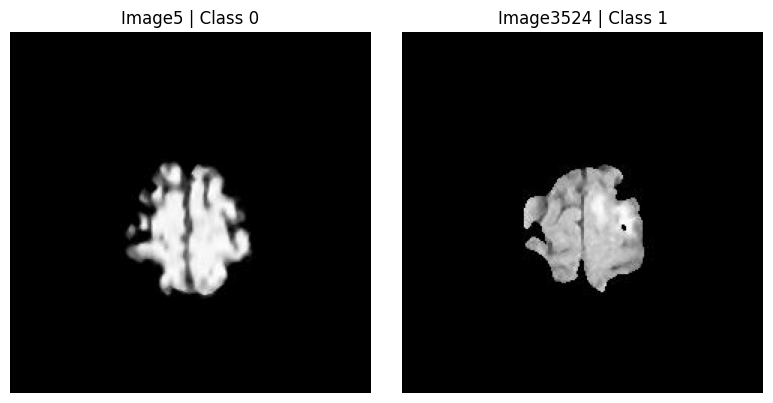

In [134]:
import os
import matplotlib.pyplot as plt
from PIL import Image

images_to_check = ["Image5", "Image3524"]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, image_id in zip(axes, images_to_check):
    path = os.path.join(image_folder, image_id + ".jpg")
    img = Image.open(path).convert("L")

    label = df.loc[df["Image"].astype(str) == image_id, "Class"].iloc[0]

    ax.imshow(img, cmap="gray")
    ax.set_title(f"{image_id} | Class {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [27]:
import os
import hashlib
from collections import defaultdict
import numpy as np
from PIL import Image

# Group images by the hash of their decoded grayscale pixels
pixel_hash_groups = defaultdict(list)

for image_id in df["Image"].astype(str):
    path = os.path.join(image_folder, image_id.strip() + ".jpg")

    with Image.open(path) as img:
        pixels = np.asarray(img.convert("L"))

    # Include image dimensions to avoid grouping differently shaped arrays
    h = hashlib.sha256()
    h.update(str(pixels.shape).encode())
    h.update(pixels.tobytes())

    pixel_hash_groups[h.hexdigest()].append(image_id)

pixel_duplicate_groups = [
    ids for ids in pixel_hash_groups.values() if len(ids) > 1
]

print("Pixel-identical duplicate groups:", len(pixel_duplicate_groups))
print(
    "Images in pixel-identical duplicate groups:",
    sum(len(group) for group in pixel_duplicate_groups)
)

# Check whether duplicate images have conflicting class labels
class_lookup = df.set_index(df["Image"].astype(str))["Class"].to_dict()

conflicting_groups = []
for group in pixel_duplicate_groups:
    labels = {class_lookup[image_id] for image_id in group}
    if len(labels) > 1:
        conflicting_groups.append(group)

print("Groups with conflicting class labels:", len(conflicting_groups))
print("Examples of conflicting groups:", conflicting_groups[:10])

Pixel-identical duplicate groups: 50
Images in pixel-identical duplicate groups: 113
Groups with conflicting class labels: 0
Examples of conflicting groups: []


In [28]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Give identical images the same group ID.
# Unique images each get their own group.
image_to_group = {}

for group_number, ids in enumerate(pixel_hash_groups.values()):
    for image_id in ids:
        image_to_group[image_id] = group_number

# Attach group IDs to the dataset
df_grouped = df.copy()
df_grouped["duplicate_group"] = (
    df_grouped["Image"].astype(str).map(image_to_group)
)

print("Total images:", len(df_grouped))
print("Unique duplicate groups:", df_grouped["duplicate_group"].nunique())
print("Images without a group:", df_grouped["duplicate_group"].isna().sum())

# Split groups, not individual images
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df_grouped,
        y=df_grouped["Class"],
        groups=df_grouped["duplicate_group"]
    )
)

train_df = df_grouped.iloc[train_idx].copy()
test_df = df_grouped.iloc[test_idx].copy()

train_groups = set(train_df["duplicate_group"])
test_groups = set(test_df["duplicate_group"])

print("\nTraining images:", len(train_df))
print("Testing images:", len(test_df))
print("Groups shared between train and test:", len(train_groups & test_groups))

print("\nTraining class counts:")
print(train_df["Class"].value_counts().sort_index())

print("\nTesting class counts:")
print(test_df["Class"].value_counts().sort_index())

Total images: 3762
Unique duplicate groups: 3699
Images without a group: 0

Training images: 3016
Testing images: 746
Groups shared between train and test: 0

Training class counts:
Class
0    1663
1    1353
Name: count, dtype: int64

Testing class counts:
Class
0    416
1    330
Name: count, dtype: int64


In [29]:
import pandas as pd
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, roc_auc_score,
    confusion_matrix
)

# Load the previously saved features
features_df = pd.read_csv(
    "/kaggle/working/image_processing_features.csv"
)

feature_columns = [
    "Mean", "Variance", "Standard Deviation", "Entropy",
    "Skewness", "Kurtosis", "Contrast", "Energy", "ASM",
    "Homogeneity", "Dissimilarity", "Correlation"
]

print("Available processing methods:",
      features_df["Method"].unique())

# Image IDs and labels from the leakage-safe split
train_ids = set(train_df["Image"].astype(str))
test_ids = set(test_df["Image"].astype(str))

label_lookup = df.set_index(
    df["Image"].astype(str)
)["Class"].to_dict()

# Use only original-image features for training
original_features = features_df[
    features_df["Method"] == "Original"
].copy()
original_features["Image"] = original_features["Image"].astype(str)

train_data = original_features[
    original_features["Image"].isin(train_ids)
].copy()

# Train the model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

X_train = train_data[feature_columns]
y_train = train_data["Image"].map(label_lookup)

model.fit(X_train, y_train)

# Evaluate the same held-out images under all three conditions
results = []

for method in ["Original", "Gaussian", "Median"]:
    test_data = features_df[
        (features_df["Method"] == method) &
        (features_df["Image"].astype(str).isin(test_ids))
    ].copy()

    test_data["Image"] = test_data["Image"].astype(str)
    test_data = (
        test_data.set_index("Image")
        .reindex(test_df["Image"].astype(str))
        .reset_index()
    )

    if test_data[feature_columns].isna().any().any():
        raise ValueError(
            f"Missing feature values for method: {method}"
        )

    y_test = test_data["Image"].map(label_lookup).to_numpy()
    X_test = test_data[feature_columns]

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Condition": method,
        "N": len(test_data),
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan
    })

results_df = pd.DataFrame(results)

print("\nLeakage-safe classification results:")
display(results_df.round(4))

results_df.to_csv(
    "/kaggle/working/logistic_regression_grouped_robustness.csv",
    index=False
)
print("Saved results to logistic_regression_grouped_robustness.csv")

Available processing methods: ['Original' 'Gaussian' 'Median']

Leakage-safe classification results:


,Condition,N,Accuracy,Balanced accuracy,ROC-AUC,Sensitivity,Specificity
0,Original,746,0.8512,0.8484,0.9306,0.8242,0.8726
1,Gaussian,746,0.6488,0.6823,0.9166,0.9727,0.3918
2,Median,746,0.6756,0.7047,0.9133,0.9576,0.4519


Saved results to logistic_regression_grouped_robustness.csv


In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, roc_auc_score,
    confusion_matrix
)
import pandas as pd
import numpy as np

# Train Random Forest using only original-image features
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight=None,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_results = []

for method in ["Original", "Gaussian", "Median"]:
    test_data = features_df[
        (features_df["Method"] == method) &
        (features_df["Image"].astype(str).isin(test_ids))
    ].copy()

    test_data["Image"] = test_data["Image"].astype(str)
    test_data = (
        test_data.set_index("Image")
        .reindex(test_df["Image"].astype(str))
        .reset_index()
    )

    X_test = test_data[feature_columns]
    y_test = test_data["Image"].map(label_lookup).to_numpy()

    predictions = rf_model.predict(X_test)
    probabilities = rf_model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    rf_results.append({
        "Condition": method,
        "N": len(test_data),
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp)
    })

rf_results_df = pd.DataFrame(rf_results)

print("Random Forest — duplicate-safe evaluation")
display(rf_results_df.round(4))

rf_results_df.to_csv(
    "/kaggle/working/random_forest_grouped_robustness.csv",
    index=False
)

print("Saved: random_forest_grouped_robustness.csv")

Random Forest — duplicate-safe evaluation


,Condition,N,Accuracy,Balanced accuracy,ROC-AUC,Sensitivity,Specificity
0,Original,746,0.8807,0.8767,0.9492,0.8424,0.9111
1,Gaussian,746,0.7145,0.7371,0.8917,0.9333,0.5409
2,Median,746,0.7895,0.8016,0.9109,0.9061,0.6971


Saved: random_forest_grouped_robustness.csv


In [31]:
import pandas as pd

summary_path = "/kaggle/working/corrected_image_processing_summary.csv"
summary_df = pd.read_csv(summary_path)

print("Columns available in the corrected summary:")
print(summary_df.columns.tolist())

display(summary_df)

Columns available in the corrected summary:
['Method', 'Feature', 'Median absolute change', 'Median absolute percentage change (%)', 'Median signed percentage change (%)', 'Percentage-change IQR']


,Method,Feature,Median absolute change,Median absolute percentage change (%),Median signed percentage change (%),Percentage-change IQR
0,Gaussian,Mean,0.001458,0.004806,-0.004806,0.003490
1,Gaussian,Variance,108.832247,2.591296,-2.591296,0.981541
2,Gaussian,Standard Deviation,0.863515,1.304152,-1.304152,0.497421
3,Gaussian,Entropy,0.193076,8.488590,8.488590,5.223351
4,Gaussian,Skewness,0.014253,0.830876,-0.830876,1.022977
5,Gaussian,Kurtosis,0.040878,2.797444,-2.376834,6.760147
6,Gaussian,Contrast,74.376726,67.599271,-67.599271,7.412283
7,Gaussian,Energy,0.016979,2.313339,-2.313339,0.747532
8,Gaussian,ASM,0.024551,4.573162,-4.573162,1.462068
9,Gaussian,Homogeneity,0.009858,1.246684,1.246684,1.111750


In [32]:

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix

# --------------------------------------------------
# 1. Prepare training and test features
# --------------------------------------------------
feature_columns = [
    "Mean", "Variance", "Standard Deviation", "Entropy",
    "Skewness", "Kurtosis", "Contrast", "Energy", "ASM",
    "Homogeneity", "Dissimilarity", "Correlation"
]

label_lookup = df.set_index(
    df["Image"].astype(str)
)["Class"].to_dict()

train_ids = train_df["Image"].astype(str).tolist()
test_ids = test_df["Image"].astype(str).tolist()

original = features_df[
    features_df["Method"] == "Original"
].copy()
original["Image"] = original["Image"].astype(str)
original = original.set_index("Image")

X_train = original.reindex(train_ids)[feature_columns]
y_train = np.array([label_lookup[i] for i in train_ids])

if X_train.isna().any().any():
    raise ValueError("Missing training features detected.")

# Train both models using original-image features
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

for model in models.values():
    model.fit(X_train, y_train)

# --------------------------------------------------
# 2. Get aligned predictions for every condition
# --------------------------------------------------
conditions = ["Original", "Gaussian", "Median"]
y_test = np.array([label_lookup[i] for i in test_ids])

predictions = {}
probabilities = {}

for method in conditions:
    part = features_df[
        features_df["Method"] == method
    ].copy()
    part["Image"] = part["Image"].astype(str)
    part = part.set_index("Image").reindex(test_ids)

    if part[feature_columns].isna().any().any():
        raise ValueError(f"Missing test features for {method}.")

    X_test = part[feature_columns]

    for model_name, model in models.items():
        key = (model_name, method)
        predictions[key] = model.predict(X_test)
        probabilities[key] = model.predict_proba(X_test)[:, 1]

# --------------------------------------------------
# 3. Stratified bootstrap confidence intervals
# --------------------------------------------------
rng = np.random.default_rng(2026)
n_bootstrap = 2000

class0_idx = np.where(y_test == 0)[0]
class1_idx = np.where(y_test == 1)[0]

def calculate_metrics(y, pred, prob):
    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "ROC-AUC": roc_auc_score(y, prob),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp)
    }

rows = []

for model_name in models:
    for method in conditions:
        key = (model_name, method)
        pred = predictions[key]
        prob = probabilities[key]

        point = calculate_metrics(y_test, pred, prob)
        boot_values = {
            metric: [] for metric in point
        }

        for _ in range(n_bootstrap):
            # Resample each class separately
            sample0 = rng.choice(
                class0_idx, size=len(class0_idx), replace=True
            )
            sample1 = rng.choice(
                class1_idx, size=len(class1_idx), replace=True
            )
            sample_idx = np.concatenate([sample0, sample1])

            metrics = calculate_metrics(
                y_test[sample_idx],
                pred[sample_idx],
                prob[sample_idx]
            )

            for metric, value in metrics.items():
                boot_values[metric].append(value)

        for metric, estimate in point.items():
            lower, upper = np.percentile(
                boot_values[metric], [2.5, 97.5]
            )

            rows.append({
                "Model": model_name,
                "Condition": method,
                "Metric": metric,
                "Estimate": estimate,
                "95% CI lower": lower,
                "95% CI upper": upper,
                "Bootstrap repetitions": n_bootstrap
            })

ci_results = pd.DataFrame(rows)

display(ci_results.round(4))

output_path = (
    "/kaggle/working/bootstrap_confidence_intervals.csv"
)
ci_results.to_csv(output_path, index=False)
print("Saved:", output_path)


,Model,Condition,Metric,Estimate,95% CI lower,95% CI upper,Bootstrap repetitions
0,Logistic Regression,Original,ROC-AUC,0.9306,0.9124,0.9475,2000
1,Logistic Regression,Original,Sensitivity,0.8242,0.7848,0.8636,2000
2,Logistic Regression,Original,Specificity,0.8726,0.8389,0.9038,2000
3,Logistic Regression,Gaussian,ROC-AUC,0.9166,0.8962,0.9362,2000
4,Logistic Regression,Gaussian,Sensitivity,0.9727,0.9545,0.9879,2000
5,Logistic Regression,Gaussian,Specificity,0.3918,0.3461,0.4375,2000
6,Logistic Regression,Median,ROC-AUC,0.9133,0.8924,0.9339,2000
7,Logistic Regression,Median,Sensitivity,0.9576,0.9363,0.9788,2000
8,Logistic Regression,Median,Specificity,0.4519,0.4038,0.5001,2000
9,Random Forest,Original,ROC-AUC,0.9492,0.9347,0.9623,2000


Saved: /kaggle/working/bootstrap_confidence_intervals.csv


In [33]:

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix

# 1. Prepare image IDs and labels
data = df.copy()
data["Image"] = data["Image"].astype(str)
label_lookup = data.set_index("Image")["Class"].to_dict()

# 2. Reconstruct duplicate groups from the pixel-hash audit.
# Images with identical decoded pixels must stay in the same split.
group_lookup = {}

for group_number, image_ids in enumerate(pixel_hash_groups.values()):
    for image_id in image_ids:
        group_lookup[str(image_id)] = f"duplicate_group_{group_number}"

# Images not included in a duplicate group remain individual groups.
data["group_id"] = [
    group_lookup.get(image_id, f"unique_{image_id}")
    for image_id in data["Image"]
]

# 3. Prepare features for each processing condition
feature_data = {}

for method in ["Original", "Gaussian", "Median"]:
    part = features_df[features_df["Method"] == method].copy()
    part["Image"] = part["Image"].astype(str)
    feature_data[method] = part.set_index("Image")

# Check that all required features are present
all_ids = data["Image"].tolist()

for method, part in feature_data.items():
    if part.reindex(all_ids)[feature_columns].isna().any().any():
        raise ValueError(f"Missing feature values in {method} data.")

# 4. Define models and metric calculation
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

def get_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn)
    }

# 5. Run five different group-aware splits
X_original = feature_data["Original"].reindex(all_ids)[feature_columns]
y_all = data["Class"].to_numpy()
groups = data["group_id"].to_numpy()

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.20,
    random_state=2026
)

rows = []

for split_number, (train_idx, test_idx) in enumerate(
    splitter.split(X_original, y_all, groups), start=1
):
    train_ids = data.iloc[train_idx]["Image"].tolist()
    test_ids = data.iloc[test_idx]["Image"].tolist()

    y_train = data.iloc[train_idx]["Class"].to_numpy()
    y_test = data.iloc[test_idx]["Class"].to_numpy()

    # Train only on original-image features
    X_train = feature_data["Original"].reindex(train_ids)[feature_columns]

    for model_name, model_template in models.items():
        # Create a fresh model for every split
        from sklearn.base import clone
        model = clone(model_template)
        model.fit(X_train, y_train)

        # Evaluate identical test images under each condition
        for method in ["Original", "Gaussian", "Median"]:
            X_test = (
                feature_data[method]
                .reindex(test_ids)[feature_columns]
            )

            y_pred = model.predict(X_test)
            y_prob = model.predict_proba(X_test)[:, 1]

            metrics = get_metrics(y_test, y_pred, y_prob)

            for metric, value in metrics.items():
                rows.append({
                    "Split": split_number,
                    "Model": model_name,
                    "Condition": method,
                    "Metric": metric,
                    "Value": value
                })

repeated_results = pd.DataFrame(rows)

# 6. Summarize performance across the five splits
summary = (
    repeated_results
    .groupby(["Model", "Condition", "Metric"])["Value"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "Mean across splits",
        "std": "SD across splits"
    })
)

display(summary.round(4))

repeated_results.to_csv(
    "/kaggle/working/repeated_grouped_validation_raw.csv",
    index=False
)
summary.to_csv(
    "/kaggle/working/repeated_grouped_validation_summary.csv",
    index=False
)

print("Completed: five group-aware splits.")
print("Saved repeated validation results in /kaggle/working/")


,Model,Condition,Metric,Mean across splits,SD across splits
0,Logistic Regression,Gaussian,Accuracy,0.6609,0.0115
1,Logistic Regression,Gaussian,ROC-AUC,0.9276,0.0094
2,Logistic Regression,Gaussian,Sensitivity,0.9881,0.0064
3,Logistic Regression,Gaussian,Specificity,0.3971,0.0153
4,Logistic Regression,Median,Accuracy,0.6889,0.0120
5,Logistic Regression,Median,ROC-AUC,0.9249,0.0090
6,Logistic Regression,Median,Sensitivity,0.9768,0.0084
7,Logistic Regression,Median,Specificity,0.4567,0.0160
8,Logistic Regression,Original,Accuracy,0.8544,0.0100
9,Logistic Regression,Original,ROC-AUC,0.9387,0.0062


Completed: five group-aware splits.
Saved repeated validation results in /kaggle/working/


In [35]:

# Calculate paired metric changes relative to Original

wide = repeated_results.pivot(
    index=["Split", "Model", "Metric"],
    columns="Condition",
    values="Value"
).reset_index()

wide["Gaussian change"] = wide["Gaussian"] - wide["Original"]
wide["Median change"] = wide["Median"] - wide["Original"]

change_rows = []

for (model, metric), group in wide.groupby(["Model", "Metric"]):
    for condition in ["Gaussian", "Median"]:
        change = group[f"{condition} change"]

        change_rows.append({
            "Model": model,
            "Metric": metric,
            "Filter": condition,
            "Mean change": change.mean(),
            "SD of change": change.std(ddof=1),
            "Splits": change.notna().sum()
        })

change_summary = pd.DataFrame(change_rows)

display(change_summary.round(4))

change_summary.to_csv(
    "/kaggle/working/paired_filter_changes.csv",
    index=False
)

print("Saved paired changes to /kaggle/working/paired_filter_changes.csv")


,Model,Metric,Filter,Mean change,SD of change,Splits
0,Logistic Regression,Accuracy,Gaussian,-0.1935,0.0181,5
1,Logistic Regression,Accuracy,Median,-0.1655,0.0158,5
2,Logistic Regression,ROC-AUC,Gaussian,-0.0111,0.0041,5
3,Logistic Regression,ROC-AUC,Median,-0.0138,0.0034,5
4,Logistic Regression,Sensitivity,Gaussian,0.1623,0.0162,5
5,Logistic Regression,Sensitivity,Median,0.1510,0.0186,5
6,Logistic Regression,Specificity,Gaussian,-0.4809,0.0169,5
7,Logistic Regression,Specificity,Median,-0.4213,0.0139,5
8,Random Forest,Accuracy,Gaussian,-0.1692,0.0323,5
9,Random Forest,Accuracy,Median,-0.0830,0.0243,5


Saved paired changes to /kaggle/working/paired_filter_changes.csv


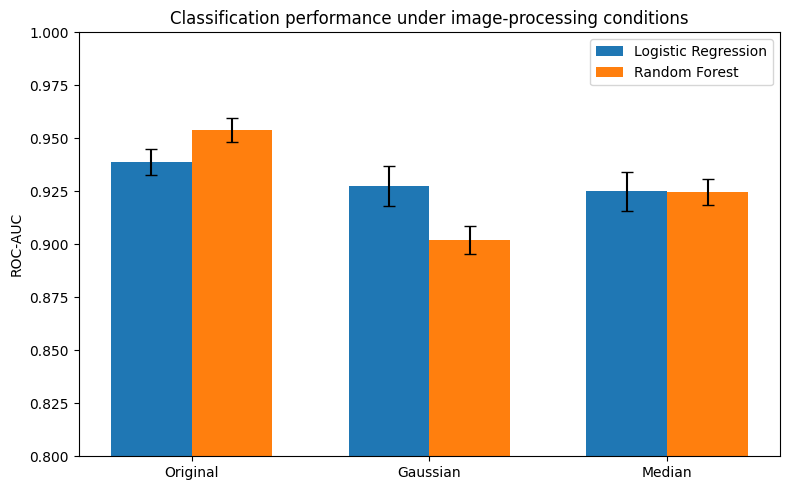

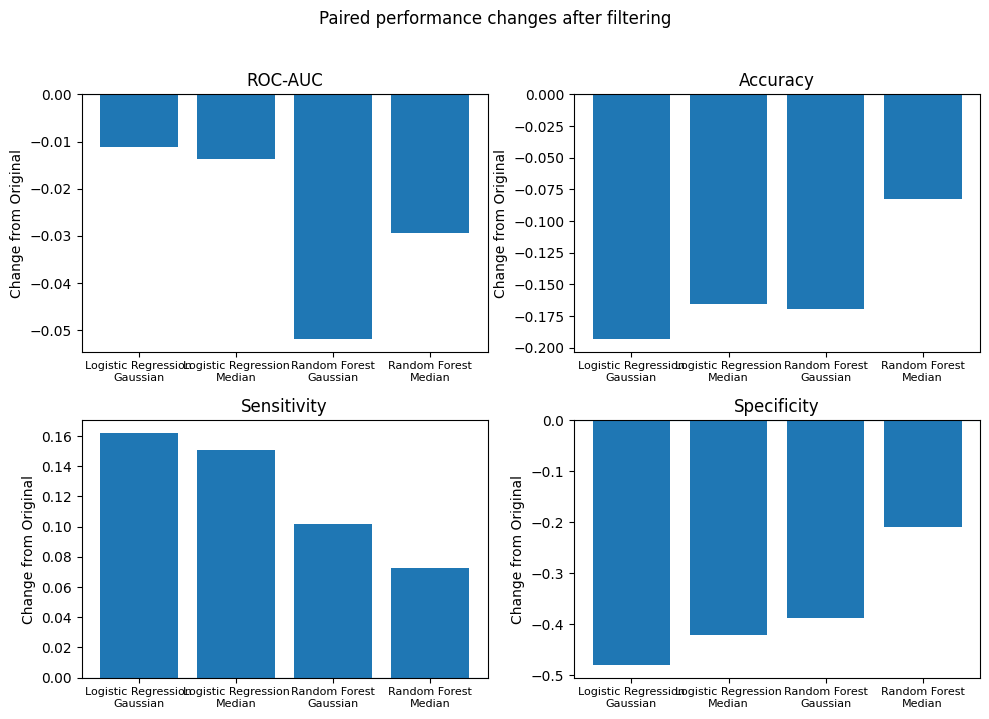

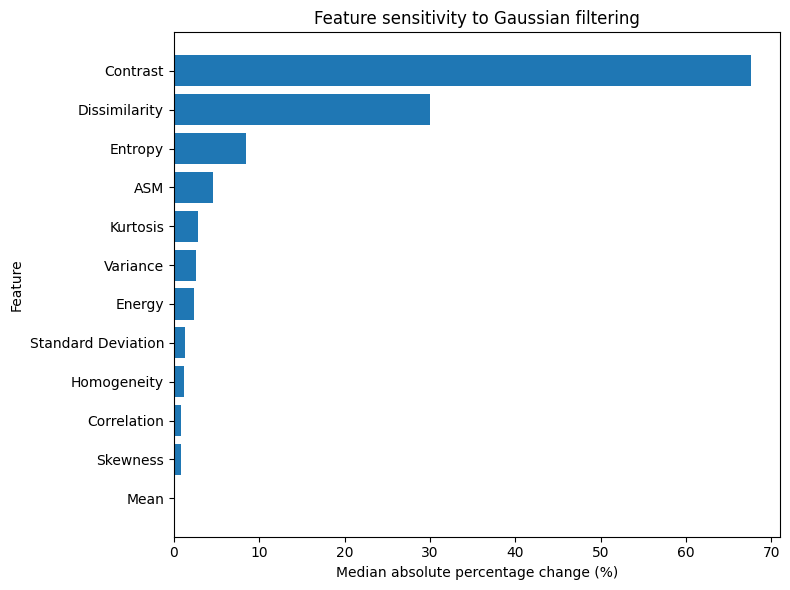

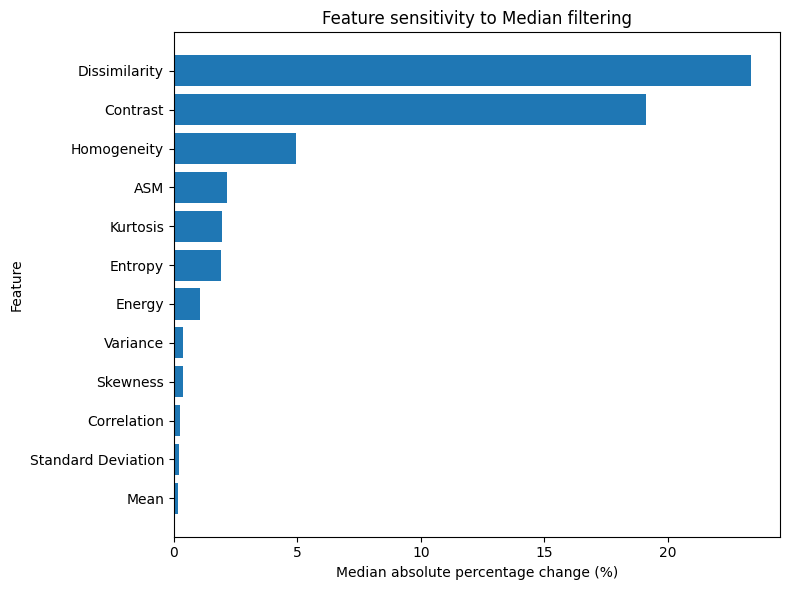

Figures saved in: /kaggle/working
Figure 1: ROC-AUC comparison
Figure 2: Paired performance changes
Figure 3: Feature sensitivity (Gaussian and Median)


In [36]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("/kaggle/working")
conditions = ["Original", "Gaussian", "Median"]
models = ["Logistic Regression", "Random Forest"]

# Figure 1: ROC-AUC across five group-aware splits
auc_data = repeated_results[
    repeated_results["Metric"] == "ROC-AUC"
].copy()

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(conditions))
width = 0.34

for i, model_name in enumerate(models):
    stats = (
        auc_data[auc_data["Model"] == model_name]
        .groupby("Condition")["Value"]
        .agg(["mean", "std"])
        .reindex(conditions)
    )

    ax.bar(
        x + (i - 0.5) * width,
        stats["mean"],
        width,
        yerr=stats["std"],
        capsize=4,
        label=model_name
    )

ax.set_xticks(x)
ax.set_xticklabels(conditions)
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0.80, 1.00)
ax.set_title("Classification performance under image-processing conditions")
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "Figure1_ROC_AUC.png", dpi=300)
plt.show()


# Figure 2: Mean paired changes caused by filtering
metrics_to_plot = [
    "ROC-AUC", "Accuracy", "Sensitivity", "Specificity"
]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.flatten()

for ax, metric in zip(axes, metrics_to_plot):
    subset = change_summary[change_summary["Metric"] == metric]

    labels = []
    values = []

    for model_name in models:
        for filt in ["Gaussian", "Median"]:
            row = subset[
                (subset["Model"] == model_name) &
                (subset["Filter"] == filt)
            ].iloc[0]

            labels.append(f"{model_name}\n{filt}")
            values.append(row["Mean change"])

    ax.bar(labels, values)
    ax.axhline(0, linewidth=0.8)
    ax.set_title(metric)
    ax.set_ylabel("Change from Original")
    ax.tick_params(axis="x", labelsize=8)

fig.suptitle("Paired performance changes after filtering", y=1.02)
fig.tight_layout()
fig.savefig(output_dir / "Figure2_Paired_Changes.png",
            dpi=300, bbox_inches="tight")
plt.show()


# Figure 3: Feature sensitivity to filtering
summary_path = output_dir / "corrected_image_processing_summary.csv"
feature_summary = pd.read_csv(summary_path)

for method in ["Gaussian", "Median"]:
    part = feature_summary[
        feature_summary["Method"] == method
    ].sort_values("Median absolute percentage change (%)")

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(
        part["Feature"],
        part["Median absolute percentage change (%)"]
    )
    ax.set_xlabel("Median absolute percentage change (%)")
    ax.set_ylabel("Feature")
    ax.set_title(f"Feature sensitivity to {method} filtering")
    fig.tight_layout()
    fig.savefig(
        output_dir / f"Figure3_{method}_Feature_Sensitivity.png",
        dpi=300
    )
    plt.show()

print("Figures saved in:", output_dir)
print("Figure 1: ROC-AUC comparison")
print("Figure 2: Paired performance changes")
print("Figure 3: Feature sensitivity (Gaussian and Median)")


In [37]:

# Final consistency check across the five group-aware splits

consistency_rows = []

for (model, metric), group in wide.groupby(["Model", "Metric"]):
    for condition in ["Gaussian", "Median"]:
        changes = group[f"{condition} change"].dropna()

        consistency_rows.append({
            "Model": model,
            "Metric": metric,
            "Filter": condition,
            "Mean change": changes.mean(),
            "Minimum change": changes.min(),
            "Maximum change": changes.max(),
            "Splits showing decrease": int((changes < 0).sum()),
            "Splits showing increase": int((changes > 0).sum()),
            "Splits unchanged": int((changes == 0).sum())
        })

consistency_check = pd.DataFrame(consistency_rows)

display(consistency_check.round(4))

consistency_check.to_csv(
    "/kaggle/working/filter_change_consistency_check.csv",
    index=False
)

print("Consistency check complete.")
print("Saved: /kaggle/working/filter_change_consistency_check.csv")


,Model,Metric,Filter,Mean change,Minimum change,Maximum change,Splits showing decrease,Splits showing increase,Splits unchanged
0,Logistic Regression,Accuracy,Gaussian,-0.1935,-0.2144,-0.1749,5,0,0
1,Logistic Regression,Accuracy,Median,-0.1655,-0.1838,-0.1482,5,0,0
2,Logistic Regression,ROC-AUC,Gaussian,-0.0111,-0.0160,-0.0049,5,0,0
3,Logistic Regression,ROC-AUC,Median,-0.0138,-0.0168,-0.0080,5,0,0
4,Logistic Regression,Sensitivity,Gaussian,0.1623,0.1491,0.1847,0,5,0
5,Logistic Regression,Sensitivity,Median,0.1510,0.1321,0.1790,0,5,0
6,Logistic Regression,Specificity,Gaussian,-0.4809,-0.5013,-0.4595,5,0,0
7,Logistic Regression,Specificity,Median,-0.4213,-0.4383,-0.4048,5,0,0
8,Random Forest,Accuracy,Gaussian,-0.1692,-0.1904,-0.1121,5,0,0
9,Random Forest,Accuracy,Median,-0.0830,-0.1065,-0.0427,5,0,0


Consistency check complete.
Saved: /kaggle/working/filter_change_consistency_check.csv


In [38]:

# NEW CELL: Paired bootstrap confidence intervals for filtering effects
# Uses existing features_df, train_df, test_df and df.
# Does not rerun image feature extraction or overwrite previous results.

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix

FEATURES = [
    "Mean", "Variance", "Standard Deviation", "Entropy",
    "Skewness", "Kurtosis", "Contrast", "Energy", "ASM",
    "Homogeneity", "Dissimilarity", "Correlation"
]
CONDITIONS = ["Original", "Gaussian", "Median"]

# Work on copies so existing notebook variables are not changed.
fd = features_df.copy()
fd["Image"] = fd["Image"].astype(str)
fd["Method"] = fd["Method"].astype(str)

labels = df.copy()
labels["Image"] = labels["Image"].astype(str)
label_lookup = labels.set_index("Image")["Class"].to_dict()

train_ids = train_df["Image"].astype(str).tolist()
test_ids = test_df["Image"].astype(str).tolist()

# Check that the current split and features are usable.
assert len(set(train_ids) & set(test_ids)) == 0, \
    "Training and test image IDs overlap."

assert set(test_ids).issubset(label_lookup), \
    "Some test image IDs have no class labels."

assert set(CONDITIONS).issubset(set(fd["Method"].unique())), \
    "One or more expected processing conditions are missing."

for condition in CONDITIONS:
    part = fd[fd["Method"] == condition]
    assert not part["Image"].duplicated().any(), \
        f"Duplicate image rows found for {condition}."

    assert set(train_ids).issubset(set(part["Image"])), \
        f"Training images are missing for {condition}."
    assert set(test_ids).issubset(set(part["Image"])), \
        f"Test images are missing for {condition}."

    assert part[FEATURES].notna().all().all(), \
        f"Missing feature values found for {condition}."

y_train = np.array([label_lookup[i] for i in train_ids])
y_test = np.array([label_lookup[i] for i in test_ids])

# The code below assumes the binary labels are 0 and 1.
classes = sorted(pd.Series(y_train).unique())
assert classes == [0, 1], \
    f"Expected class labels 0 and 1; found {classes}."

model_templates = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

# Align features by image ID before fitting and testing.
feature_tables = {
    condition: (
        fd[fd["Method"] == condition]
        .set_index("Image")
        .reindex(train_ids + test_ids)
    )
    for condition in CONDITIONS
}

X_train = feature_tables["Original"].loc[train_ids, FEATURES]

# Fit only on original training images.
fitted_models = {}
for name, template in model_templates.items():
    model = clone(template)
    model.fit(X_train, y_train)
    fitted_models[name] = model

def metric_values(y, probability):
    prediction = (probability >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y, prediction, labels=[0, 1]
    ).ravel()

    return {
        "ROC-AUC": roc_auc_score(y, probability),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan
    }

# Keep predictions aligned to exactly the same test images.
predictions = {}
point_rows = []

for model_name, model in fitted_models.items():
    for condition in CONDITIONS:
        X_test = feature_tables[condition].loc[test_ids, FEATURES]
        probability = model.predict_proba(X_test)[:, 1]

        predictions[(model_name, condition)] = probability

        for metric, value in metric_values(y_test, probability).items():
            point_rows.append({
                "Model": model_name,
                "Condition": condition,
                "Metric": metric,
                "Estimate": value
            })

point_results = pd.DataFrame(point_rows)

# Paired bootstrap: each sampled index is shared across conditions.
# This estimates uncertainty for differences on this fixed test set.
rng = np.random.default_rng(2026)
N_BOOT = 2000

class0 = np.flatnonzero(y_test == 0)
class1 = np.flatnonzero(y_test == 1)

if len(class0) < 2 or len(class1) < 2:
    raise ValueError("Too few test cases in one class for bootstrap intervals.")

ci_rows = []

for model_name in fitted_models:
    for condition in ["Gaussian", "Median"]:
        for metric in ["ROC-AUC", "Sensitivity", "Specificity"]:
            differences = []

            prob_original = predictions[(model_name, "Original")]
            prob_filtered = predictions[(model_name, condition)]

            for _ in range(N_BOOT):
                sampled = np.concatenate([
                    rng.choice(class0, size=len(class0), replace=True),
                    rng.choice(class1, size=len(class1), replace=True)
                ])

                original_metric = metric_values(
                    y_test[sampled], prob_original[sampled]
                )[metric]
                filtered_metric = metric_values(
                    y_test[sampled], prob_filtered[sampled]
                )[metric]

                differences.append(filtered_metric - original_metric)

            estimate_original = point_results.loc[
                (point_results["Model"] == model_name) &
                (point_results["Condition"] == "Original") &
                (point_results["Metric"] == metric),
                "Estimate"
            ].iloc[0]

            estimate_filtered = point_results.loc[
                (point_results["Model"] == model_name) &
                (point_results["Condition"] == condition) &
                (point_results["Metric"] == metric),
                "Estimate"
            ].iloc[0]

            ci_rows.append({
                "Model": model_name,
                "Filter": condition,
                "Metric": metric,
                "Original estimate": estimate_original,
                "Filtered estimate": estimate_filtered,
                "Observed change": estimate_filtered - estimate_original,
                "95% CI lower for change": np.percentile(differences, 2.5),
                "95% CI upper for change": np.percentile(differences, 97.5),
                "Bootstrap repetitions": N_BOOT
            })

paired_ci_results = pd.DataFrame(ci_rows)

print("Performance on the existing held-out test images:")
display(point_results.round(4))

print("Paired bootstrap intervals for filter-induced changes:")
display(paired_ci_results.round(4))

point_results.to_csv(
    "/kaggle/working/additional_test_metrics.csv", index=False
)
paired_ci_results.to_csv(
    "/kaggle/working/paired_bootstrap_filter_changes.csv", index=False
)

print("Saved additional_test_metrics.csv")
print("Saved paired_bootstrap_filter_changes.csv")


Performance on the existing held-out test images:


,Model,Condition,Metric,Estimate
0,Logistic Regression,Original,ROC-AUC,0.9306
1,Logistic Regression,Original,Sensitivity,0.8242
2,Logistic Regression,Original,Specificity,0.8726
3,Logistic Regression,Gaussian,ROC-AUC,0.9166
4,Logistic Regression,Gaussian,Sensitivity,0.9727
5,Logistic Regression,Gaussian,Specificity,0.3918
6,Logistic Regression,Median,ROC-AUC,0.9133
7,Logistic Regression,Median,Sensitivity,0.9576
8,Logistic Regression,Median,Specificity,0.4519
9,Random Forest,Original,ROC-AUC,0.9492


Paired bootstrap intervals for filter-induced changes:


,Model,Filter,Metric,Original estimate,Filtered estimate,Observed change,95% CI lower for change,95% CI upper for change,Bootstrap repetitions
0,Logistic Regression,Gaussian,ROC-AUC,0.9306,0.9166,-0.0140,-0.0216,-0.0071,2000
1,Logistic Regression,Gaussian,Sensitivity,0.8242,0.9727,0.1485,0.1091,0.1879,2000
2,Logistic Regression,Gaussian,Specificity,0.8726,0.3918,-0.4808,-0.5288,-0.4350,2000
3,Logistic Regression,Median,ROC-AUC,0.9306,0.9133,-0.0173,-0.0258,-0.0092,2000
4,Logistic Regression,Median,Sensitivity,0.8242,0.9576,0.1333,0.1000,0.1697,2000
5,Logistic Regression,Median,Specificity,0.8726,0.4519,-0.4207,-0.4663,-0.3726,2000
6,Random Forest,Gaussian,ROC-AUC,0.9492,0.8917,-0.0575,-0.0754,-0.0403,2000
7,Random Forest,Gaussian,Sensitivity,0.8424,0.9333,0.0909,0.0576,0.1242,2000
8,Random Forest,Gaussian,Specificity,0.9111,0.5361,-0.3750,-0.4231,-0.3269,2000
9,Random Forest,Median,ROC-AUC,0.9492,0.9109,-0.0383,-0.0516,-0.0264,2000


Saved additional_test_metrics.csv
Saved paired_bootstrap_filter_changes.csv


In [39]:

# STEP 3: Validation-based threshold calibration
# Uses existing features_df, df, train_df, test_df and pixel_hash_groups.
# Does not overwrite existing models, metrics, or feature files.

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix

FEATURES = [
    "Mean", "Variance", "Standard Deviation", "Entropy",
    "Skewness", "Kurtosis", "Contrast", "Energy", "ASM",
    "Homogeneity", "Dissimilarity", "Correlation"
]
CONDITIONS = ["Original", "Gaussian", "Median"]

# Work with copies only.
data = df.copy()
data["Image"] = data["Image"].astype(str)
label_lookup = data.set_index("Image")["Class"].to_dict()

fd = features_df.copy()
fd["Image"] = fd["Image"].astype(str)

train_ids_all = train_df["Image"].astype(str).tolist()
test_ids = test_df["Image"].astype(str).tolist()

# Rebuild duplicate group IDs from the existing pixel-hash audit.
group_lookup = {}
for group_no, ids in enumerate(pixel_hash_groups.values()):
    for image_id in ids:
        group_lookup[str(image_id)] = f"duplicate_{group_no}"

# Split training images into fit and validation groups.
train_meta = train_df.copy()
train_meta["Image"] = train_meta["Image"].astype(str)
train_meta["group_id"] = [
    group_lookup.get(i, f"unique_{i}") for i in train_meta["Image"]
]

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.25, random_state=2026
)
fit_idx, val_idx = next(
    splitter.split(
        train_meta,
        y=train_meta["Class"],
        groups=train_meta["group_id"]
    )
)

fit_ids = train_meta.iloc[fit_idx]["Image"].tolist()
val_ids = train_meta.iloc[val_idx]["Image"].tolist()

assert not (set(fit_ids) & set(val_ids))
assert not (set(fit_ids) & set(test_ids))
assert not (set(val_ids) & set(test_ids))

# Ensure no exact-duplicate group crosses fit, validation, and test.
fit_groups = set(train_meta.iloc[fit_idx]["group_id"])
val_groups = set(train_meta.iloc[val_idx]["group_id"])
test_meta = test_df.copy()
test_meta["Image"] = test_meta["Image"].astype(str)
test_groups = {
    group_lookup.get(i, f"unique_{i}") for i in test_meta["Image"]
}

assert not (fit_groups & val_groups)
assert not (fit_groups & test_groups)
assert not (val_groups & test_groups)

y_fit = np.array([label_lookup[i] for i in fit_ids])
y_val = np.array([label_lookup[i] for i in val_ids])
y_test = np.array([label_lookup[i] for i in test_ids])

assert sorted(np.unique(y_fit)) == [0, 1], "Fit subset must contain classes 0 and 1."
assert sorted(np.unique(y_val)) == [0, 1], "Validation subset must contain classes 0 and 1."
assert sorted(np.unique(y_test)) == [0, 1], "Test subset must contain classes 0 and 1."

# Prepare one aligned feature table for each condition.
tables = {}
for condition in CONDITIONS:
    part = fd[fd["Method"] == condition].copy()
    assert not part["Image"].duplicated().any(), (
        f"Duplicate rows for {condition}; cannot align safely."
    )
    tables[condition] = part.set_index("Image")

    assert tables[condition].reindex(fit_ids + val_ids + test_ids)[
        FEATURES
    ].notna().all().all(), f"Missing features for {condition}."

models_to_test = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    )
}

def metrics_at_threshold(y, probability, threshold):
    pred = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "ROC-AUC": roc_auc_score(y, probability),
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "Balanced accuracy": (
            (tp / (tp + fn) + tn / (tn + fp)) / 2
            if (tp + fn) and (tn + fp) else np.nan
        ),
        "False positives": int(fp),
        "False negatives": int(fn),
        "Test images": len(y)
    }

rows = []

for model_name, model_template in models_to_test.items():
    # Fit only on ORIGINAL images from the fitting subset.
    X_fit = tables["Original"].reindex(fit_ids)[FEATURES]
    model = model_template
    model.fit(X_fit, y_fit)

    for condition in CONDITIONS:
        # Select the condition-specific threshold using validation data.
        X_val = tables[condition].reindex(val_ids)[FEATURES]
        val_probability = model.predict_proba(X_val)[:, 1]

        candidate_thresholds = np.unique(
            np.concatenate(([0.0, 0.5, 1.0], val_probability))
        )

        scored = []
        for threshold in candidate_thresholds:
            val_metrics = metrics_at_threshold(
                y_val, val_probability, threshold
            )
            # Youden's J = sensitivity + specificity - 1
            j_score = (
                val_metrics["Sensitivity"]
                + val_metrics["Specificity"] - 1
            )
            scored.append((j_score, threshold))

        # If tied, choose the threshold closest to 0.5.
        best_j = max(item[0] for item in scored)
        tied_thresholds = [
            threshold for j, threshold in scored
            if np.isclose(j, best_j)
        ]
        chosen_threshold = min(
            tied_thresholds, key=lambda t: abs(t - 0.5)
        )

        # Evaluate once on the untouched test images.
        X_test = tables[condition].reindex(test_ids)[FEATURES]
        test_probability = model.predict_proba(X_test)[:, 1]

        result = metrics_at_threshold(
            y_test, test_probability, chosen_threshold
        )
        result.update({
            "Model": model_name,
            "Condition": condition,
            "Validation Youden J": best_j
        })
        rows.append(result)

threshold_results = pd.DataFrame(rows)[[
    "Model", "Condition", "Threshold", "Validation Youden J",
    "ROC-AUC", "Sensitivity", "Specificity",
    "Balanced accuracy", "False positives", "False negatives",
    "Test images"
]]

print("Threshold-calibrated test results:")
display(threshold_results.round(4))

threshold_results.to_csv(
    "/kaggle/working/validation_calibrated_test_results.csv",
    index=False
)
print("Saved validation_calibrated_test_results.csv")


Threshold-calibrated test results:


,Model,Condition,Threshold,Validation Youden J,ROC-AUC,Sensitivity,Specificity,Balanced accuracy,False positives,False negatives,Test images
0,Logistic Regression,Original,0.4095,0.7214,0.9284,0.8424,0.8486,0.8455,63,52,746
1,Logistic Regression,Gaussian,0.9553,0.6876,0.9136,0.8576,0.8125,0.8350,78,47,746
2,Logistic Regression,Median,0.9589,0.6992,0.9119,0.8152,0.8678,0.8415,55,61,746
3,Random Forest,Original,0.6450,0.7320,0.9457,0.7576,0.9543,0.8560,19,80,746
4,Random Forest,Gaussian,0.8950,0.6217,0.8917,0.7818,0.8558,0.8188,60,72,746
5,Random Forest,Median,0.7450,0.6299,0.9062,0.7636,0.8534,0.8085,61,78,746


Saved validation_calibrated_test_results.csv


In [40]:

# Reproducibility audit: environment and exported artifacts

import sys
import platform
import importlib.metadata as metadata
from pathlib import Path
import json
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working")

packages = [
    "numpy", "pandas", "scikit-learn",
    "scipy", "matplotlib", "seaborn",
    "opencv-python", "scikit-image", "Pillow"
]

versions = {}
for package in packages:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = "Not installed under this package name"

environment = {
    "Python": sys.version,
    "Platform": platform.platform(),
    "Packages": versions
}

with open(OUTPUT_DIR / "reproducibility_environment.json", "w") as f:
    json.dump(environment, f, indent=2)

print("ENVIRONMENT")
print(json.dumps(environment, indent=2))

expected_files = [
    "image_processing_features.csv",
    "additional_test_metrics.csv",
    "paired_bootstrap_filter_changes.csv",
    "validation_calibrated_test_results.csv"
]

artifact_check = pd.DataFrame([
    {
        "File": filename,
        "Exists": (OUTPUT_DIR / filename).exists(),
        "Size (KB)": (
            round((OUTPUT_DIR / filename).stat().st_size / 1024, 2)
            if (OUTPUT_DIR / filename).exists() else None
        )
    }
    for filename in expected_files
])

print("\nARTIFACT CHECK")
display(artifact_check)

artifact_check.to_csv(
    OUTPUT_DIR / "reproducibility_artifact_check.csv",
    index=False
)

print("\nEnvironment and artifact-check files saved.")
print("Note: file existence alone does not prove the analysis is reproducible.")


ENVIRONMENT
{
  "Python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "Platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "Packages": {
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scikit-learn": "1.6.1",
    "scipy": "1.16.3",
    "matplotlib": "3.10.0",
    "seaborn": "0.13.2",
    "opencv-python": "4.14.0.94",
    "scikit-image": "0.25.2",
    "Pillow": "13.0.0"
  }
}

ARTIFACT CHECK


,File,Exists,Size (KB)
0,image_processing_features.csv,True,2677.02
1,additional_test_metrics.csv,True,1.00
2,paired_bootstrap_filter_changes.csv,True,1.77
3,validation_calibrated_test_results.csv,True,0.96



Environment and artifact-check files saved.
Note: file existence alone does not prove the analysis is reproducible.


In [41]:

# Reproducibility check 2: validate saved results

from pathlib import Path
import pandas as pd
import numpy as np

OUT = Path("/kaggle/working")

files = {
    "features": OUT / "image_processing_features.csv",
    "metrics": OUT / "additional_test_metrics.csv",
    "bootstrap": OUT / "paired_bootstrap_filter_changes.csv",
    "calibrated": OUT / "validation_calibrated_test_results.csv",
}

for name, path in files.items():
    assert path.exists(), f"Missing file: {path.name}"
    assert path.stat().st_size > 0, f"Empty file: {path.name}"
    print(f"PASS: {path.name} ({path.stat().st_size:,} bytes)")

features = pd.read_csv(files["features"])
metrics = pd.read_csv(files["metrics"])
bootstrap = pd.read_csv(files["bootstrap"])
calibrated = pd.read_csv(files["calibrated"])

print("\nFeature table shape:", features.shape)
print("Feature columns:", features.columns.tolist())

# Identify the feature table's condition column.
condition_col = (
    "Method" if "Method" in features.columns
    else "Condition" if "Condition" in features.columns
    else None
)

assert condition_col is not None, (
    "No Method/Condition column found in the feature table."
)
assert "Image" in features.columns
assert "Class" in features.columns

assert not features.duplicated(["Image", condition_col]).any(), (
    "Duplicate image-condition rows detected."
)
assert features["Image"].notna().all()
assert features["Class"].notna().all()

print("\nCondition counts:")
print(features[condition_col].value_counts(dropna=False))

print("\nMetric table columns:")
print(metrics.columns.tolist())
print("\nBootstrap table columns:")
print(bootstrap.columns.tolist())
print("\nCalibrated results columns:")
print(calibrated.columns.tolist())

# Check calibrated evaluation structure.
required = {
    "Model", "Condition", "Threshold", "ROC-AUC",
    "Sensitivity", "Specificity", "Balanced accuracy"
}
missing = required - set(calibrated.columns)
assert not missing, f"Missing calibrated-result columns: {missing}"

assert len(calibrated) == 6, (
    f"Expected 6 model-condition combinations; found {len(calibrated)}."
)
assert calibrated["Threshold"].between(0, 1).all()
for col in ["ROC-AUC", "Sensitivity", "Specificity", "Balanced accuracy"]:
    assert calibrated[col].between(0, 1).all(), (
        f"Invalid values in {col}"
    )

assert calibrated["Model"].nunique() == 2
assert calibrated["Condition"].nunique() == 3

print("\nPASS: saved feature table and result tables passed basic checks.")
print("This does not yet prove a clean rerun reproduces the same metrics.")


PASS: image_processing_features.csv (2,741,270 bytes)
PASS: additional_test_metrics.csv (1,021 bytes)
PASS: paired_bootstrap_filter_changes.csv (1,816 bytes)
PASS: validation_calibrated_test_results.csv (983 bytes)

Feature table shape: (11286, 15)
Feature columns: ['Image', 'Class', 'Method', 'Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation']

Condition counts:
Method
Original    3762
Gaussian    3762
Median      3762
Name: count, dtype: int64

Metric table columns:
['Model', 'Condition', 'Metric', 'Estimate']

Bootstrap table columns:
['Model', 'Filter', 'Metric', 'Original estimate', 'Filtered estimate', 'Observed change', '95% CI lower for change', '95% CI upper for change', 'Bootstrap repetitions']

Calibrated results columns:
['Model', 'Condition', 'Threshold', 'Validation Youden J', 'ROC-AUC', 'Sensitivity', 'Specificity', 'Balanced accuracy', 'False positives', 'False negatives

In [ ]:
# ADDITIONAL CHECK — does not modify existing results

import os
import numpy as np
import pandas as pd

print("Checking existing notebook variables...")

required_variables = [
    "df",
    "feature_columns",
    "results_df",
    "features_df",
    "pixel_hash_groups"
]

for name in required_variables:
    print(f"{name}: {'available' if name in globals() else 'not available'}")

print("\nChecking important output files...")

for path in [
    "/kaggle/working/image_processing_features.csv",
    "/kaggle/working/corrected_image_processing_summary.csv"
]:
    print(f"{path}: {'exists' if os.path.exists(path) else 'not found'}")

if "df" in globals():
    print("\nDataset shape:", df.shape)
    print("Unique image IDs:", df["Image"].nunique() if "Image" in df.columns else "Image column missing")

if "results_df" in globals():
    print("\nImage-processing result shape:", results_df.shape)
    print("Available columns:", results_df.columns.tolist())
    if "Method" in results_df.columns:
        print("Existing processing conditions:", results_df["Method"].unique().tolist())

In [44]:
# EXTENDED FILTER EXPERIMENT — preserves existing results_df

from scipy.ndimage import gaussian_filter, median_filter
from scipy.stats import skew, kurtosis, entropy
from skimage.feature import graycomatrix, graycoprops
from PIL import Image
from pathlib import Path

extended_conditions = {
    "Original": lambda img: img,
    "Gaussian_sigma_0.5": lambda img: gaussian_filter(
        img.astype(np.float32), sigma=0.5
    ),
    "Gaussian_sigma_1.0": lambda img: gaussian_filter(
        img.astype(np.float32), sigma=1.0
    ),
    "Gaussian_sigma_2.0": lambda img: gaussian_filter(
        img.astype(np.float32), sigma=2.0
    ),
    "Median_3x3": lambda img: median_filter(img, size=3),
    "Median_5x5": lambda img: median_filter(img, size=5)
}

def extract_extended_features(image_array):
    # Consistent rounding, clipping and 8-bit conversion
    arr = np.clip(np.rint(image_array), 0, 255).astype(np.uint8)
    pixels = arr.astype(np.float64).ravel()

    hist = np.bincount(arr.ravel(), minlength=256).astype(float)
    probabilities = hist / hist.sum()
    probabilities = probabilities[probabilities > 0]

    glcm = graycomatrix(
        arr,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    return {
        "Mean": np.mean(pixels),
        "Variance": np.var(pixels),
        "Standard Deviation": np.std(pixels),
        "Entropy": entropy(probabilities, base=2),
        "Skewness": skew(pixels),
        "Kurtosis": kurtosis(pixels),
        "Contrast": graycoprops(glcm, "contrast")[0, 0],
        "Energy": graycoprops(glcm, "energy")[0, 0],
        "ASM": graycoprops(glcm, "ASM")[0, 0],
        "Homogeneity": graycoprops(glcm, "homogeneity")[0, 0],
        "Dissimilarity": graycoprops(glcm, "dissimilarity")[0, 0],
        "Correlation": graycoprops(glcm, "correlation")[0, 0]
    }

extended_rows = []
extended_failures = []

for _, row in df.iterrows():
    image_id = str(row["Image"]).strip()

    # Resolve the actual file extension instead of assuming every
    # image is a JPEG.
    matches = [
        p for p in Path(image_folder).glob("*")
        if p.stem.lower() == image_id.lower()
        and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    if len(matches) != 1:
        extended_failures.append({
            "Image": image_id,
            "Error": f"Expected one image file; found {len(matches)}"
        })
        continue

    try:
        original_array = np.asarray(
            Image.open(matches[0]).convert("L"),
            dtype=np.float32
        )

        for condition_name, transform in extended_conditions.items():
            processed = transform(original_array)
            features = extract_extended_features(processed)

            extended_rows.append({
                "Image": image_id,
                "Class": row["Class"],
                "Method": condition_name,
                **features
            })

    except Exception as exc:
        extended_failures.append({
            "Image": image_id,
            "Error": repr(exc)
        })

extended_results_df = pd.DataFrame(extended_rows)

extended_output = "/kaggle/working/extended_image_processing_features.csv"
extended_results_df.to_csv(extended_output, index=False)

print("Extended results:", extended_results_df.shape)
print("Images processed:", extended_results_df["Image"].nunique())
print("Failed images:", len(extended_failures))
print("Saved to:", extended_output)

display(extended_results_df.head())

if extended_failures:
    display(pd.DataFrame(extended_failures).head(20))

Extended results: (22572, 15)
Images processed: 3762
Failed images: 0
Saved to: /kaggle/working/extended_image_processing_features.csv


,Image,Class,Method,Mean,Variance,Standard Deviation,Entropy,Skewness,Kurtosis,Contrast,Energy,ASM,Homogeneity,Dissimilarity,Correlation
0,Image1,0,Original,14.748160,2852.677792,53.410465,1.065022,3.519320,10.776655,43.143305,0.906214,0.821224,0.924717,1.037692,0.992467
1,Image1,0,Gaussian_sigma_0.5,14.746493,2836.336706,53.257269,1.123991,3.518240,10.779621,35.089575,0.901287,0.812318,0.924477,0.964714,0.993838
2,Image1,0,Gaussian_sigma_1.0,14.746858,2792.268679,52.841922,1.189658,3.513552,10.782148,23.199547,0.896860,0.804359,0.928726,0.854986,0.995862
3,Image1,0,Gaussian_sigma_2.0,14.746233,2687.300099,51.839175,1.286394,3.496298,10.743598,13.011994,0.890348,0.792719,0.923106,0.746722,0.997588
4,Image1,0,Median_3x3,14.735486,2850.086630,53.386203,1.040618,3.515519,10.745028,39.709310,0.911287,0.830444,0.939967,0.897350,0.993060


In [45]:
import os

for root, dirs, files in os.walk('/kaggle'):
    for file in files:
        if file == 'image_processing_features.csv':
            print(os.path.join(root, file))

/kaggle/working/image_processing_features.csv


In [46]:
print('image_df exists:', 'image_df' in globals())
print('df exists:', 'df' in globals())

image_df exists: False
df exists: True


In [47]:
import os

for folder in os.listdir('/kaggle/input'):
    print(folder)
    print(os.listdir('/kaggle/input/' + folder)[:10])

datasets
['jakeshbohaju']


In [48]:
import os

path = '/kaggle/input/datasets/jakeshbohaju'

for root, dirs, files in os.walk(path):
    print(root, "—", len(files), "files")
    if files:
        print(files[:5])

/kaggle/input/datasets/jakeshbohaju — 0 files
/kaggle/input/datasets/jakeshbohaju/brain-tumor — 2 files
['Brain Tumor.csv', 'bt_dataset_t3.csv']
/kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor — 0 files
/kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor/Brain Tumor — 3762 files
['Image1.jpg', 'Image10.jpg', 'Image100.jpg', 'Image1000.jpg', 'Image1001.jpg']


In [49]:
import os
import pandas as pd

IMAGE_DIR = '/kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor/Brain Tumor'

image_df = pd.DataFrame([
    {
        'Image': filename,
        'Class': filename.split('_')[0],
        'image_path': os.path.join(IMAGE_DIR, filename)
    }
    for filename in sorted(os.listdir(IMAGE_DIR))
    if filename.lower().endswith(('.jpg', '.jpeg', '.png'))
])

print("Images loaded:", len(image_df))
display(image_df.head())

Images loaded: 3762


,Image,Class,image_path
0,Image1.jpg,Image1.jpg,/kaggle/input/datasets/jakeshbohaju/brain-tumo...
1,Image10.jpg,Image10.jpg,/kaggle/input/datasets/jakeshbohaju/brain-tumo...
2,Image100.jpg,Image100.jpg,/kaggle/input/datasets/jakeshbohaju/brain-tumo...
3,Image1000.jpg,Image1000.jpg,/kaggle/input/datasets/jakeshbohaju/brain-tumo...
4,Image1001.jpg,Image1001.jpg,/kaggle/input/datasets/jakeshbohaju/brain-tumo...


In [50]:
import pandas as pd

csv_path = '/kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor.csv'

df = pd.read_csv(csv_path)

print("CSV columns:", df.columns.tolist())
print("CSV shape:", df.shape)
display(df.head())

CSV columns: ['Image', 'Class', 'Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation', 'Coarseness']
CSV shape: (3762, 15)


,Image,Class,Mean,Variance,Standard Deviation,Entropy,Skewness,Kurtosis,Contrast,Energy,ASM,Homogeneity,Dissimilarity,Correlation,Coarseness
0,Image1,0,6.535339,619.587845,24.891522,0.109059,4.276477,18.900575,98.613971,0.293314,0.086033,0.530941,4.473346,0.981939,7.458341e-155
1,Image2,0,8.749969,805.957634,28.389393,0.266538,3.718116,14.464618,63.858816,0.475051,0.225674,0.651352,3.220072,0.988834,7.458341e-155
2,Image3,1,7.341095,1143.808219,33.820234,0.001467,5.061750,26.479563,81.867206,0.031917,0.001019,0.268275,5.981800,0.978014,7.458341e-155
3,Image4,1,5.958145,959.711985,30.979219,0.001477,5.677977,33.428845,151.229741,0.032024,0.001026,0.243851,7.700919,0.964189,7.458341e-155
4,Image5,0,7.315231,729.540579,27.010009,0.146761,4.283221,19.079108,174.988756,0.343849,0.118232,0.501140,6.834689,0.972789,7.458341e-155


In [51]:

import numpy as np, pandas as pd
from pathlib import Path

EXT = pd.read_csv("/kaggle/working/extended_image_processing_features.csv")
FEATS = ["Mean","Variance","Standard Deviation","Entropy","Skewness","Kurtosis",
         "Contrast","Energy","ASM","Homogeneity","Dissimilarity","Correlation"]
CONDS = ["Original","Gaussian_sigma_0.5","Gaussian_sigma_1.0","Gaussian_sigma_2.0",
         "Median_3x3","Median_5x5"]

order = sorted(EXT["Image"].unique())
X = {c: EXT[EXT["Method"] == c].set_index("Image").reindex(order)[FEATS].astype(float)
     for c in CONDS}
y = (EXT[EXT["Method"] == "Original"].set_index("Image").reindex(order)["Class"]
     .astype(int).to_numpy())

for c in CONDS:
    assert X[c].notna().all().all(), f"missing values in {c}"
print("Images:", len(order), "| Conditions:", len(CONDS), "| Features:", len(FEATS))
print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))


Images: 3762 | Conditions: 6 | Features: 12
Class counts: {np.int64(0): np.int64(2079), np.int64(1): np.int64(1683)}


In [52]:

from PIL import Image as PILImage
from scipy.fft import dctn
from scipy.spatial.distance import cdist
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

IMG_DIR = Path("/kaggle/input/datasets/jakeshbohaju/brain-tumor/Brain Tumor/Brain Tumor")
HASH_THRESHOLD = 2          # primary: images <=2 bits apart are treated as the same scan group

def phash_bits(path):
    a = np.asarray(PILImage.open(path).convert("L").resize((32, 32), PILImage.LANCZOS),
                   dtype=np.float64)
    d = dctn(a, norm="ortho")[:8, :8].ravel()[1:]      # 63 low-frequency coefficients
    return d > np.median(d)

H = np.array([phash_bits(IMG_DIR / f"{i}.jpg") for i in order]).astype(np.uint8)
D = cdist(H, H, metric="hamming") * H.shape[1]
n_groups, groups = connected_components(csr_matrix(D <= HASH_THRESHOLD), directed=False)

sizes = np.bincount(groups)
print(f"Images: {len(order)} | groups: {n_groups} | images in multi-image groups: {(sizes[groups] > 1).sum()}")
print(f"Largest group: {sizes.max()} images ({100*sizes.max()/len(order):.1f}% of data)")
del D


Images: 3762 | groups: 2061 | images in multi-image groups: 2235
Largest group: 138 images (3.7% of data)


In [53]:

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

SEED = 42
N_BOOT = 500
AUG_TRAIN = ["Original", "Gaussian_sigma_1.0", "Median_3x3"]    # filters seen in training
UNSEEN = ["Gaussian_sigma_0.5", "Gaussian_sigma_2.0", "Median_5x5"]  # never seen in training
Xa = {c: X[c].to_numpy() for c in CONDS}

def make_model(name):
    if name == "Logistic Regression":
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    return RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)

def out_of_fold(name, augment):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    P = {c: np.zeros(len(y)) for c in CONDS}
    for tr, te in cv.split(Xa["Original"], y, groups):
        tc = AUG_TRAIN if augment else ["Original"]
        Xtr = np.vstack([Xa[c][tr] for c in tc])
        ytr = np.concatenate([y[tr]] * len(tc))
        m = make_model(name).fit(Xtr, ytr)
        for c in CONDS:
            P[c][te] = m.predict_proba(Xa[c][te])[:, 1]
    return P

def metrics(yt, p):
    pred = p >= 0.5
    return (roc_auc_score(yt, p),
            (pred[yt == 1]).mean(),        # sensitivity
            (~pred[yt == 0]).mean())       # specificity

grp_members = [np.where(groups == g)[0] for g in range(groups.max() + 1)]
rng = np.random.default_rng(SEED)
boot_idx = []
for _ in range(N_BOOT):
    pick = rng.integers(0, len(grp_members), len(grp_members))   # resample GROUPS, not images
    boot_idx.append(np.concatenate([grp_members[g] for g in pick]))

rows = []
for name in ["Logistic Regression", "Random Forest"]:
    for augment in [False, True]:
        P = out_of_fold(name, augment)
        label = "Original only" if not augment else "Original + filtered copies"
        point = {c: metrics(y, P[c]) for c in CONDS}
        boots = {c: np.array([metrics(y[b], P[c][b]) for b in boot_idx]) for c in CONDS}
        for c in CONDS:
            for k, m in enumerate(["ROC-AUC", "Sensitivity", "Specificity"]):
                est = point[c][k]
                lo, hi = np.percentile(boots[c][:, k], [2.5, 97.5])
                dchg = point[c][k] - point["Original"][k]
                dboot = boots[c][:, k] - boots["Original"][:, k]
                dlo, dhi = np.percentile(dboot, [2.5, 97.5])
                rows.append({"Model": name, "Training": label, "Test condition": c,
                             "Seen in training": c in AUG_TRAIN if augment else c == "Original",
                             "Metric": m, "Estimate": est, "CI low": lo, "CI high": hi,
                             "Change vs Original": dchg, "Change CI low": dlo, "Change CI high": dhi})
        print("done:", name, label)

final_results = pd.DataFrame(rows)
final_results.to_csv("/kaggle/working/FINAL_group_aware_results.csv", index=False)

pd.set_option("display.width", 200)
summary = final_results.pivot_table(index=["Model", "Training", "Test condition"],
                                    columns="Metric", values="Estimate")
display(summary.round(3))
print("\nSPECIFICITY change vs Original (95% group-bootstrap CI)")
sp = final_results[(final_results["Metric"] == "Specificity") & (final_results["Test condition"] != "Original")]
display(sp[["Model", "Training", "Test condition", "Seen in training",
            "Change vs Original", "Change CI low", "Change CI high"]].round(3))


done: Logistic Regression Original only
done: Logistic Regression Original + filtered copies
done: Random Forest Original only
done: Random Forest Original + filtered copies


Metric                                                             ROC-AUC  Sensitivity  Specificity
Model               Training                   Test condition                                       
Logistic Regression Original + filtered copies Gaussian_sigma_0.5    0.928        0.795        0.880
                                               Gaussian_sigma_1.0    0.919        0.854        0.804
                                               Gaussian_sigma_2.0    0.907        0.934        0.634
                                               Median_3x3            0.918        0.836        0.839
                                               Median_5x5            0.909        0.872        0.771
                                               Original              0.927        0.734        0.923
                    Original only              Gaussian_sigma_0.5    0.937        0.938        0.692
                                               Gaussian_sigma_1.0    0.926        0.984        0.389
                                               Gaussian_sigma_2.0    0.908        0.999        0.126
                                               Median_3x3            0.921        0.972        0.456
                                               Median_5x5            0.910        0.986        0.328
                                               Original              0.937        0.824        0.887
Random Forest       Original + filtered copies Gaussian_sigma_0.5    0.925        0.856        0.834
                                               Gaussian_sigma_1.0    0.947        0.859        0.874
                                               Gaussian_sigma_2.0    0.917        0.948        0.547
                                               Median_3x3            0.944        0.842        0.882
                                               Median_5x5            0.927        0.896        0.755
                                               Original              0.940        0.791        0.933
                    Original only              Gaussian_sigma_0.5    0.924        0.931        0.649
                                               Gaussian_sigma_1.0    0.895        0.954        0.521
                                               Gaussian_sigma_2.0    0.871        0.967        0.362
                                               Median_3x3            0.918        0.917        0.694
                                               Median_5x5            0.896        0.922        0.629
                                               Original              0.944        0.831        0.899


SPECIFICITY change vs Original (95% group-bootstrap CI)


,Model,Training,Test condition,Seen in training,Change vs Original,Change CI low,Change CI high
5,Logistic Regression,Original only,Gaussian_sigma_0.5,False,-0.195,-0.225,-0.161
8,Logistic Regression,Original only,Gaussian_sigma_1.0,False,-0.498,-0.560,-0.429
11,Logistic Regression,Original only,Gaussian_sigma_2.0,False,-0.762,-0.815,-0.699
14,Logistic Regression,Original only,Median_3x3,False,-0.432,-0.489,-0.374
17,Logistic Regression,Original only,Median_5x5,False,-0.559,-0.622,-0.488
23,Logistic Regression,Original + filtered copies,Gaussian_sigma_0.5,False,-0.043,-0.057,-0.031
26,Logistic Regression,Original + filtered copies,Gaussian_sigma_1.0,True,-0.119,-0.145,-0.095
29,Logistic Regression,Original + filtered copies,Gaussian_sigma_2.0,False,-0.289,-0.328,-0.249
32,Logistic Regression,Original + filtered copies,Median_3x3,True,-0.084,-0.104,-0.066
35,Logistic Regression,Original + filtered copies,Median_5x5,False,-0.152,-0.182,-0.128


In [55]:
def icc_two_way(data):
    """Return ICC(C,1) consistency and ICC(A,1) absolute agreement. data: n subjects x k conditions."""
    data = np.asarray(data, float); n, k = data.shape
    gm = data.mean(); rm = data.mean(1); cm = data.mean(0)
    msr = k * ((rm - gm) ** 2).sum() / (n - 1)
    msc = n * ((cm - gm) ** 2).sum() / (k - 1)
    sse = ((data - rm[:, None] - cm[None, :] + gm) ** 2).sum()
    mse = sse / ((n - 1) * (k - 1))
    icc_c = (msr - mse) / (msr + (k - 1) * mse)
    icc_a = (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)
    return icc_c, icc_a

rng2 = np.random.default_rng(SEED)
rows = []
for f in FEATS:
    M = np.column_stack([X[c][f].to_numpy() for c in CONDS])
    c_val, a_val = icc_two_way(M)
    boots = []
    for b in boot_idx[:300]:
        boots.append(icc_two_way(M[b])[1])
    lo, hi = np.percentile(boots, [2.5, 97.5])
    sd0 = X["Original"][f].std(ddof=1)
    row = {"Feature": f, "ICC(C,1) consistency": c_val, "ICC(A,1) agreement": a_val,
           "ICC(A,1) CI low": lo, "ICC(A,1) CI high": hi}
    for c in CONDS[1:]:      # dose-response: mean |change| in units of the feature's own SD
        row[f"|chg|/SD {c}"] = (np.abs(X[c][f] - X["Original"][f]) / sd0).mean()
    rows.append(row)

feat_table = pd.DataFrame(rows).sort_values("ICC(A,1) agreement", ascending=False)
feat_table.to_csv("/kaggle/working/FINAL_feature_reliability.csv", index=False)
display(feat_table.round(3))


,Feature,"ICC(C,1) consistency","ICC(A,1) agreement","ICC(A,1) CI low","ICC(A,1) CI high",|chg|/SD Gaussian_sigma_0.5,|chg|/SD Gaussian_sigma_1.0,|chg|/SD Gaussian_sigma_2.0,|chg|/SD Median_3x3,|chg|/SD Median_5x5
0,Mean,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.005,0.007
4,Skewness,0.999,0.999,0.998,0.999,0.005,0.017,0.041,0.007,0.016
2,Standard Deviation,1.000,0.997,0.997,0.997,0.022,0.065,0.143,0.010,0.020
1,Variance,1.000,0.997,0.996,0.997,0.022,0.066,0.145,0.009,0.019
5,Kurtosis,0.996,0.995,0.994,0.999,0.002,0.007,0.018,0.003,0.008
8,ASM,0.999,0.972,0.966,0.977,0.114,0.191,0.315,0.091,0.111
7,Energy,0.999,0.969,0.963,0.974,0.120,0.201,0.334,0.094,0.115
3,Entropy,0.999,0.961,0.954,0.967,0.160,0.261,0.418,0.058,0.080
9,Homogeneity,0.987,0.883,0.862,0.901,0.019,0.154,0.186,0.564,0.746
10,Dissimilarity,0.938,0.642,0.611,0.670,0.428,0.958,1.453,0.739,1.167


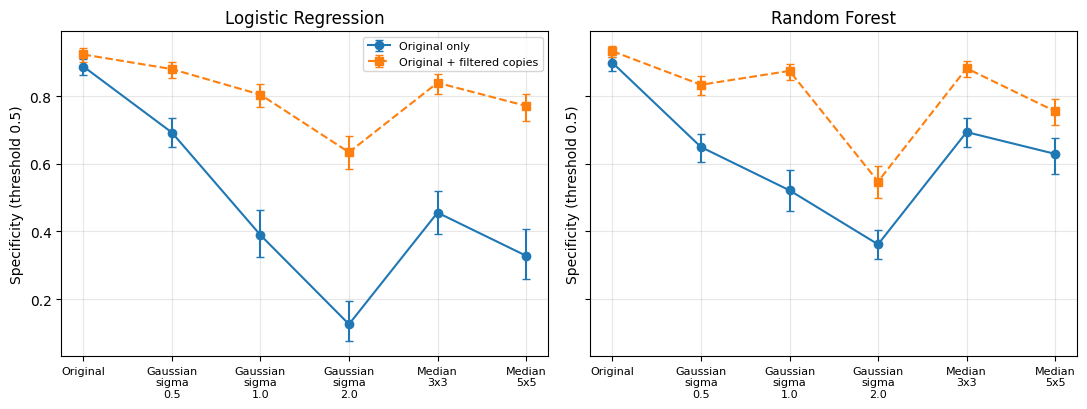

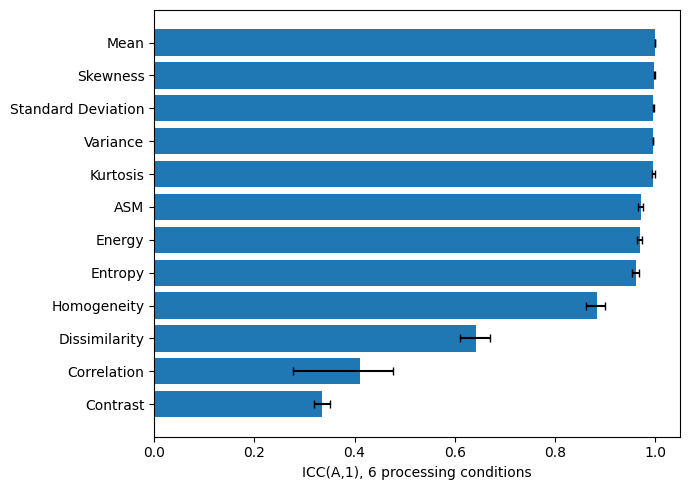

In [56]:
import matplotlib.pyplot as plt
order_c = CONDS
# Figure A: specificity vs filter strength, baseline vs augmented
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    for label, mk in [("Original only", "o-"), ("Original + filtered copies", "s--")]:
        d = final_results[(final_results["Model"] == name) & (final_results["Training"] == label)
                          & (final_results["Metric"] == "Specificity")].set_index("Test condition").loc[order_c]
        ax.errorbar(range(len(order_c)), d["Estimate"], yerr=[d["Estimate"] - d["CI low"], d["CI high"] - d["Estimate"]],
                    fmt=mk, capsize=3, label=label)
    ax.set_xticks(range(len(order_c))); ax.set_xticklabels([c.replace("_", "\n") for c in order_c], fontsize=8)
    ax.set_title(name); ax.set_ylabel("Specificity (threshold 0.5)"); ax.grid(alpha=.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("/kaggle/working/Figure_A_specificity_dose_response.png", dpi=300); plt.show()

# Figure B: ICC(A,1) with CI
ft = feat_table.sort_values("ICC(A,1) agreement")
plt.figure(figsize=(7, 5))
plt.barh(ft["Feature"], ft["ICC(A,1) agreement"],
         xerr=[ft["ICC(A,1) agreement"] - ft["ICC(A,1) CI low"], ft["ICC(A,1) CI high"] - ft["ICC(A,1) agreement"]], capsize=3)
plt.xlabel("ICC(A,1), 6 processing conditions"); plt.tight_layout()
plt.savefig("/kaggle/working/Figure_B_feature_ICC.png", dpi=300); plt.show()


In [57]:
# ===== PATCH 6: do the FRAGILE features cause the specificity drop? (feature-family test) =====
# Uses variables from earlier patch cells: X, y, groups, CONDS, make_model, metrics, boot_idx, feat_table
STABLE  = feat_table.loc[feat_table["ICC(A,1) agreement"] >= 0.90, "Feature"].tolist()
FRAGILE = feat_table.loc[feat_table["ICC(A,1) agreement"] <  0.90, "Feature"].tolist()
print("Stable  :", STABLE)
print("Fragile :", FRAGILE)

def oof_subset(model_name, cols):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    A = {c: X[c][cols].to_numpy() for c in CONDS}
    P = {c: np.zeros(len(y)) for c in CONDS}
    for tr, te in cv.split(A["Original"], y, groups):
        m = make_model(model_name).fit(A["Original"][tr], y[tr])     # trained on Original only
        for c in CONDS:
            P[c][te] = m.predict_proba(A[c][te])[:, 1]
    return P

fam_rows = []
assert len(STABLE) > 0 and len(FRAGILE) > 0, "Need at least one stable and one fragile feature"
for model_name in ["Logistic Regression", "Random Forest"]:
    for fam, cols in [("Stable features only", STABLE), ("Fragile features only", FRAGILE), ("All 12 features", FEATS)]:
        P = oof_subset(model_name, cols)
        pt = {c: metrics(y, P[c]) for c in CONDS}
        bt = {c: np.array([metrics(y[b], P[c][b]) for b in boot_idx]) for c in ["Original", "Gaussian_sigma_1.0", "Median_3x3"]}
        for c in ["Gaussian_sigma_1.0", "Median_3x3"]:
            d = pt[c][2] - pt["Original"][2]
            lo, hi = np.percentile(bt[c][:, 2] - bt["Original"][:, 2], [2.5, 97.5])
            fam_rows.append({"Model": model_name, "Feature set": fam, "Filter": c,
                             "AUC Original": pt["Original"][0], "AUC filtered": pt[c][0],
                             "Spec Original": pt["Original"][2], "Spec filtered": pt[c][2],
                             "Spec change": d, "CI low": lo, "CI high": hi})
family_table = pd.DataFrame(fam_rows)
family_table.to_csv("/kaggle/working/FINAL_feature_family_test.csv", index=False)
display(family_table.round(3))



Stable  : ['Mean', 'Skewness', 'Standard Deviation', 'Variance', 'Kurtosis', 'ASM', 'Energy', 'Entropy']
Fragile : ['Homogeneity', 'Dissimilarity', 'Correlation', 'Contrast']


,Model,Feature set,Filter,AUC Original,AUC filtered,Spec Original,Spec filtered,Spec change,CI low,CI high
0,Logistic Regression,Stable features only,Gaussian_sigma_1.0,0.897,0.896,0.835,0.770,-0.065,-0.080,-0.051
1,Logistic Regression,Stable features only,Median_3x3,0.897,0.896,0.835,0.836,0.001,0.000,0.003
2,Logistic Regression,Fragile features only,Gaussian_sigma_1.0,0.897,0.872,0.849,0.543,-0.306,-0.358,-0.263
3,Logistic Regression,Fragile features only,Median_3x3,0.897,0.892,0.849,0.896,0.047,0.035,0.062
4,Logistic Regression,All 12 features,Gaussian_sigma_1.0,0.937,0.926,0.887,0.389,-0.498,-0.560,-0.429
5,Logistic Regression,All 12 features,Median_3x3,0.937,0.921,0.887,0.456,-0.432,-0.489,-0.374
6,Random Forest,Stable features only,Gaussian_sigma_1.0,0.919,0.917,0.855,0.795,-0.060,-0.078,-0.042
7,Random Forest,Stable features only,Median_3x3,0.919,0.918,0.855,0.881,0.026,0.012,0.038
8,Random Forest,Fragile features only,Gaussian_sigma_1.0,0.910,0.819,0.860,0.394,-0.466,-0.520,-0.402
9,Random Forest,Fragile features only,Median_3x3,0.910,0.869,0.860,0.848,-0.012,-0.030,0.007


In [58]:
from PIL import Image
import os
sizes, modes = set(), set()
for f in os.listdir(image_folder):
    im = Image.open(os.path.join(image_folder, f))
    sizes.add(im.size); modes.add(im.mode)
print(sizes, modes)

{(240, 240)} {'RGB'}
